### Capstone Project - Hpid Lenka Kramova

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as stats
import statsmodels.api as sm
from scipy import stats
from matplotlib import pyplot
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from scipy.stats import shapiro
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn import preprocessing as preproc
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold, cross_val_score
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import sklearn.preprocessing as pre
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.stats.api as sms
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.anova import anova_lm

In [2]:
df1 = pd.read_csv("hpcp_2022_12_31.csv")
df2 = pd.read_csv("hpcp_2023_12_31.csv")
df3 = pd.read_csv("hpcp_2024_12_31.csv")

In [3]:
combined = pd.concat([df1, df2, df3], ignore_index=True)

combined = pd.concat([df1, df2, df3], 
                     ignore_index=True,
                     axis=0)

### Data Preparation

#### Data Structure Overview

In [4]:
combined.head(10)

,REPORTINGPERIOD,SERIES_KEY,OBSERVATION,CONFIDENTIALITY_FLAG,UNITS,FREQ,FREQ_DESC,REF_AREA,REF_AREA_DESC,COUNT_AREA,...,CRD_FNCTN,CRD_FNCTN_DESC,SCA,SCA_DESC,FRD_TYP,FRD_TYP_DESC,TRANSFORMATION,TRANSFORMATION_DESC,UNIT_MEASURE,UNIT_MEASURE_DESC
0,2022-12-31,PCP.H.IE.G1.AT.CP0.1._T._T.PCS_ALL._Z._X._Z.N.EUR,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,EUR,Euro
1,2022-12-31,PCP.H.IE.G1.AT.CP0.1._T._T.PCS_ALL._Z._X._Z.N.PN,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,PN,Pure number
2,2022-12-31,PCP.H.IE.G1.AT.CP0.1._T._T.PCS_ALL._Z._X.F.N.EUR,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,EUR,Euro
3,2022-12-31,PCP.H.IE.G1.AT.CP0.1._T._T.PCS_ALL._Z._X.F.N.PN,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,PN,Pure number
4,2022-12-31,PCP.H.IE.G1.AT.CP0.1.1000._T.PCS_ALL._Z._X._Z....,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,EUR,Euro
5,2022-12-31,PCP.H.IE.G1.AT.CP0.1.1000._T.PCS_ALL._Z._X._Z....,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,PN,Pure number
6,2022-12-31,PCP.H.IE.G1.AT.CP0.1.1000._T.PCS_ALL._Z._X.F.N...,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,EUR,Euro
7,2022-12-31,PCP.H.IE.G1.AT.CP0.1.1000._T.PCS_ALL._Z._X.F.N.PN,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,PN,Pure number
8,2022-12-31,PCP.H.IE.G1.AT.CP0.1.1000.R.PCS_ALL._Z._X._Z.N...,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,EUR,Euro
9,2022-12-31,PCP.H.IE.G1.AT.CP0.1.1000.R.PCS_ALL._Z._X._Z.N.PN,NaN,C,Millions,H,Half-yearly,IE,Ireland,G1,...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,PN,Pure number


In [5]:
combined.tail(10)

,REPORTINGPERIOD,SERIES_KEY,OBSERVATION,CONFIDENTIALITY_FLAG,UNITS,FREQ,FREQ_DESC,REF_AREA,REF_AREA_DESC,COUNT_AREA,...,CRD_FNCTN,CRD_FNCTN_DESC,SCA,SCA_DESC,FRD_TYP,FRD_TYP_DESC,TRANSFORMATION,TRANSFORMATION_DESC,UNIT_MEASURE,UNIT_MEASURE_DESC
226668,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.11._X.F.N.EUR,NaN,C,Millions,H,Half-yearly,IE,Ireland,W2,...,11,Debit card,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,EUR,Euro
226669,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.11._X.F.N.PN,NaN,C,Millions,H,Half-yearly,IE,Ireland,W2,...,11,Debit card,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,PN,Pure number
226670,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.12._X._Z.N.EUR,NaN,C,Millions,H,Half-yearly,IE,Ireland,W2,...,12,Delayed debit card,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,EUR,Euro
226671,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.12._X._Z.N.PN,NaN,C,Millions,H,Half-yearly,IE,Ireland,W2,...,12,Delayed debit card,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,PN,Pure number
226672,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.12._X.F.N.EUR,0.000000,F,Millions,H,Half-yearly,IE,Ireland,W2,...,12,Delayed debit card,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,EUR,Euro
226673,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.12._X.F.N.PN,0.000000,F,Millions,H,Half-yearly,IE,Ireland,W2,...,12,Delayed debit card,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,PN,Pure number
226674,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.13._X._Z.N.EUR,81.009777,F,Millions,H,Half-yearly,IE,Ireland,W2,...,13,Credit card,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,EUR,Euro
226675,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.13._X._Z.N.PN,0.488061,F,Millions,H,Half-yearly,IE,Ireland,W2,...,13,Credit card,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,PN,Pure number
226676,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.13._X.F.N.EUR,NaN,C,Millions,H,Half-yearly,IE,Ireland,W2,...,13,Credit card,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,EUR,Euro
226677,2024-06-30,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.13._X.F.N.PN,NaN,C,Millions,H,Half-yearly,IE,Ireland,W2,...,13,Credit card,_X,Not allocated/unspecified,F,Fraud,N,Non transformed data,PN,Pure number


In [6]:
combined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   REPORTINGPERIOD       226678 non-null  object 
 1   SERIES_KEY            226678 non-null  object 
 2   OBSERVATION           92224 non-null   float64
 3   CONFIDENTIALITY_FLAG  226678 non-null  object 
 4   UNITS                 226678 non-null  object 
 5   FREQ                  226678 non-null  object 
 6   FREQ_DESC             226678 non-null  object 
 7   REF_AREA              226678 non-null  object 
 8   REF_AREA_DESC         226678 non-null  object 
 9   COUNT_AREA            226678 non-null  object 
 10  COUNT_AREA_DESC       226678 non-null  object 
 11  TRMNL_LCTN            226678 non-null  object 
 12  TRMNL_LCTN_DESC       226678 non-null  object 
 13  TYP_TRNSCTN           226678 non-null  object 
 14  TYP_TRNSCTN_DESC      226678 non-null  object 
 15  

In [7]:
combined.dtypes.value_counts()

object     31
float64     1
int64       1
Name: count, dtype: int64

In [8]:
combined.shape

(226678, 33)

In [9]:
combined.describe()

,OBSERVATION,RL_TRNSCTN
count,92224.000000,226678.000000
mean,179.348446,1.403559
std,1823.930611,0.490612
min,0.000000,1.000000
25%,0.000000,1.000000
50%,0.000582,1.000000
75%,0.650901,2.000000
max,72302.154538,2.000000


In [10]:
combined.describe(include=object)

,REPORTINGPERIOD,SERIES_KEY,CONFIDENTIALITY_FLAG,UNITS,FREQ,FREQ_DESC,REF_AREA,REF_AREA_DESC,COUNT_AREA,COUNT_AREA_DESC,...,CRD_FNCTN,CRD_FNCTN_DESC,SCA,SCA_DESC,FRD_TYP,FRD_TYP_DESC,TRANSFORMATION,TRANSFORMATION_DESC,UNIT_MEASURE,UNIT_MEASURE_DESC
count,226678,226678,226678,226678,226678,226678,226678,226678,226678,226678,...,226678,226678,226678,226678,226678,226678,226678,226678,226678,226678
unique,6,39544,2,1,1,1,1,1,5,5,...,4,4,12,12,8,8,1,1,2,2
top,2024-12-31,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL.13._X.F.N.PN,C,Millions,H,Half-yearly,IE,Ireland,W0,"World (all entities, including reference area,...",...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,EUR,Euro
freq,38552,6,134454,226678,226678,226678,226678,226678,53568,53568,...,179920,179920,136940,136940,120916,120916,226678,226678,113339,113339


In [11]:
combined.mean(numeric_only=True)

OBSERVATION    179.348446
RL_TRNSCTN       1.403559
dtype: float64

In [12]:
combined.median(numeric_only=True)

OBSERVATION    0.000582
RL_TRNSCTN     1.000000
dtype: float64

In [13]:
combined.mode()

,REPORTINGPERIOD,SERIES_KEY,OBSERVATION,CONFIDENTIALITY_FLAG,UNITS,FREQ,FREQ_DESC,REF_AREA,REF_AREA_DESC,COUNT_AREA,...,CRD_FNCTN,CRD_FNCTN_DESC,SCA,SCA_DESC,FRD_TYP,FRD_TYP_DESC,TRANSFORMATION,TRANSFORMATION_DESC,UNIT_MEASURE,UNIT_MEASURE_DESC
0,2024-12-31,PCP.H.IE.G1.AT.CP0.1.1000.R.PCS_ALL._Z._X._Z.N...,0.0,C,Millions,H,Half-yearly,IE,Ireland,W0,...,_Z,Not applicable,_X,Not allocated/unspecified,_Z,Not applicable,N,Non transformed data,EUR,Euro
1,NaN,PCP.H.IE.G1.AT.CP0.1.1000.R.PCS_ALL._Z._X._Z.N.PN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PN,Pure number
2,NaN,PCP.H.IE.G1.AT.CP0.1.1000._T.PCS_ALL._Z._X._Z....,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,PCP.H.IE.G1.AT.CP0.1.1000._T.PCS_ALL._Z._X._Z....,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,PCP.H.IE.G1.AT.CP0.1.2000.NR.PCS_ALL.11._X._Z....,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36161,NaN,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL._Z._X.F15.N.PN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36162,NaN,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL._Z._X.F3.N.EUR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36163,NaN,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL._Z._X.F3.N.PN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36164,NaN,PCP.H.IE.W2.W2.CW1.1._T._T.PCS_ALL._Z._X._Z.N.EUR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
combined.max(numeric_only=True)

OBSERVATION    72302.154538
RL_TRNSCTN         2.000000
dtype: float64

In [15]:
combined.min(numeric_only=True)

OBSERVATION    0.0
RL_TRNSCTN     1.0
dtype: float64

In [16]:
combined.isnull().sum()

REPORTINGPERIOD              0
SERIES_KEY                   0
OBSERVATION             134454
CONFIDENTIALITY_FLAG         0
UNITS                        0
FREQ                         0
FREQ_DESC                    0
REF_AREA                     0
REF_AREA_DESC                0
COUNT_AREA                   0
COUNT_AREA_DESC              0
TRMNL_LCTN                   0
TRMNL_LCTN_DESC              0
TYP_TRNSCTN                  0
TYP_TRNSCTN_DESC             0
RL_TRNSCTN                   0
RL_TRNSCTN_DESC              0
INTTN_CHNNL                  0
INTTN_CHNNL_DESC             0
RMT_INTTN                    0
RMT_INTTN_DESC               0
PYMNT_SCHM                   0
PYMNT_SCHM_DESC              0
CRD_FNCTN                    0
CRD_FNCTN_DESC               0
SCA                          0
SCA_DESC                     0
FRD_TYP                      0
FRD_TYP_DESC                 0
TRANSFORMATION               0
TRANSFORMATION_DESC          0
UNIT_MEASURE                 0
UNIT_MEA

In [17]:
combined.duplicated().sum()

np.int64(0)

In [18]:
combined["REPORTINGPERIOD"].unique()

array(['2022-12-31', '2022-06-30', '2023-12-31', '2023-06-30',
       '2024-12-31', '2024-06-30'], dtype=object)

In [19]:
combined["SERIES_KEY"].unique()

array(['PCP.H.IE.G1.AT.CP0.1._T._T.PCS_ALL._Z._X._Z.N.EUR',
       'PCP.H.IE.G1.AT.CP0.1._T._T.PCS_ALL._Z._X._Z.N.PN',
       'PCP.H.IE.G1.AT.CP0.1._T._T.PCS_ALL._Z._X.F.N.EUR', ...,
       'PCP.H.IE.W2.SK.CP0.2.2000.NR.PCS_ALL.11._X.F.N.PN',
       'PCP.H.IE.W2.SK.CP0.2.2000.NR.PCS_ALL.12._X._Z.N.EUR',
       'PCP.H.IE.W2.SK.CP0.2.2000.NR.PCS_ALL.12._X._Z.N.PN'], dtype=object)

In [20]:
combined["OBSERVATION"].unique()

array([         nan, 241.31619162,   2.485848  , ...,  35.125247  ,
        81.00977691,   0.488061  ])

In [21]:
combined["CONFIDENTIALITY_FLAG"].unique()

array(['C', 'F'], dtype=object)

In [22]:
combined["UNITS"].unique()

array(['Millions'], dtype=object)

In [23]:
combined["FREQ"].unique()

array(['H'], dtype=object)

In [24]:
combined["FREQ_DESC"].unique()

array(['Half-yearly'], dtype=object)

In [25]:
combined["REF_AREA"].unique()

array(['IE'], dtype=object)

In [26]:
combined["REF_AREA_DESC"].unique()

array(['Ireland'], dtype=object)

In [27]:
combined["COUNT_AREA"].unique()

array(['G1', 'G3', 'W0', 'W1', 'W2'], dtype=object)

In [28]:
combined["COUNT_AREA_DESC"].unique()

array(['Extra EEA',
       'Other EEA countries (all countries excluding the reference area)',
       'World (all entities, including reference area, including IO)',
       'Rest of the World', 'Domestic (home or reference area)'],
      dtype=object)

In [29]:
combined["TRMNL_LCTN"].unique()

array(['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR',
       'G1', 'GR', 'HR', 'HU', 'IS', 'IT', 'LI', 'LT', 'LU', 'LV', 'MT',
       'NL', 'NO', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK', 'W2'], dtype=object)

In [30]:
combined["TRMNL_LCTN_DESC"].unique()

array(['Austria', 'Belgium', 'Bulgaria', 'Cyprus', 'Czech Republic',
       'Germany', 'Denmark', 'Estonia', 'Spain', 'Finland', 'France',
       'Extra EEA', 'Greece', 'Croatia', 'Hungary', 'Iceland', 'Italy',
       'Liechtenstein', 'Lithuania', 'Luxembourg', 'Latvia', 'Malta',
       'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Sweden',
       'Slovenia', 'Slovakia', 'Domestic (home or reference area)'],
      dtype=object)

In [31]:
combined["TYP_TRNSCTN"].unique()

array(['CP0', 'CP1', 'CP11', 'CW1'], dtype=object)

In [32]:
combined["TYP_TRNSCTN_DESC"].unique()

array(['Card payments', 'Card payments (Contactless)',
       'Card payments (NFC)', 'Cash withdrawals using cards'],
      dtype=object)

In [33]:
combined["RL_TRNSCTN"].unique()

array([1, 2])

In [34]:
combined["RL_TRNSCTN_DESC"].unique()

array(['Payer`s PSP', 'Payee`s PSP'], dtype=object)

In [35]:
combined["INTTN_CHNNL"].unique()

array(['_T', '1000', '2000', '2223', '2229', '2230', '2221', '2231'],
      dtype=object)

In [36]:
combined["INTTN_CHNNL_DESC"].unique()

array(['All', 'Non-electronic', 'Electronic', 'EFTPOS',
       'Other electronic channel than ATM, EFTPOS',
       'Mobile payment solution', 'ATM', 'P2P mobile payment solution'],
      dtype=object)

In [37]:
combined["RMT_INTTN"].unique()

array(['_T', 'R', 'NR'], dtype=object)

In [38]:
combined["RMT_INTTN_DESC"].unique()

array(['Initiated either via remote or non-remote channel',
       'Intiated via remote channel', 'Initiated via non-remote channel'],
      dtype=object)

In [39]:
combined["PYMNT_SCHM"].unique()

array(['PCS_ALL'], dtype=object)

In [40]:
combined["PYMNT_SCHM_DESC"].unique()

array(['ALL payment card schemes'], dtype=object)

In [41]:
combined["CRD_FNCTN"].unique()

array(['_Z', '11', '12', '13'], dtype=object)

In [42]:
combined["CRD_FNCTN_DESC"].unique()

array(['Not applicable', 'Debit card', 'Delayed debit card',
       'Credit card'], dtype=object)

In [43]:
combined["SCA"].unique()

array(['_X', '100', '200', '202', '206', '210', '201', '205', '208',
       '209', '207', '204'], dtype=object)

In [44]:
combined["SCA_DESC"].unique()

array(['Not allocated/unspecified', 'SCA used', 'Non-SCA used',
       'Non-SCA used: reason is contactless low value',
       'Non-SCA used: reason is unattended terminals for transport fares or parking fees',
       'Non-SCA used: reason is others',
       'Non-SCA used: reason is low value',
       'Non-SCA used: reason is recurring transaction',
       'Non-SCA used: reason is transaction risk analysis',
       'Non-SCA used: reason is merchant initiated transaction (MIT)',
       'Non-SCA used: reason is secure corporate payment processes and protocols',
       'Non-SCA used: reason is trusted beneficiaries'], dtype=object)

In [45]:
combined["FRD_TYP"].unique()

array(['_Z', 'F', 'F1', 'F10', 'F11', 'F12', 'F15', 'F3'], dtype=object)

In [46]:
combined["FRD_TYP_DESC"].unique()

array(['Not applicable', 'Fraud',
       'Issuance of a payment order by the fraudster',
       'Lost or Stolen card', 'Card Not Received', 'Counterfeit card',
       'Other issuance of payment orders by the fraudster',
       'Manipulation of the payer'], dtype=object)

In [47]:
combined["TRANSFORMATION"].unique()

array(['N'], dtype=object)

In [48]:
combined["TRANSFORMATION_DESC"].unique()

array(['Non transformed data'], dtype=object)

In [49]:
combined["UNIT_MEASURE"].unique()

array(['EUR', 'PN'], dtype=object)

In [50]:
combined["UNIT_MEASURE_DESC"].unique()

array(['Euro', 'Pure number'], dtype=object)

#### Data distribution check

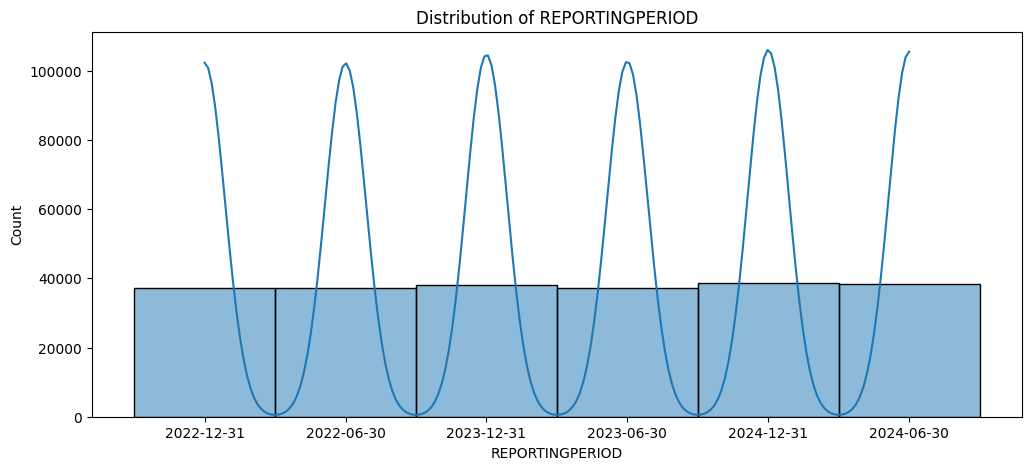

In [51]:
plt.figure(figsize=(12,5))
sns.histplot(combined["REPORTINGPERIOD"], bins=10, kde=True)
plt.title("Distribution of REPORTINGPERIOD")
plt.xlabel("REPORTINGPERIOD")
plt.show()

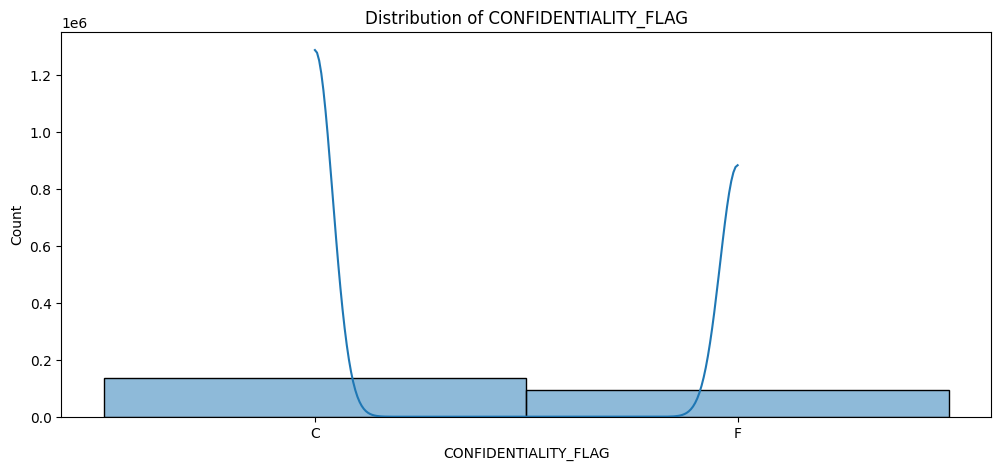

In [52]:
plt.figure(figsize=(12,5))
sns.histplot(combined["CONFIDENTIALITY_FLAG"], bins=10, kde=True)
plt.title("Distribution of CONFIDENTIALITY_FLAG")
plt.xlabel("CONFIDENTIALITY_FLAG")
plt.show()

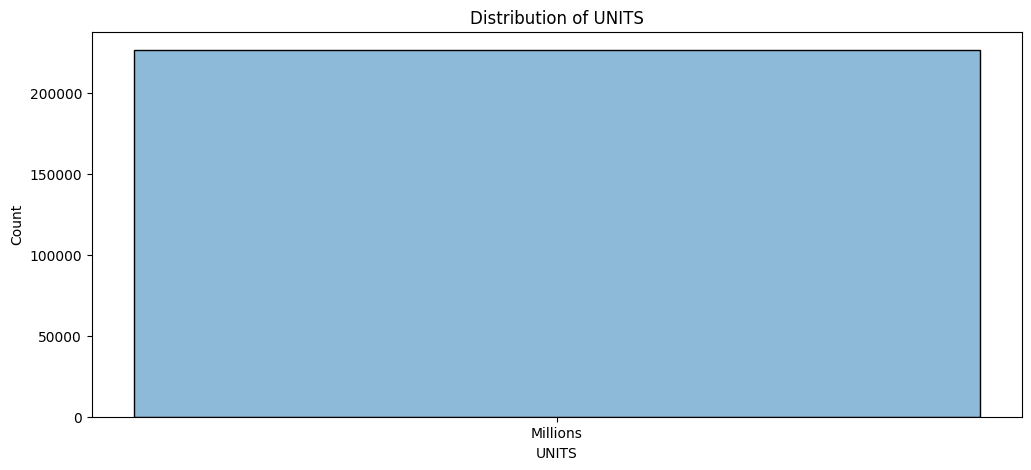

In [53]:
plt.figure(figsize=(12,5))
sns.histplot(combined["UNITS"], bins=10, kde=True)
plt.title("Distribution of UNITS")
plt.xlabel("UNITS")
plt.show()

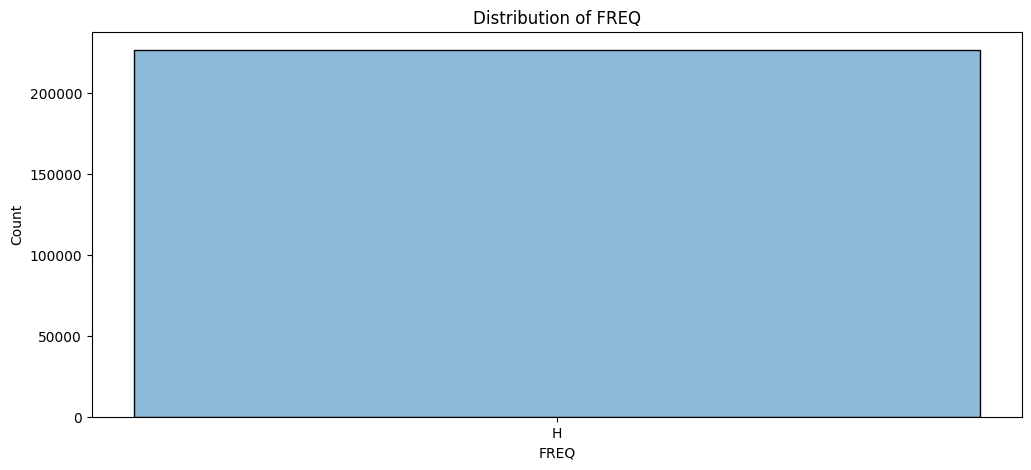

In [54]:
plt.figure(figsize=(12,5))
sns.histplot(combined["FREQ"], bins=10, kde=True)
plt.title("Distribution of FREQ")
plt.xlabel("FREQ")
plt.show()

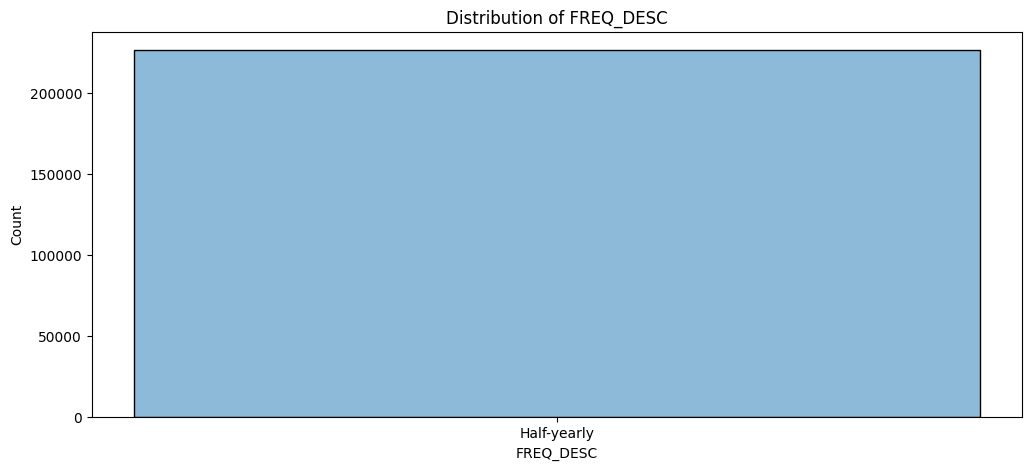

In [55]:
plt.figure(figsize=(12,5))
sns.histplot(combined["FREQ_DESC"], bins=10, kde=True)
plt.title("Distribution of FREQ_DESC")
plt.xlabel("FREQ_DESC")
plt.show()

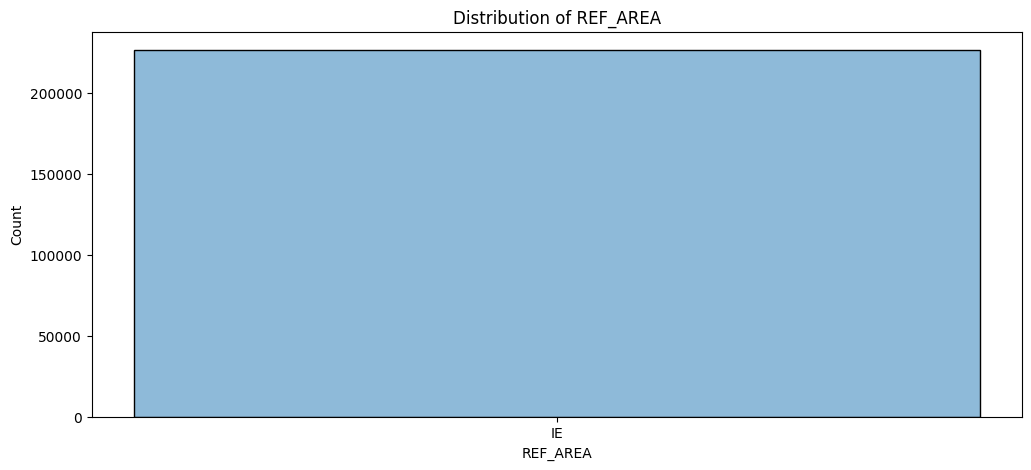

In [56]:
plt.figure(figsize=(12,5))
sns.histplot(combined["REF_AREA"], bins=10, kde=True)
plt.title("Distribution of REF_AREA")
plt.xlabel("REF_AREA")
plt.show()

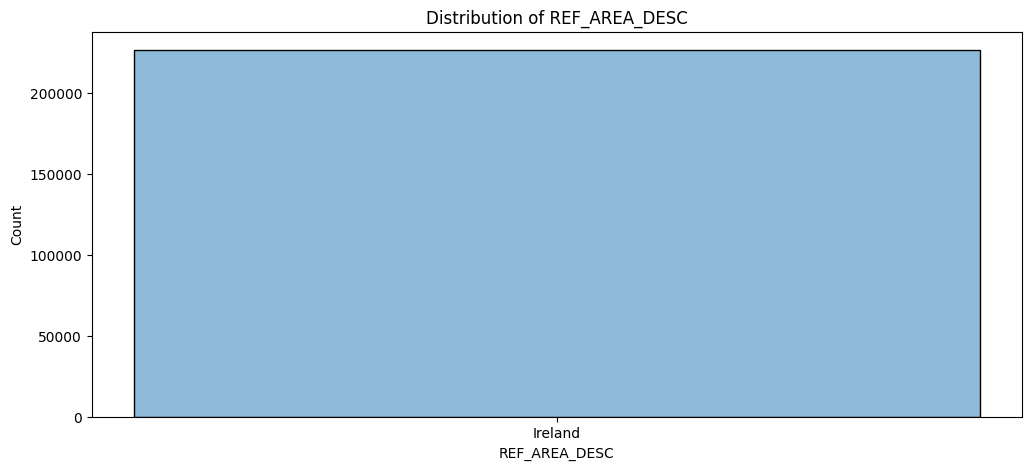

In [57]:
plt.figure(figsize=(12,5))
sns.histplot(combined["REF_AREA_DESC"], bins=10, kde=True)
plt.title("Distribution of REF_AREA_DESC")
plt.xlabel("REF_AREA_DESC")
plt.show()

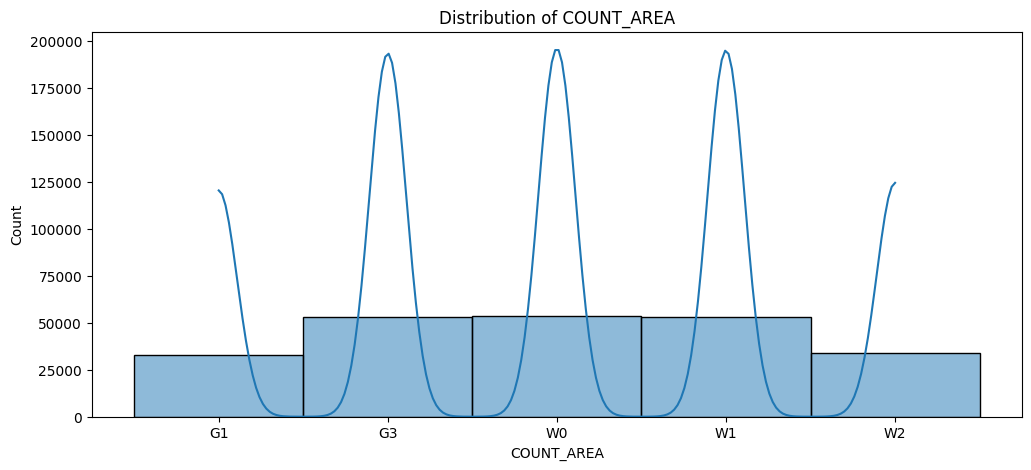

In [58]:
plt.figure(figsize=(12,5))
sns.histplot(combined["COUNT_AREA"], bins=10, kde=True)
plt.title("Distribution of COUNT_AREA")
plt.xlabel("COUNT_AREA")
plt.show()

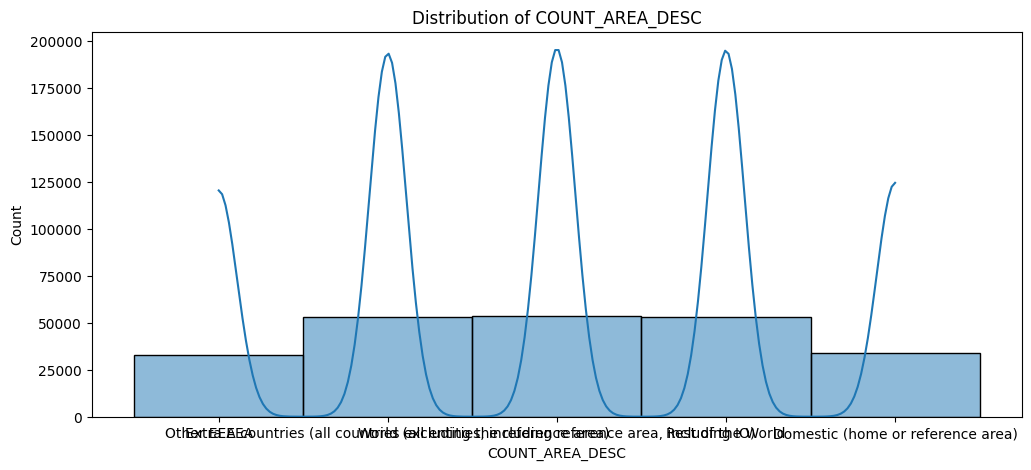

In [59]:
plt.figure(figsize=(12,5))
sns.histplot(combined["COUNT_AREA_DESC"], bins=10, kde=True)
plt.title("Distribution of COUNT_AREA_DESC")
plt.xlabel("COUNT_AREA_DESC")
plt.show()

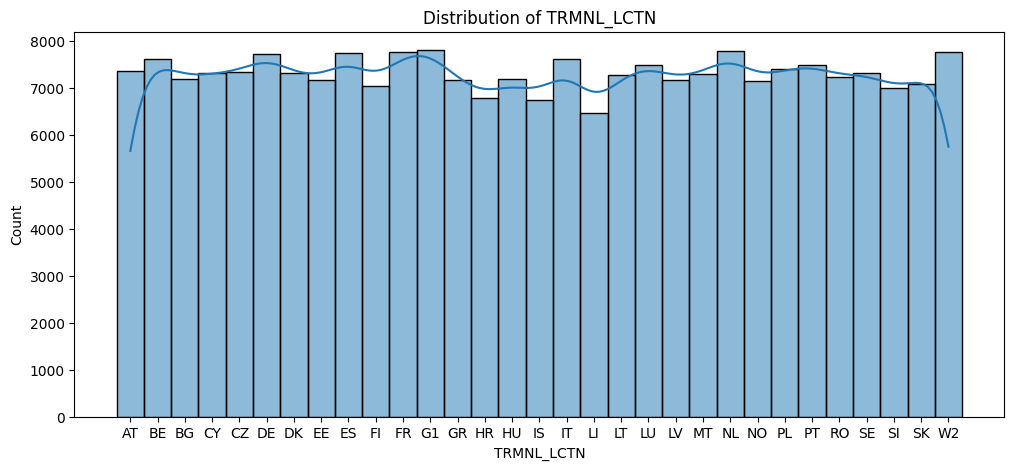

In [60]:
plt.figure(figsize=(12,5))
sns.histplot(combined["TRMNL_LCTN"], bins=10, kde=True)
plt.title("Distribution of TRMNL_LCTN")
plt.xlabel("TRMNL_LCTN")
plt.show()

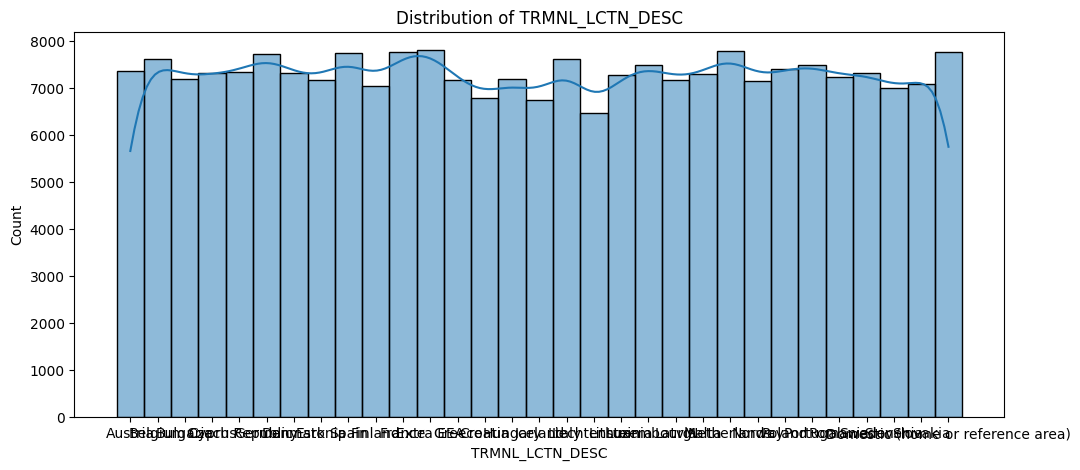

In [61]:
plt.figure(figsize=(12,5))
sns.histplot(combined["TRMNL_LCTN_DESC"], bins=10, kde=True)
plt.title("Distribution of TRMNL_LCTN_DESC")
plt.xlabel("TRMNL_LCTN_DESC")
plt.show()

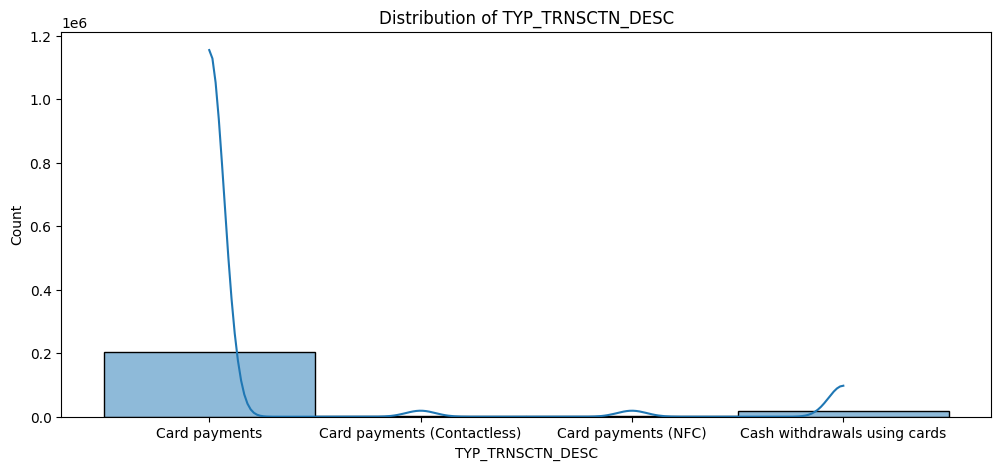

In [62]:
plt.figure(figsize=(12,5))
sns.histplot(combined["TYP_TRNSCTN_DESC"], bins=10, kde=True)
plt.title("Distribution of TYP_TRNSCTN_DESC")
plt.xlabel("TYP_TRNSCTN_DESC")
plt.show()

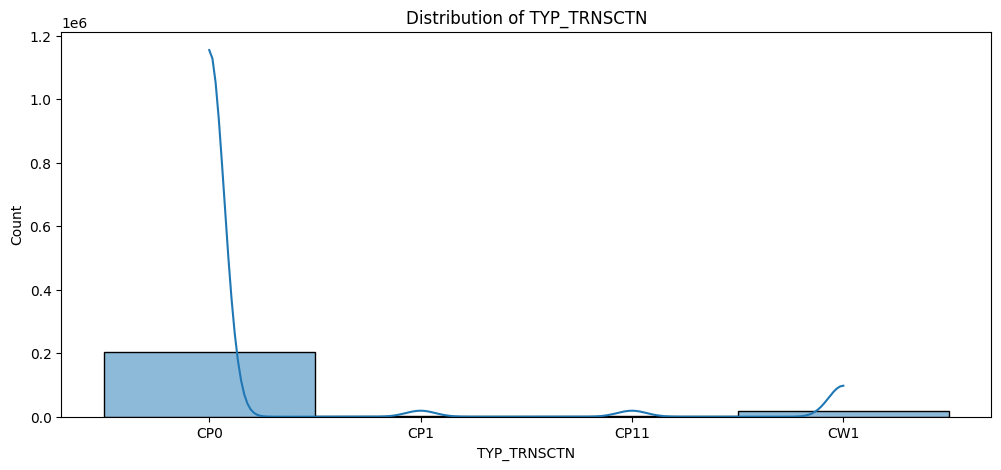

In [63]:
plt.figure(figsize=(12,5))
sns.histplot(combined["TYP_TRNSCTN"], bins=10, kde=True)
plt.title("Distribution of TYP_TRNSCTN")
plt.xlabel("TYP_TRNSCTN")
plt.show()

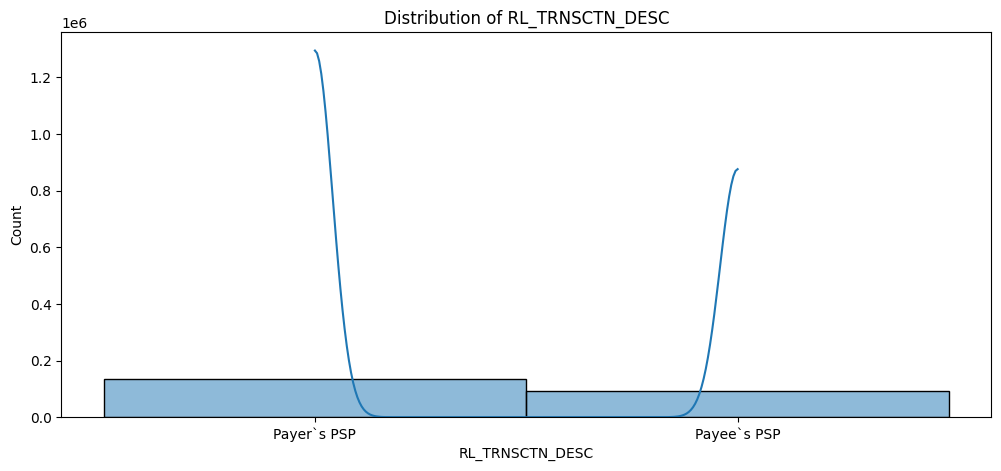

In [64]:
plt.figure(figsize=(12,5))
sns.histplot(combined["RL_TRNSCTN_DESC"], bins=10, kde=True)
plt.title("Distribution of RL_TRNSCTN_DESC")
plt.xlabel("RL_TRNSCTN_DESC")
plt.show()

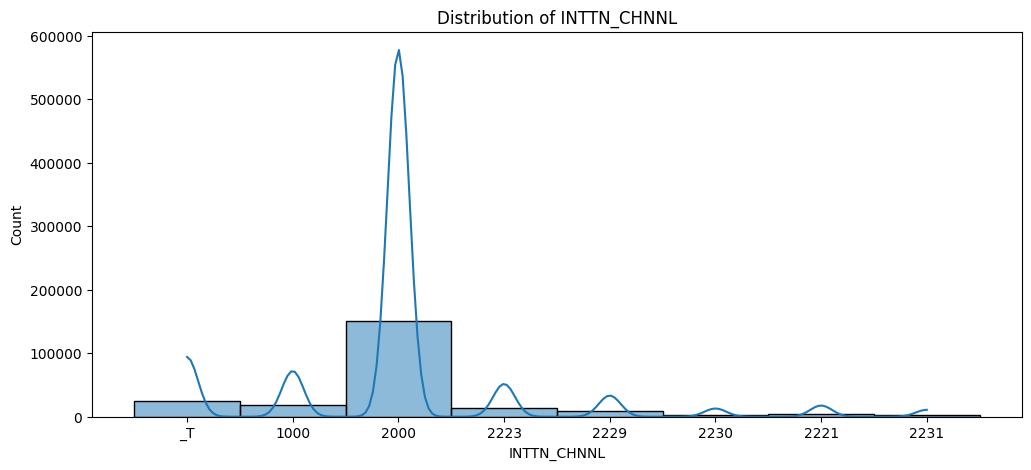

In [65]:
plt.figure(figsize=(12,5))
sns.histplot(combined["INTTN_CHNNL"], bins=10, kde=True)
plt.title("Distribution of INTTN_CHNNL")
plt.xlabel("INTTN_CHNNL")
plt.show()

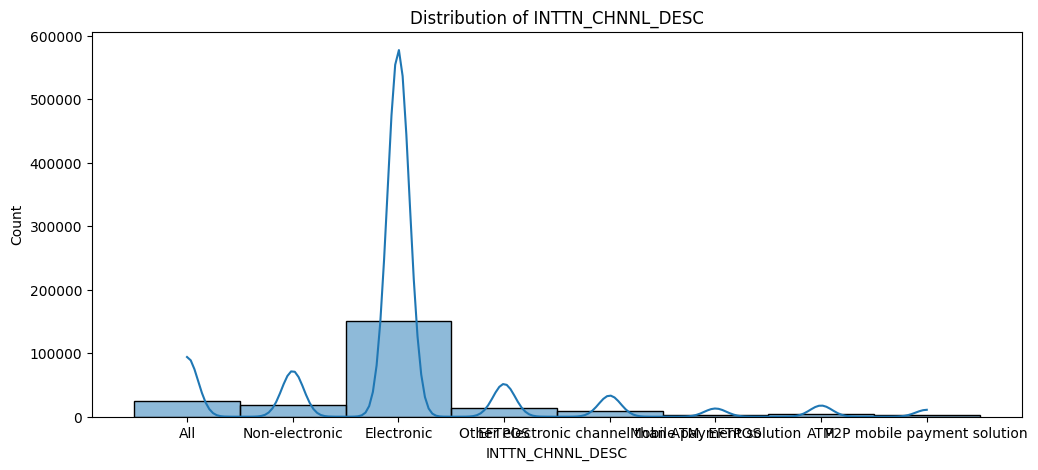

In [66]:
plt.figure(figsize=(12,5))
sns.histplot(combined["INTTN_CHNNL_DESC"], bins=10, kde=True)
plt.title("Distribution of INTTN_CHNNL_DESC")
plt.xlabel("INTTN_CHNNL_DESC")
plt.show()

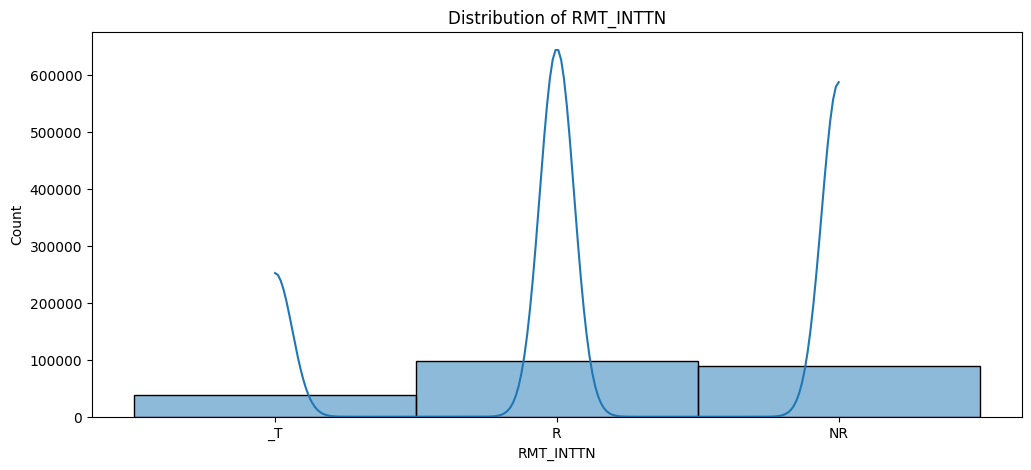

In [67]:
plt.figure(figsize=(12,5))
sns.histplot(combined["RMT_INTTN"], bins=10, kde=True)
plt.title("Distribution of RMT_INTTN")
plt.xlabel("RMT_INTTN")
plt.show()

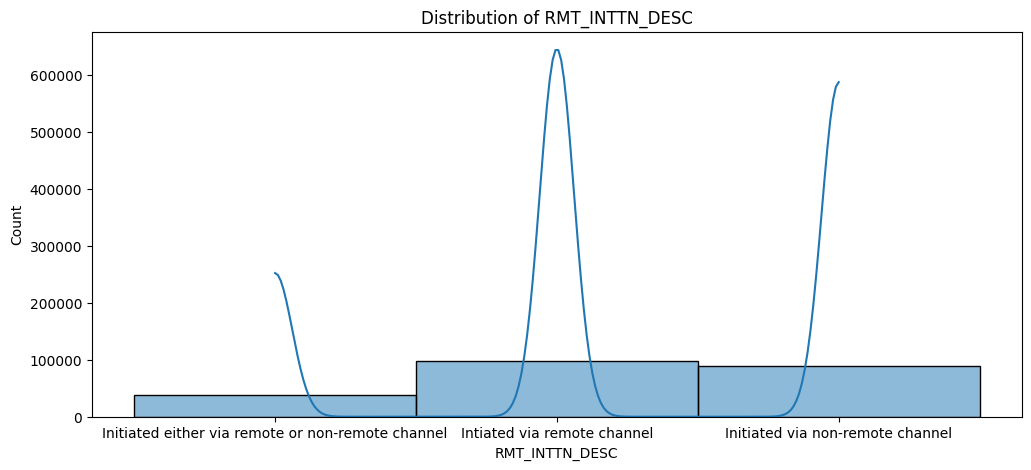

In [68]:
plt.figure(figsize=(12,5))
sns.histplot(combined["RMT_INTTN_DESC"], bins=10, kde=True)
plt.title("Distribution of RMT_INTTN_DESC")
plt.xlabel("RMT_INTTN_DESC")
plt.show()

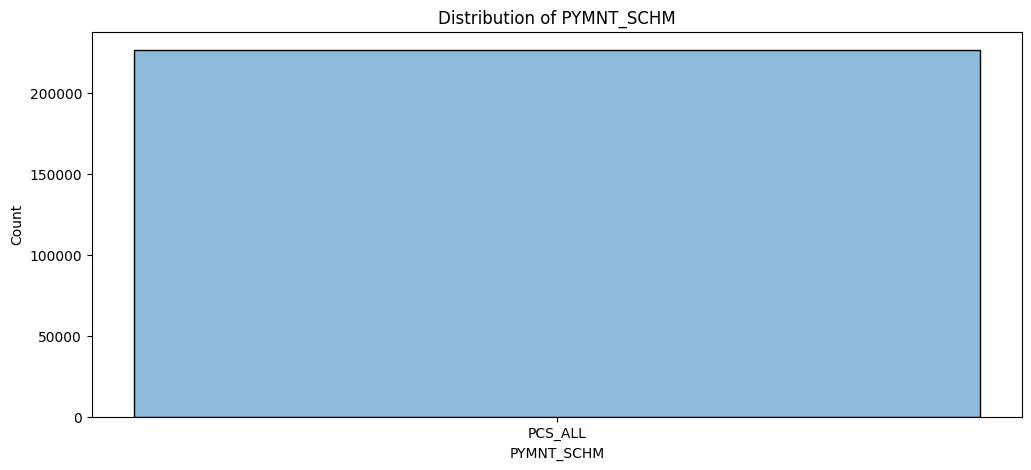

In [69]:
plt.figure(figsize=(12,5))
sns.histplot(combined["PYMNT_SCHM"], bins=10, kde=True)
plt.title("Distribution of PYMNT_SCHM")
plt.xlabel("PYMNT_SCHM")
plt.show()

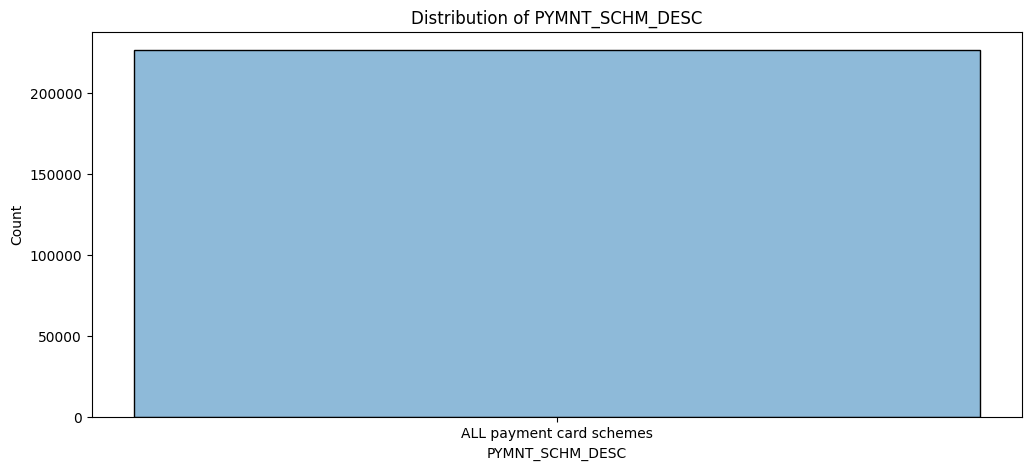

In [70]:
plt.figure(figsize=(12,5))
sns.histplot(combined["PYMNT_SCHM_DESC"], bins=10, kde=True)
plt.title("Distribution of PYMNT_SCHM_DESC")
plt.xlabel("PYMNT_SCHM_DESC")
plt.show()

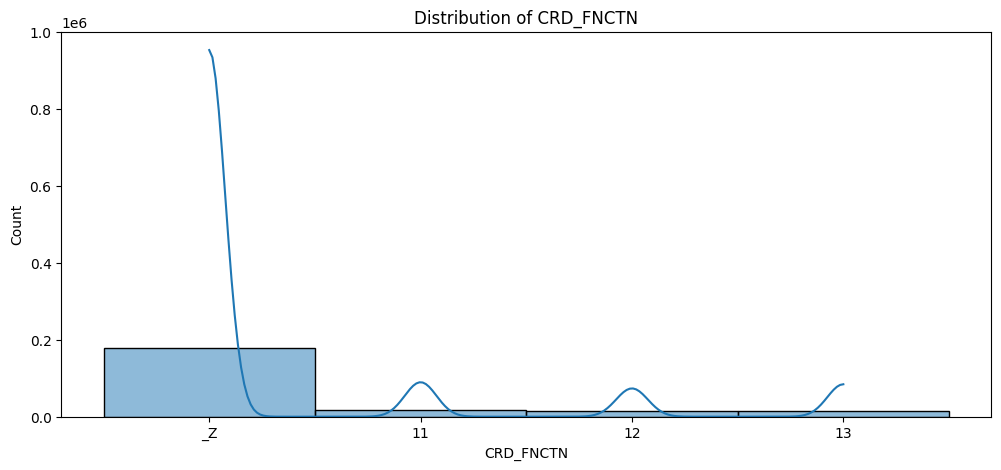

In [71]:
plt.figure(figsize=(12,5))
sns.histplot(combined["CRD_FNCTN"], bins=10, kde=True)
plt.title("Distribution of CRD_FNCTN")
plt.xlabel("CRD_FNCTN")
plt.show()

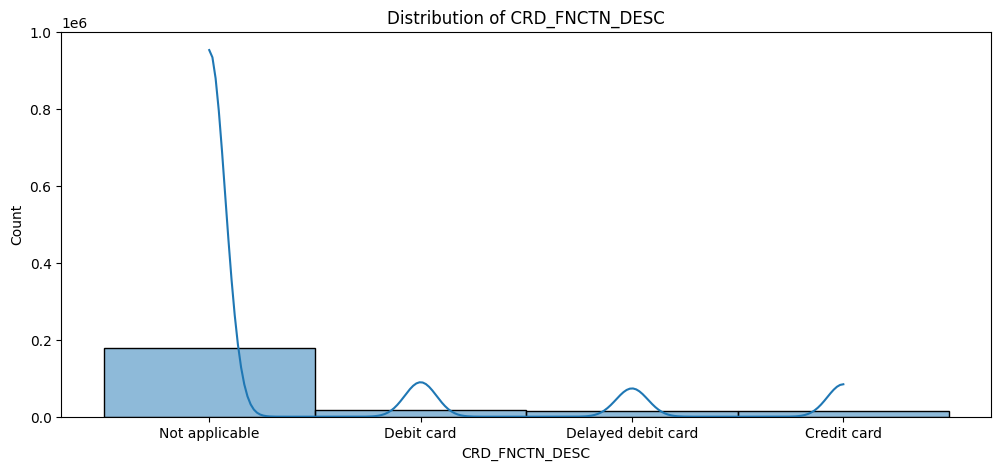

In [72]:
plt.figure(figsize=(12,5))
sns.histplot(combined["CRD_FNCTN_DESC"], bins=10, kde=True)
plt.title("Distribution of CRD_FNCTN_DESC")
plt.xlabel("CRD_FNCTN_DESC")
plt.show()

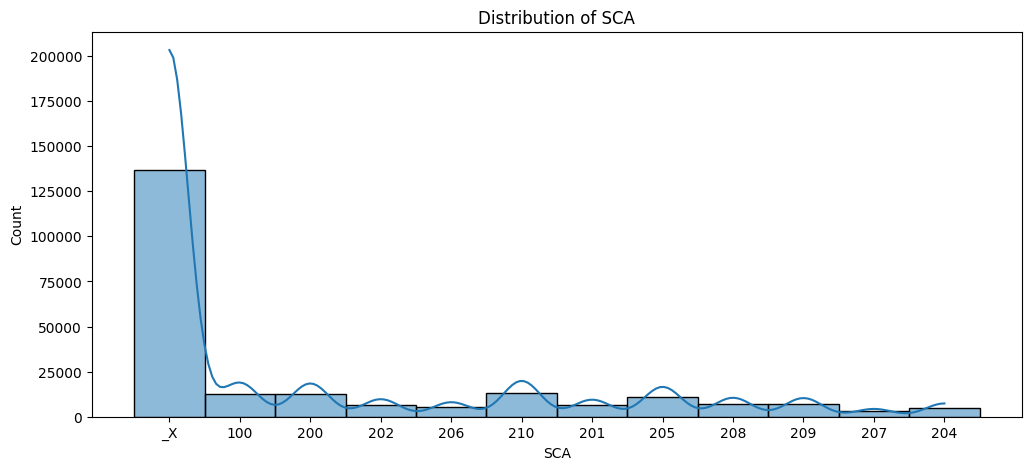

In [73]:
plt.figure(figsize=(12,5))
sns.histplot(combined["SCA"], bins=10, kde=True)
plt.title("Distribution of SCA")
plt.xlabel("SCA")
plt.show()

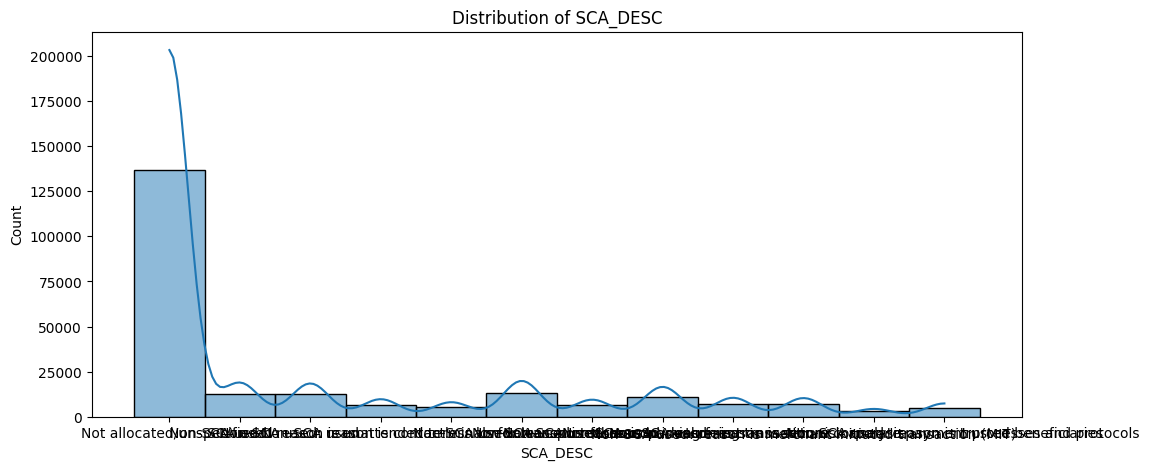

In [74]:
plt.figure(figsize=(12,5))
sns.histplot(combined["SCA_DESC"], bins=10, kde=True)
plt.title("Distribution of SCA_DESC")
plt.xlabel("SCA_DESC")
plt.show()

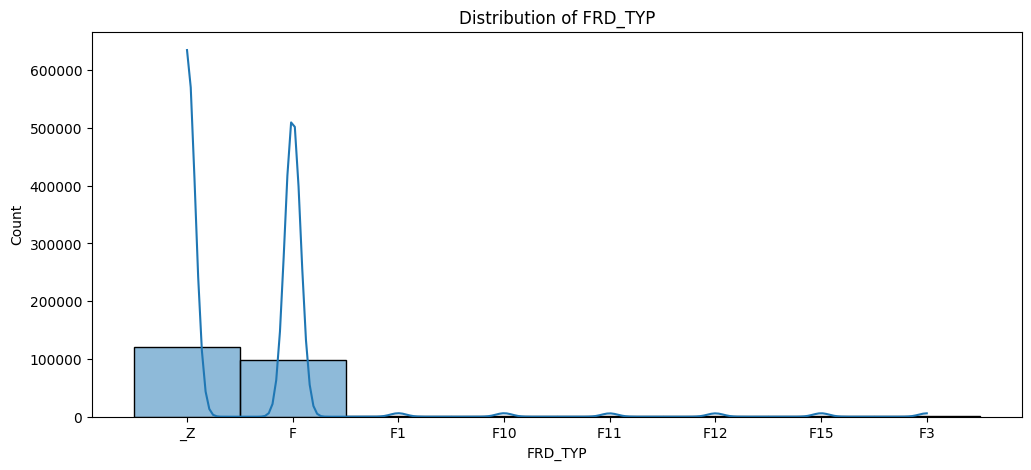

In [75]:
plt.figure(figsize=(12,5))
sns.histplot(combined["FRD_TYP"], bins=10, kde=True)
plt.title("Distribution of FRD_TYP")
plt.xlabel("FRD_TYP")
plt.show()

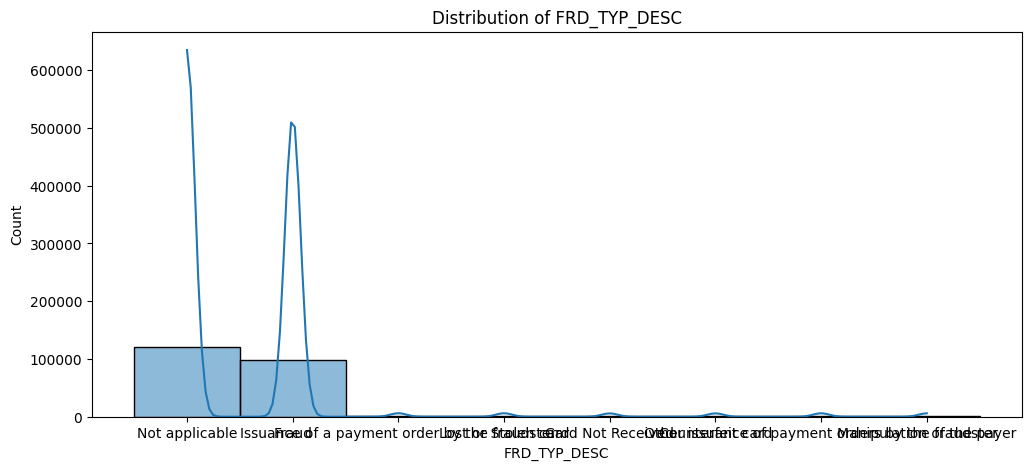

In [76]:
plt.figure(figsize=(12,5))
sns.histplot(combined["FRD_TYP_DESC"], bins=10, kde=True)
plt.title("Distribution of FRD_TYP_DESC")
plt.xlabel("FRD_TYP_DESC")
plt.show()

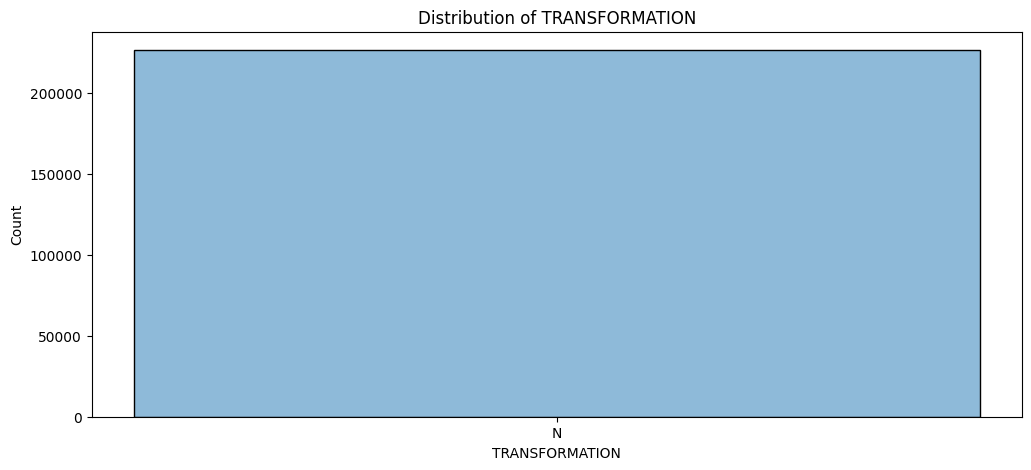

In [77]:
plt.figure(figsize=(12,5))
sns.histplot(combined["TRANSFORMATION"], bins=10, kde=True)
plt.title("Distribution of TRANSFORMATION")
plt.xlabel("TRANSFORMATION")
plt.show()

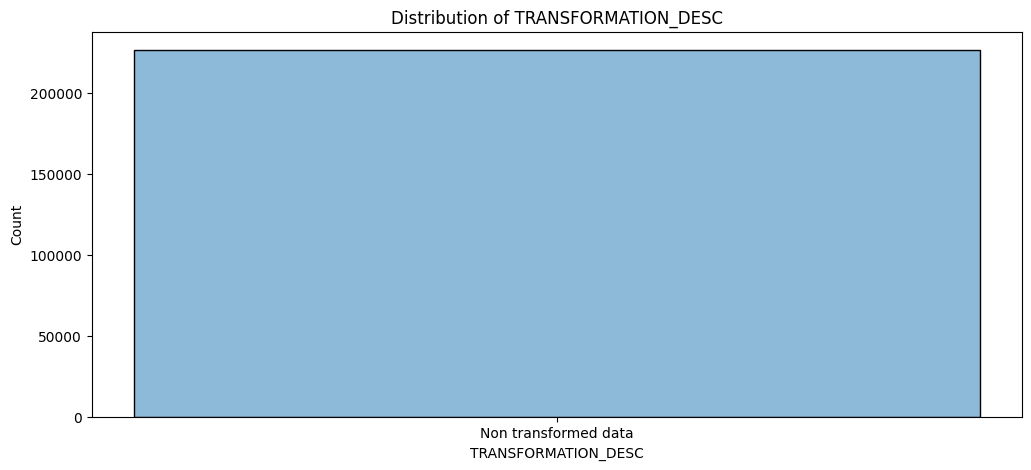

In [78]:
plt.figure(figsize=(12,5))
sns.histplot(combined["TRANSFORMATION_DESC"], bins=10, kde=True)
plt.title("Distribution of TRANSFORMATION_DESC")
plt.xlabel("TRANSFORMATION_DESC")
plt.show()

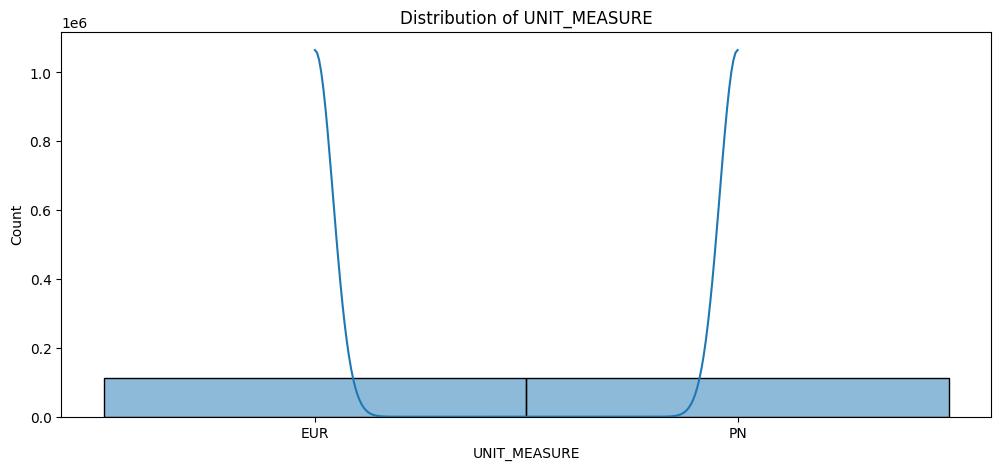

In [79]:
plt.figure(figsize=(12,5))
sns.histplot(combined["UNIT_MEASURE"], bins=10, kde=True)
plt.title("Distribution of UNIT_MEASURE")
plt.xlabel("UNIT_MEASURE")
plt.show()

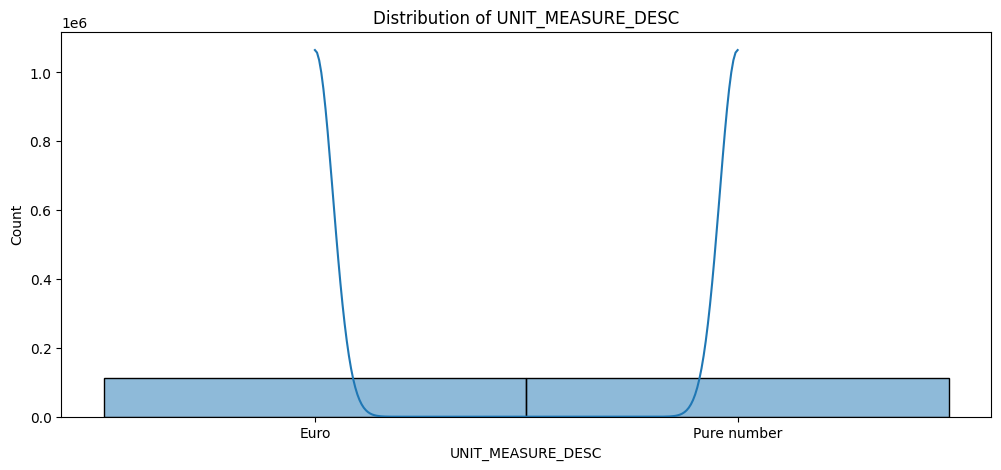

In [80]:
plt.figure(figsize=(12,5))
sns.histplot(combined["UNIT_MEASURE_DESC"], bins=10, kde=True)
plt.title("Distribution of UNIT_MEASURE_DESC")
plt.xlabel("UNIT_MEASURE_DESC")
plt.show()

#### Target Variable exploration

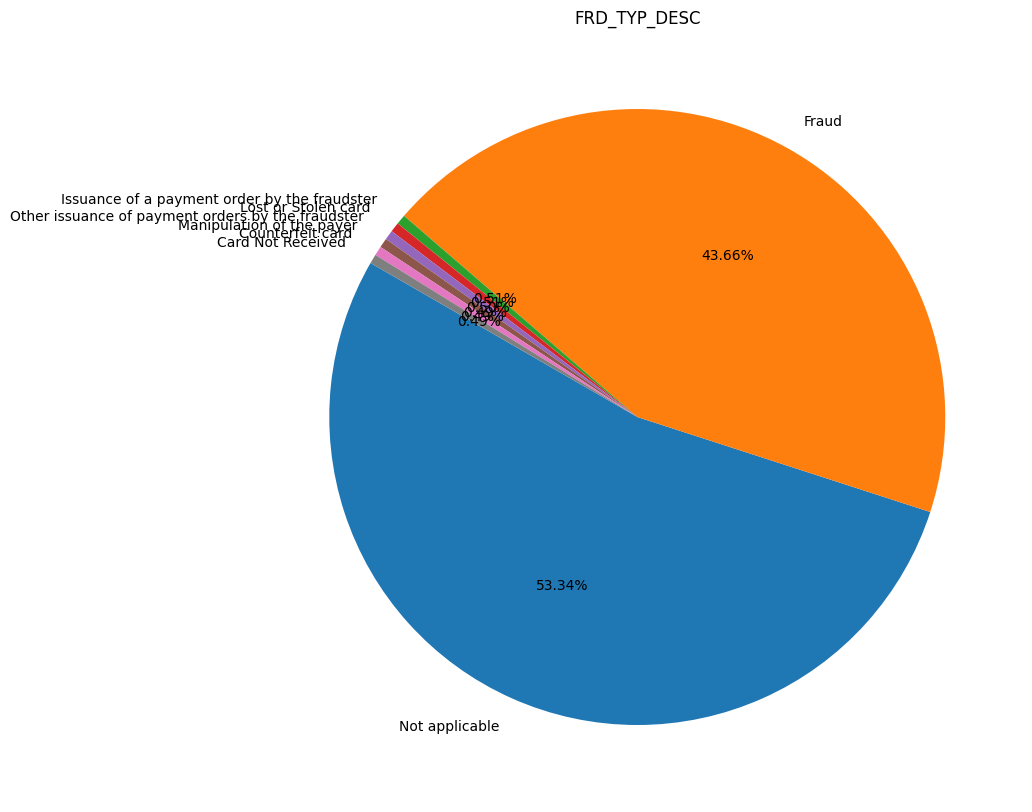

In [81]:
Variable_category_counts = combined["FRD_TYP_DESC"].value_counts()
plt.figure(figsize = (10, 10))
plt.pie(Variable_category_counts, labels = Variable_category_counts.index, autopct = '%1.2f%%', startangle = 150)
plt.title("FRD_TYP_DESC")
plt.show()

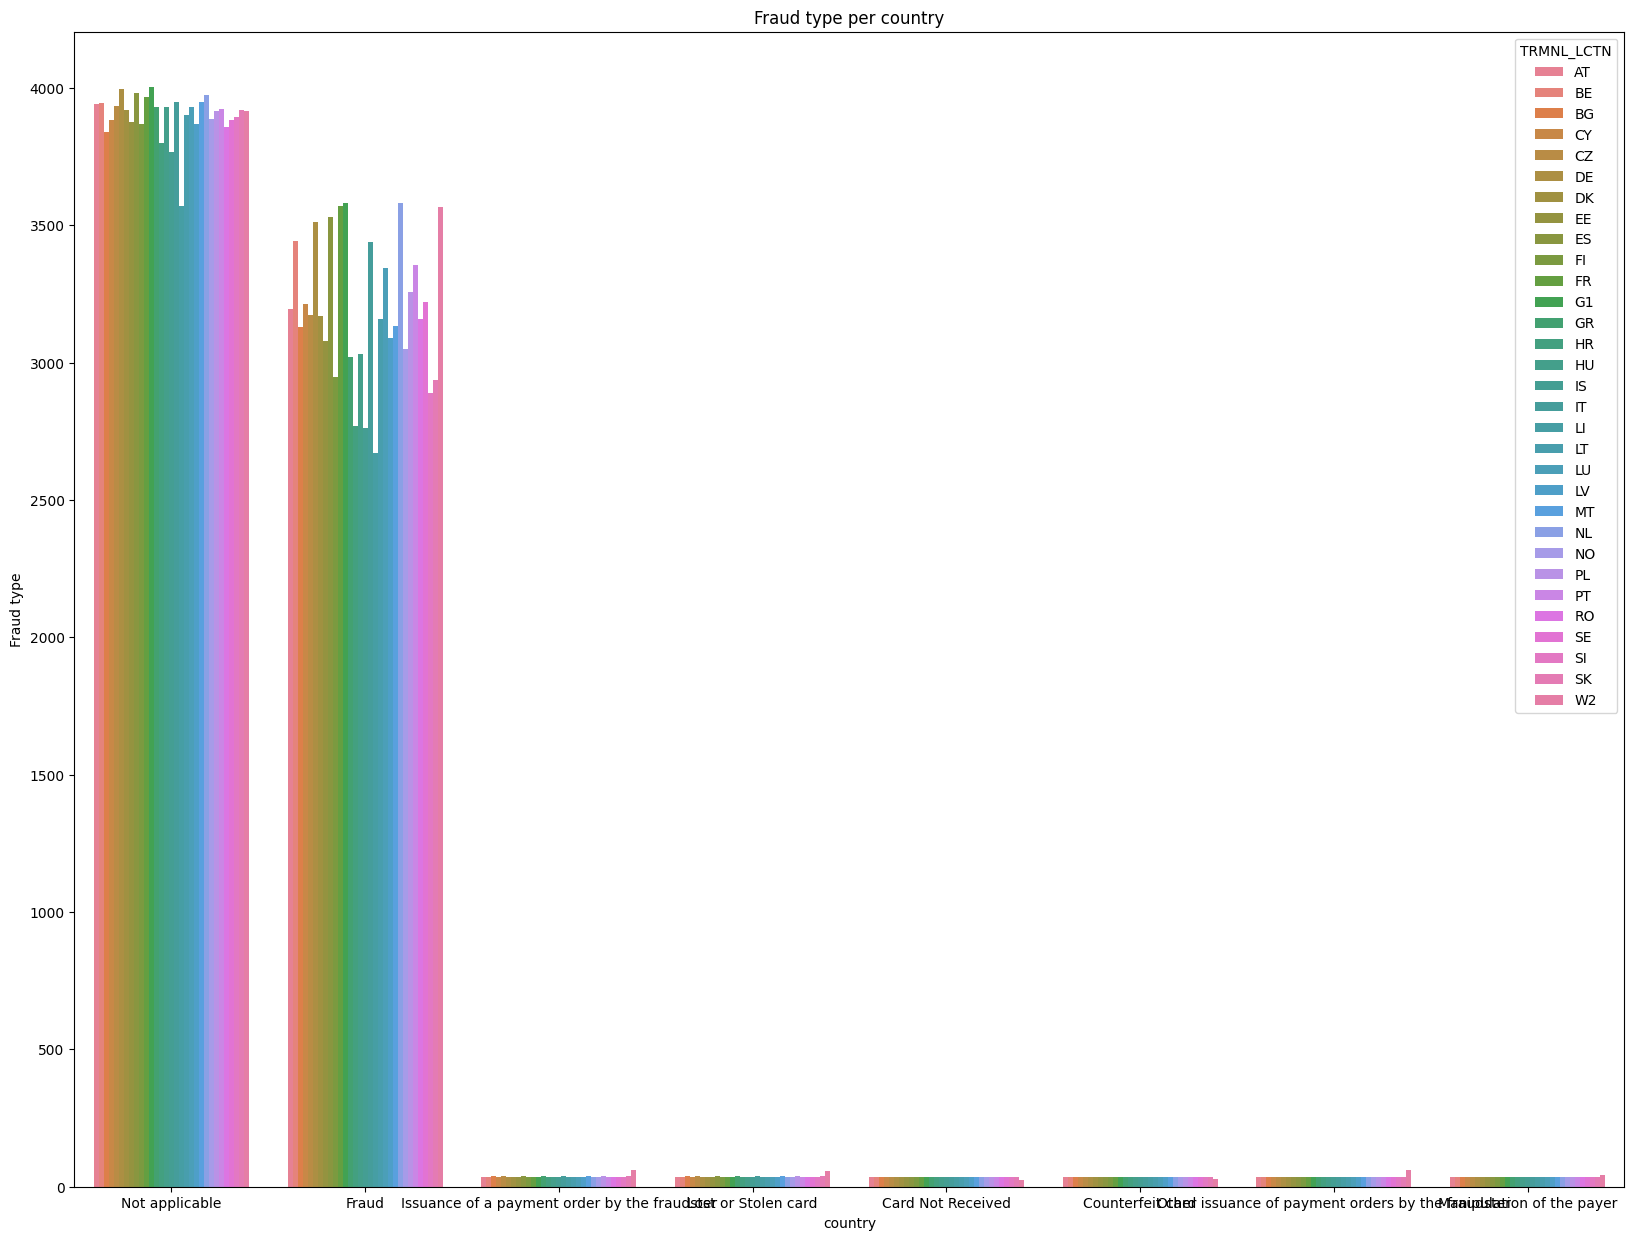

In [82]:
plt.figure(figsize=(20,15))
sns.countplot(data=combined, x="FRD_TYP_DESC", hue=combined["TRMNL_LCTN"])
plt.title("Fraud type per country")
plt.xlabel("country")
plt.ylabel("Fraud type")
plt.show()

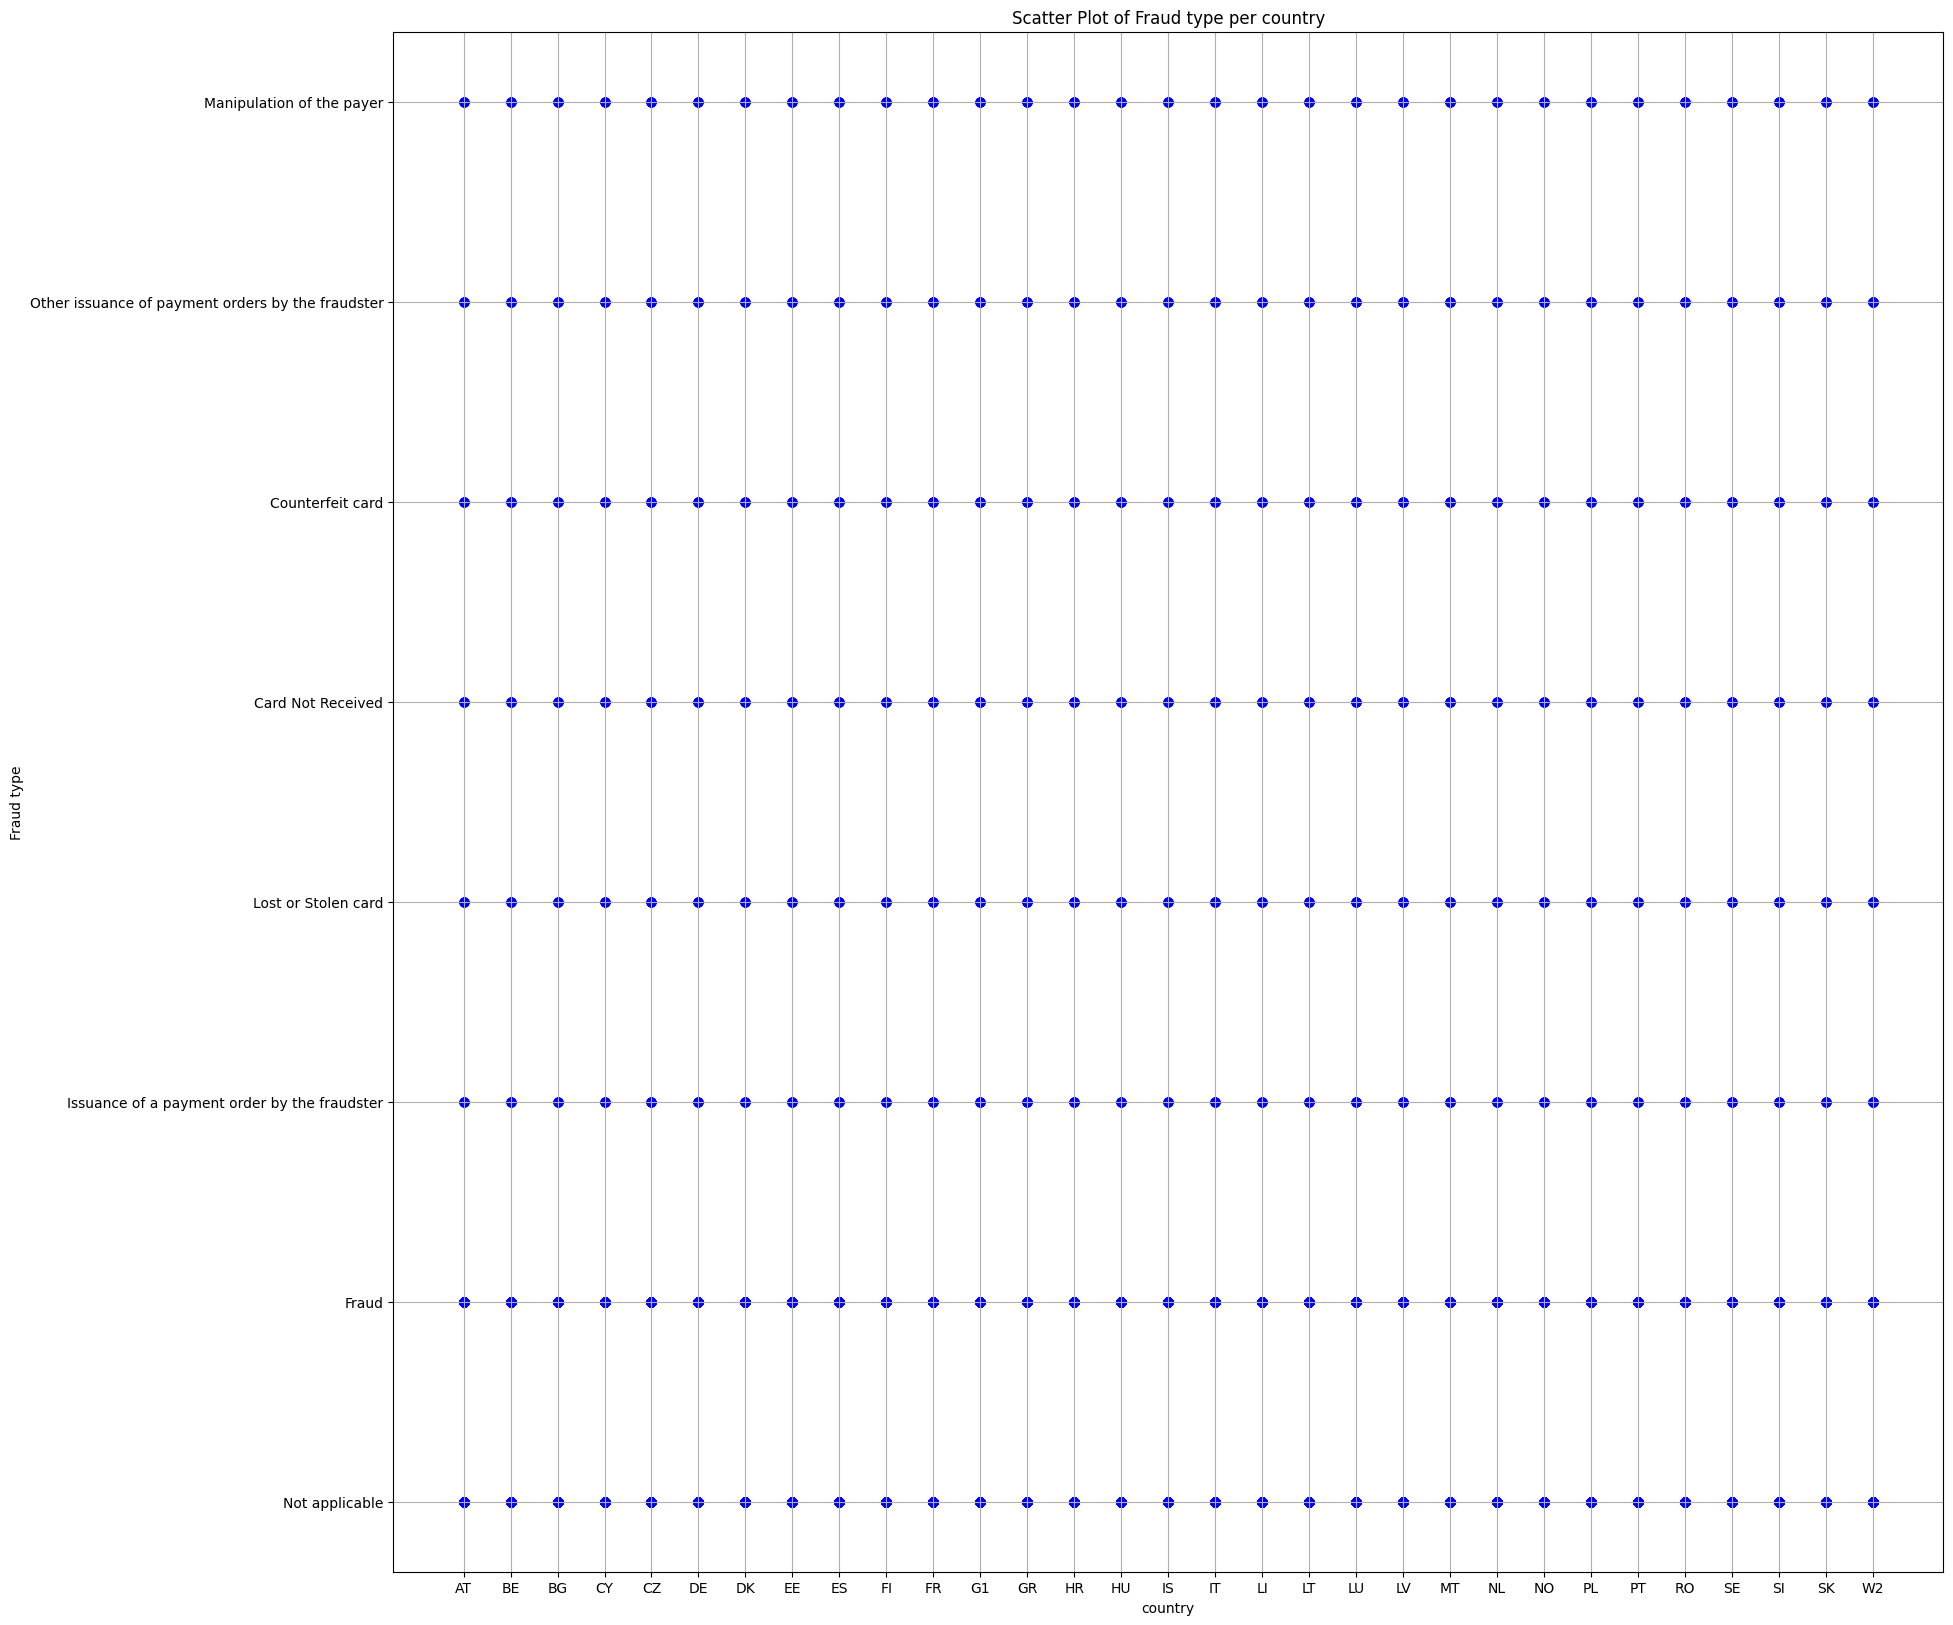

In [83]:
plt.figure(figsize=(20,20))
plt.scatter(combined["TRMNL_LCTN"], combined["FRD_TYP_DESC"], color="blue")
plt.title("Scatter Plot of Fraud type per country")
plt.xlabel("country")
plt.ylabel("Fraud type")
plt.grid(True)
plt.show()

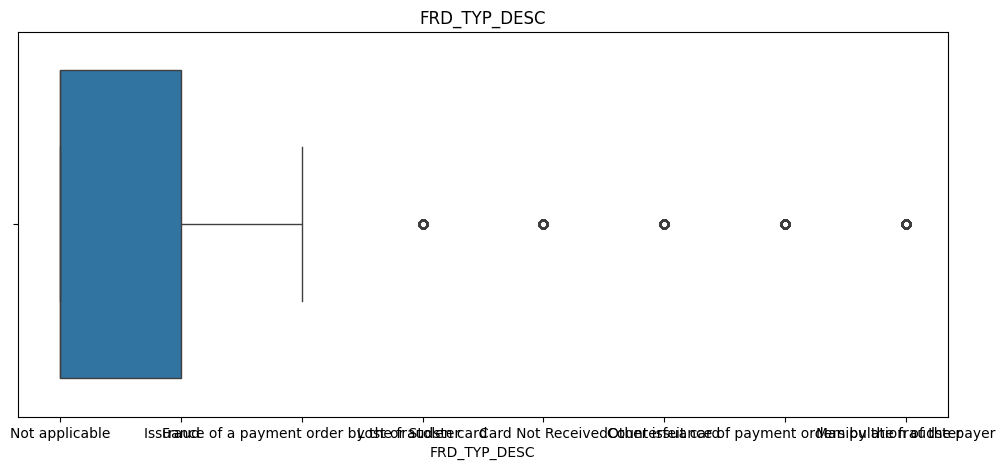

In [84]:
plt.figure(figsize=(12,5))
sns.boxplot(data=combined, x="FRD_TYP_DESC")
plt.title("FRD_TYP_DESC")
plt.show()

#### EDA - Missing values, feature Engineering, rejecting irrelevant columns

In [85]:
df = combined.drop(["SERIES_KEY", "OBSERVATION", "FREQ_DESC", "REF_AREA_DESC", "TRMNL_LCTN_DESC", "RL_TRNSCTN_DESC", "INTTN_CHNNL", "RMT_INTTN", "PYMNT_SCHM", "CRD_FNCTN", "SCA", "FRD_TYP", "TRANSFORMATION", "UNIT_MEASURE_DESC", "FREQ", "COUNT_AREA", "TYP_TRNSCTN"], axis=1)
print("\nData frame after dropping irrelevant columns:")
print(df)


Data frame after dropping irrelevant columns:
       REPORTINGPERIOD CONFIDENTIALITY_FLAG     UNITS REF_AREA  \
0           2022-12-31                    C  Millions       IE   
1           2022-12-31                    C  Millions       IE   
2           2022-12-31                    C  Millions       IE   
3           2022-12-31                    C  Millions       IE   
4           2022-12-31                    C  Millions       IE   
...                ...                  ...       ...      ...   
226673      2024-06-30                    F  Millions       IE   
226674      2024-06-30                    F  Millions       IE   
226675      2024-06-30                    F  Millions       IE   
226676      2024-06-30                    C  Millions       IE   
226677      2024-06-30                    C  Millions       IE   

                          COUNT_AREA_DESC TRMNL_LCTN  \
0                               Extra EEA         AT   
1                               Extra EEA       

In [86]:
df = df.rename(columns={
    "REF_AREA": "Country origin",
    "TRMNL_LCTN": "Country",
    "TYP_TRNSCTN_DESC": "Transaction Type",
    "RL_TRNSCTN": "Transaction",
    "INTTN_CHNNL_DESC": "Transaction Channels",
    "RMT_INTTN_DESC": "Transaction Decs",
    "PYMNT_SCHM_DESC": "Payment scheme",
    "CRD_FNCTN_DESC": "Payment Card Types",
    "SCA_DESC": "SCA Classification",
    "FRD_TYP_DESC": "Target Variable",
    "REPORTINGPERIOD": "REPORTING PERIOD",
    "CONFIDENTIALITY_FLAG": "CONFIDENTIALITY FLAG",
    "COUNT_AREA_DESC": "Geographic Area",
    "TRANSFORMATION_DESC": "TRANSFORMATION DESC",
    "UNIT_MEASURE": "UNIT MEASURE"
    })

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   REPORTING PERIOD      226678 non-null  object
 1   CONFIDENTIALITY FLAG  226678 non-null  object
 2   UNITS                 226678 non-null  object
 3   Country origin        226678 non-null  object
 4   Geographic Area       226678 non-null  object
 5   Country               226678 non-null  object
 6   Transaction Type      226678 non-null  object
 7   Transaction           226678 non-null  int64 
 8   Transaction Channels  226678 non-null  object
 9   Transaction Decs      226678 non-null  object
 10  Payment scheme        226678 non-null  object
 11  Payment Card Types    226678 non-null  object
 12  SCA Classification    226678 non-null  object
 13  Target Variable       226678 non-null  object
 14  TRANSFORMATION DESC   226678 non-null  object
 15  UNIT MEASURE     

In [88]:
df.isnull().sum()

REPORTING PERIOD        0
CONFIDENTIALITY FLAG    0
UNITS                   0
Country origin          0
Geographic Area         0
Country                 0
Transaction Type        0
Transaction             0
Transaction Channels    0
Transaction Decs        0
Payment scheme          0
Payment Card Types      0
SCA Classification      0
Target Variable         0
TRANSFORMATION DESC     0
UNIT MEASURE            0
dtype: int64

In [89]:
df["REPORTING PERIOD"] = pd.to_datetime(df["REPORTING PERIOD"])

# Extract useful date features
df["year"] = df["REPORTING PERIOD"].dt.year
df["month"] = df["REPORTING PERIOD"].dt.month
df["quarter"] = df["REPORTING PERIOD"].dt.quarter
df["day"] = df["REPORTING PERIOD"].dt.day

print("Date features created:")
print(df[["REPORTING PERIOD", "year", "month", "quarter", "day"]].head())

Date features created:
  REPORTING PERIOD  year  month  quarter  day
0       2022-12-31  2022     12        4   31
1       2022-12-31  2022     12        4   31
2       2022-12-31  2022     12        4   31
3       2022-12-31  2022     12        4   31
4       2022-12-31  2022     12        4   31


In [90]:
df = df.drop(["REPORTING PERIOD"], axis=1)

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   CONFIDENTIALITY FLAG  226678 non-null  object
 1   UNITS                 226678 non-null  object
 2   Country origin        226678 non-null  object
 3   Geographic Area       226678 non-null  object
 4   Country               226678 non-null  object
 5   Transaction Type      226678 non-null  object
 6   Transaction           226678 non-null  int64 
 7   Transaction Channels  226678 non-null  object
 8   Transaction Decs      226678 non-null  object
 9   Payment scheme        226678 non-null  object
 10  Payment Card Types    226678 non-null  object
 11  SCA Classification    226678 non-null  object
 12  Target Variable       226678 non-null  object
 13  TRANSFORMATION DESC   226678 non-null  object
 14  UNIT MEASURE          226678 non-null  object
 15  year             

In [92]:
df["year"].unique()

array([2022, 2023, 2024], dtype=int32)

In [93]:
df["month"].unique()

array([12,  6], dtype=int32)

In [94]:
df["quarter"].unique()

array([4, 2], dtype=int32)

In [95]:
df["day"].unique()

array([31, 30], dtype=int32)

In [96]:
df["Geographic Area"].unique()

array(['Extra EEA',
       'Other EEA countries (all countries excluding the reference area)',
       'World (all entities, including reference area, including IO)',
       'Rest of the World', 'Domestic (home or reference area)'],
      dtype=object)

In [97]:
df["Geographic Area"].value_counts()

Geographic Area
World (all entities, including reference area, including IO)        53568
Rest of the World                                                   53300
Other EEA countries (all countries excluding the reference area)    52866
Domestic (home or reference area)                                   34024
Extra EEA                                                           32920
Name: count, dtype: int64

In [98]:
df["Transaction Type"].unique()

array(['Card payments', 'Card payments (Contactless)',
       'Card payments (NFC)', 'Cash withdrawals using cards'],
      dtype=object)

In [99]:
df["Transaction Type"].value_counts()

Transaction Type
Card payments                   202876
Cash withdrawals using cards     17152
Card payments (Contactless)       3326
Card payments (NFC)               3324
Name: count, dtype: int64

In [100]:
df["Transaction Channels"].unique()

array(['All', 'Non-electronic', 'Electronic', 'EFTPOS',
       'Other electronic channel than ATM, EFTPOS',
       'Mobile payment solution', 'ATM', 'P2P mobile payment solution'],
      dtype=object)

In [101]:
df["Transaction Channels"].value_counts()

Transaction Channels
Electronic                                   150500
All                                           24484
Non-electronic                                18774
EFTPOS                                        13446
Other electronic channel than ATM, EFTPOS      8678
ATM                                            4586
Mobile payment solution                        3372
P2P mobile payment solution                    2838
Name: count, dtype: int64

In [102]:
df["Transaction Decs"].unique()

array(['Initiated either via remote or non-remote channel',
       'Intiated via remote channel', 'Initiated via non-remote channel'],
      dtype=object)

In [103]:
df["Transaction Decs"].value_counts()

Transaction Decs
Intiated via remote channel                          98564
Initiated via non-remote channel                     89634
Initiated either via remote or non-remote channel    38480
Name: count, dtype: int64

In [104]:
df["Payment Card Types"].unique()

array(['Not applicable', 'Debit card', 'Delayed debit card',
       'Credit card'], dtype=object)

In [105]:
df["Payment Card Types"].value_counts()

Payment Card Types
Not applicable        179920
Debit card             16936
Credit card            15928
Delayed debit card     13894
Name: count, dtype: int64

In [106]:
df["SCA Classification"].unique()

array(['Not allocated/unspecified', 'SCA used', 'Non-SCA used',
       'Non-SCA used: reason is contactless low value',
       'Non-SCA used: reason is unattended terminals for transport fares or parking fees',
       'Non-SCA used: reason is others',
       'Non-SCA used: reason is low value',
       'Non-SCA used: reason is recurring transaction',
       'Non-SCA used: reason is transaction risk analysis',
       'Non-SCA used: reason is merchant initiated transaction (MIT)',
       'Non-SCA used: reason is secure corporate payment processes and protocols',
       'Non-SCA used: reason is trusted beneficiaries'], dtype=object)

In [107]:
df["SCA Classification"].value_counts()

SCA Classification
Not allocated/unspecified                                                           136940
Non-SCA used: reason is others                                                       13376
SCA used                                                                             12642
Non-SCA used                                                                         12410
Non-SCA used: reason is recurring transaction                                        11142
Non-SCA used: reason is transaction risk analysis                                     7060
Non-SCA used: reason is merchant initiated transaction (MIT)                          6956
Non-SCA used: reason is contactless low value                                         6536
Non-SCA used: reason is low value                                                     6348
Non-SCA used: reason is unattended terminals for transport fares or parking fees      5408
Non-SCA used: reason is trusted beneficiaries                          

In [108]:
df["Target Variable"].unique()

array(['Not applicable', 'Fraud',
       'Issuance of a payment order by the fraudster',
       'Lost or Stolen card', 'Card Not Received', 'Counterfeit card',
       'Other issuance of payment orders by the fraudster',
       'Manipulation of the payer'], dtype=object)

In [109]:
df["Target Variable"].value_counts()

Target Variable
Not applicable                                       120916
Fraud                                                 98978
Issuance of a payment order by the fraudster           1156
Lost or Stolen card                                    1154
Other issuance of payment orders by the fraudster      1140
Manipulation of the payer                              1122
Counterfeit card                                       1108
Card Not Received                                      1104
Name: count, dtype: int64

In [110]:
df_processed = df.copy()
cat_cols = df_processed.select_dtypes(include=["object"]).columns.tolist()
num_cols = df_processed.select_dtypes(include=["int64", "int32", "float64"]).columns.tolist()
print(f"Categorical columns: {len(cat_cols)}")
print(f"Numerical columns: {len(num_cols)}")


label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_processed[col] = le.fit_transform(df_processed[col].astype(str))
    label_encoders[col] = le


target_col = "Target Variable"
if target_col in df_processed.columns:
    X = df_processed.drop(target_col, axis=1)
    y = df_processed[target_col]
else:
    X = df_processed.copy()
    y = None


continuous_cols = ["Transaction"]  
X_processed = X.copy()

if continuous_cols:
    scaler = StandardScaler()
    
    X_processed[continuous_cols] = scaler.fit_transform(X[continuous_cols])
    
    print(f"\nScaled columns: {continuous_cols}")
else:
    print("\nNo continuous columns to scale")

df_final = pd.DataFrame(X_processed, columns=X.columns)
if y is not None:
    df_final[target_col] = y.values

print("\n" + "="*50)
print("Dataset shape after processing:", df_final.shape)
print("\nColumn dtypes after processing:")
print(df_final.dtypes.value_counts())
print(f"\nNumber of columns remained the same: {len(df_final.columns)}")
print("\nFirst few rows of processed data:")
print(df_final.head())
print("\n" + "="*50)
if continuous_cols:
    print(f"\nStatistics of scaled 'Transaction' column:")
    print(f"Mean: {df_final["Transaction"].mean():.4f}")
    print(f"Std: {df_final["Transaction"].std():.4f}")
    print(f"Min: {df_final["Transaction"].min():.4f}")
    print(f"Max: {df_final["Transaction"].max():.4f}")

Categorical columns: 14
Numerical columns: 5

Scaled columns: ['Transaction']

Dataset shape after processing: (226678, 19)

Column dtypes after processing:
int64      14
int32       4
float64     1
Name: count, dtype: int64

Number of columns remained the same: 19

First few rows of processed data:
   CONFIDENTIALITY FLAG  UNITS  Country origin  Geographic Area  Country  \
0                     0      0               0                1        0   
1                     0      0               0                1        0   
2                     0      0               0                1        0   
3                     0      0               0                1        0   
4                     0      0               0                1        0   

   Transaction Type  Transaction  Transaction Channels  Transaction Decs  \
0                 0    -0.822565                     1                 0   
1                 0    -0.822565                     1                 0   
2             

In [111]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CONFIDENTIALITY FLAG  226678 non-null  int64  
 1   UNITS                 226678 non-null  int64  
 2   Country origin        226678 non-null  int64  
 3   Geographic Area       226678 non-null  int64  
 4   Country               226678 non-null  int64  
 5   Transaction Type      226678 non-null  int64  
 6   Transaction           226678 non-null  float64
 7   Transaction Channels  226678 non-null  int64  
 8   Transaction Decs      226678 non-null  int64  
 9   Payment scheme        226678 non-null  int64  
 10  Payment Card Types    226678 non-null  int64  
 11  SCA Classification    226678 non-null  int64  
 12  TRANSFORMATION DESC   226678 non-null  int64  
 13  UNIT MEASURE          226678 non-null  int64  
 14  year                  226678 non-null  int32  
 15  

In [112]:
df_final["Target Variable"].unique()

array([6, 2, 3, 4, 0, 1, 7, 5])

In [113]:
df_final["Target Variable"].value_counts()

Target Variable
6    120916
2     98978
3      1156
4      1154
7      1140
5      1122
1      1108
0      1104
Name: count, dtype: int64

In [114]:
df["Target Variable"].value_counts()

Target Variable
Not applicable                                       120916
Fraud                                                 98978
Issuance of a payment order by the fraudster           1156
Lost or Stolen card                                    1154
Other issuance of payment orders by the fraudster      1140
Manipulation of the payer                              1122
Counterfeit card                                       1108
Card Not Received                                      1104
Name: count, dtype: int64

In [115]:
df_final["SCA Classification"].unique()

array([10, 11,  0,  1,  9,  4,  2,  5,  7,  3,  6,  8])

In [116]:
df_final["SCA Classification"].value_counts()

SCA Classification
10    136940
4      13376
11     12642
0      12410
5      11142
7       7060
3       6956
1       6536
2       6348
9       5408
8       4958
6       2902
Name: count, dtype: int64

In [117]:
df["SCA Classification"].value_counts()

SCA Classification
Not allocated/unspecified                                                           136940
Non-SCA used: reason is others                                                       13376
SCA used                                                                             12642
Non-SCA used                                                                         12410
Non-SCA used: reason is recurring transaction                                        11142
Non-SCA used: reason is transaction risk analysis                                     7060
Non-SCA used: reason is merchant initiated transaction (MIT)                          6956
Non-SCA used: reason is contactless low value                                         6536
Non-SCA used: reason is low value                                                     6348
Non-SCA used: reason is unattended terminals for transport fares or parking fees      5408
Non-SCA used: reason is trusted beneficiaries                          

In [118]:
numeric_cols = df_final.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    skewness = df_final[col].skew()
    
    # Interpret skewness
    if abs(skewness) < 0.5:
        skew_text = "≈ Normal"
    elif 0.5 <= abs(skewness) < 1:
        skew_text = "Moderately skewed"
    elif abs(skewness) >= 1:
        skew_text = "Highly skewed"
    
    direction = "left" if skewness < 0 else "right"
    
    print(f"{col:<25} Skewness: {skewness:7.2f} ({direction}-skewed, {skew_text})")

CONFIDENTIALITY FLAG      Skewness:    0.38 (right-skewed, ≈ Normal)
UNITS                     Skewness:    0.00 (right-skewed, ≈ Normal)
Country origin            Skewness:    0.00 (right-skewed, ≈ Normal)
Geographic Area           Skewness:   -0.28 (left-skewed, ≈ Normal)
Country                   Skewness:    0.01 (right-skewed, ≈ Normal)
Transaction Type          Skewness:    2.85 (right-skewed, Highly skewed)
Transaction               Skewness:    0.39 (right-skewed, ≈ Normal)
Transaction Channels      Skewness:    0.51 (right-skewed, Moderately skewed)
Transaction Decs          Skewness:   -0.46 (left-skewed, ≈ Normal)
Payment scheme            Skewness:    0.00 (right-skewed, ≈ Normal)
Payment Card Types        Skewness:   -1.97 (left-skewed, Highly skewed)
SCA Classification        Skewness:   -1.26 (left-skewed, Highly skewed)
TRANSFORMATION DESC       Skewness:    0.00 (right-skewed, ≈ Normal)
UNIT MEASURE              Skewness:    0.00 (right-skewed, ≈ Normal)
year          

In [119]:
df = df_final.copy()

highly_skewed_cols = {
    "Transaction Type": 2.85,        # Right skewed (positive)
    "Payment Card Types": -1.97,     # Left skewed (negative)
    "SCA Classification": -1.26      # Left skewed (negative)
}

for col, skew_val in highly_skewed_cols.items():
    original_data = df[col].copy()
    
    if skew_val > 0: 
        min_val = original_data.min()
        shift = 1 - min_val if min_val <= 0 else 0
        
        if (original_data + shift >= 0).all():
            transformed = np.sqrt(original_data + shift)
            new_skew = transformed.skew()
            df[col] = transformed
            print(f"{col:25} Right skewed: {skew_val:7.4f} → Square root: {new_skew:7.4f}")
        else:
            transformed = np.cbrt(original_data)
            new_skew = transformed.skew()
            df[col] = transformed
            print(f"{col:25} Right skewed: {skew_val:7.4f} → Cube root: {new_skew:7.4f}")
    
    else:  
        transformed = np.square(original_data)
        new_skew = transformed.skew()
        df[col] = transformed
        print(f"{col:25} Left skewed:  {skew_val:7.4f} → Square:      {new_skew:7.4f}")


Transaction Type          Right skewed:  2.8500 → Square root:  2.7895
Payment Card Types        Left skewed:  -1.9700 → Square:      -1.6377
SCA Classification        Left skewed:  -1.2600 → Square:      -0.9096


In [120]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CONFIDENTIALITY FLAG  226678 non-null  int64  
 1   UNITS                 226678 non-null  int64  
 2   Country origin        226678 non-null  int64  
 3   Geographic Area       226678 non-null  int64  
 4   Country               226678 non-null  int64  
 5   Transaction Type      226678 non-null  int64  
 6   Transaction           226678 non-null  float64
 7   Transaction Channels  226678 non-null  int64  
 8   Transaction Decs      226678 non-null  int64  
 9   Payment scheme        226678 non-null  int64  
 10  Payment Card Types    226678 non-null  int64  
 11  SCA Classification    226678 non-null  int64  
 12  TRANSFORMATION DESC   226678 non-null  int64  
 13  UNIT MEASURE          226678 non-null  int64  
 14  year                  226678 non-null  int32  
 15  

In [121]:
df_final["Transaction"].unique()

array([-0.82256454,  1.21571007])

#### Outliers

In [122]:
numeric_df_clean = df_final.select_dtypes(include="number")

Q1 = numeric_df_clean.quantile(0.25)
Q3 = numeric_df_clean.quantile(0.75)

IQR = Q3 - Q1
print(IQR)

df_clean2 = numeric_df_clean[~((numeric_df_clean < (Q1 - 1.5 * IQR)) | (numeric_df_clean > (Q3 + 1.5 * IQR))).any(axis=1)]
print(df.shape)

df_clean_no_outliers = df.loc[df_clean2.index]

CONFIDENTIALITY FLAG     1.000000
UNITS                    0.000000
Country origin           0.000000
Geographic Area          2.000000
Country                 16.000000
Transaction Type         0.000000
Transaction              2.038275
Transaction Channels     0.000000
Transaction Decs         1.000000
Payment scheme           0.000000
Payment Card Types       0.000000
SCA Classification       5.000000
TRANSFORMATION DESC      0.000000
UNIT MEASURE             1.000000
year                     2.000000
month                    6.000000
quarter                  2.000000
day                      1.000000
Target Variable          4.000000
dtype: float64
(226678, 19)


In [123]:
df_clean_no_outliers.describe()

,CONFIDENTIALITY FLAG,UNITS,Country origin,Geographic Area,Country,Transaction Type,Transaction,Transaction Channels,Transaction Decs,Payment scheme,Payment Card Types,SCA Classification,TRANSFORMATION DESC,UNIT MEASURE,year,month,quarter,day,Target Variable
count,111180.000000,111180.0,111180.0,111180.000000,111180.000000,111180.0,111180.000000,111180.0,111180.000000,111180.0,111180.0,111180.000000,111180.0,111180.000000,111180.000000,111180.000000,111180.000000,111180.000000,111180.000000
mean,0.365848,0.0,0.0,2.198237,14.961594,1.0,0.104541,3.0,1.488685,0.0,9.0,49.170282,0.0,0.500000,2023.009300,9.008527,3.002842,30.501421,4.203994
std,0.481669,0.0,0.0,1.381399,8.981740,0.0,1.014978,0.0,0.617817,0.0,0.0,44.308482,0.0,0.500002,0.817229,3.000001,1.000000,0.500000,1.989578
min,0.000000,0.0,0.0,0.000000,0.000000,1.0,-0.822565,3.0,0.000000,0.0,9.0,0.000000,0.0,0.000000,2022.000000,6.000000,2.000000,30.000000,2.000000
25%,0.000000,0.0,0.0,1.000000,7.000000,1.0,-0.822565,3.0,1.000000,0.0,9.0,9.000000,0.0,0.000000,2022.000000,6.000000,2.000000,30.000000,2.000000
50%,0.000000,0.0,0.0,2.000000,15.000000,1.0,-0.822565,3.0,2.000000,0.0,9.0,25.000000,0.0,0.500000,2023.000000,12.000000,4.000000,31.000000,6.000000
75%,1.000000,0.0,0.0,3.000000,23.000000,1.0,1.215710,3.0,2.000000,0.0,9.0,100.000000,0.0,1.000000,2024.000000,12.000000,4.000000,31.000000,6.000000
max,1.000000,0.0,0.0,4.000000,30.000000,1.0,1.215710,3.0,2.000000,0.0,9.0,121.000000,0.0,1.000000,2024.000000,12.000000,4.000000,31.000000,6.000000


In [124]:
df_final.describe()

,CONFIDENTIALITY FLAG,UNITS,Country origin,Geographic Area,Country,Transaction Type,Transaction,Transaction Channels,Transaction Decs,Payment scheme,Payment Card Types,SCA Classification,TRANSFORMATION DESC,UNIT MEASURE,year,month,quarter,day,Target Variable
count,226678.000000,226678.0,226678.0,226678.000000,226678.000000,226678.000000,2.266780e+05,226678.000000,226678.000000,226678.0,226678.000000,226678.000000,226678.0,226678.000000,226678.000000,226678.000000,226678.000000,226678.000000,226678.000000
mean,0.406850,0.0,0.0,2.262346,14.961999,0.271001,-3.025507e-16,3.009414,1.265063,0.0,2.578477,7.997882,0.0,0.500000,2023.011294,9.012626,3.004209,30.502104,4.174353
std,0.491248,0.0,0.0,1.362795,8.975608,0.825161,1.000002e+00,1.250760,0.730972,0.0,0.902704,3.332146,0.0,0.500001,0.816802,2.999980,0.999993,0.499997,2.006773
min,0.000000,0.0,0.0,0.000000,0.000000,0.000000,-8.225645e-01,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,2022.000000,6.000000,2.000000,30.000000,0.000000
25%,0.000000,0.0,0.0,1.000000,7.000000,0.000000,-8.225645e-01,3.000000,1.000000,0.0,3.000000,5.000000,0.0,0.000000,2022.000000,6.000000,2.000000,30.000000,2.000000
50%,0.000000,0.0,0.0,2.000000,15.000000,0.000000,-8.225645e-01,3.000000,1.000000,0.0,3.000000,10.000000,0.0,0.500000,2023.000000,12.000000,4.000000,31.000000,6.000000
75%,1.000000,0.0,0.0,3.000000,23.000000,0.000000,1.215710e+00,3.000000,2.000000,0.0,3.000000,10.000000,0.0,1.000000,2024.000000,12.000000,4.000000,31.000000,6.000000
max,1.000000,0.0,0.0,4.000000,30.000000,3.000000,1.215710e+00,7.000000,2.000000,0.0,3.000000,11.000000,0.0,1.000000,2024.000000,12.000000,4.000000,31.000000,7.000000


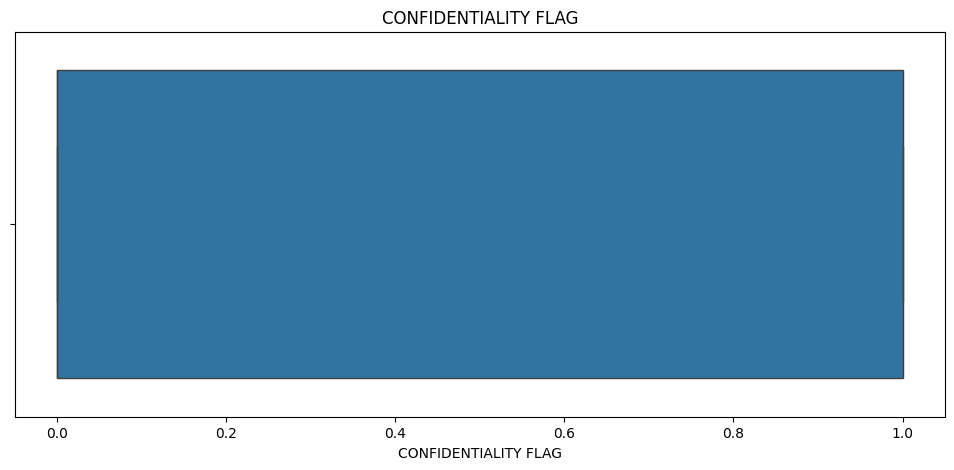

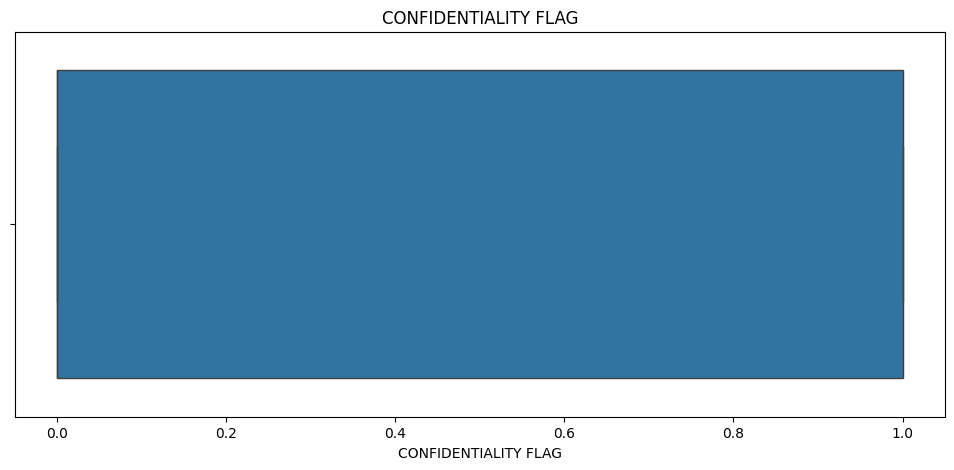

In [125]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="CONFIDENTIALITY FLAG")
plt.title("CONFIDENTIALITY FLAG")
plt.show()


plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="CONFIDENTIALITY FLAG")
plt.title("CONFIDENTIALITY FLAG")
plt.show()

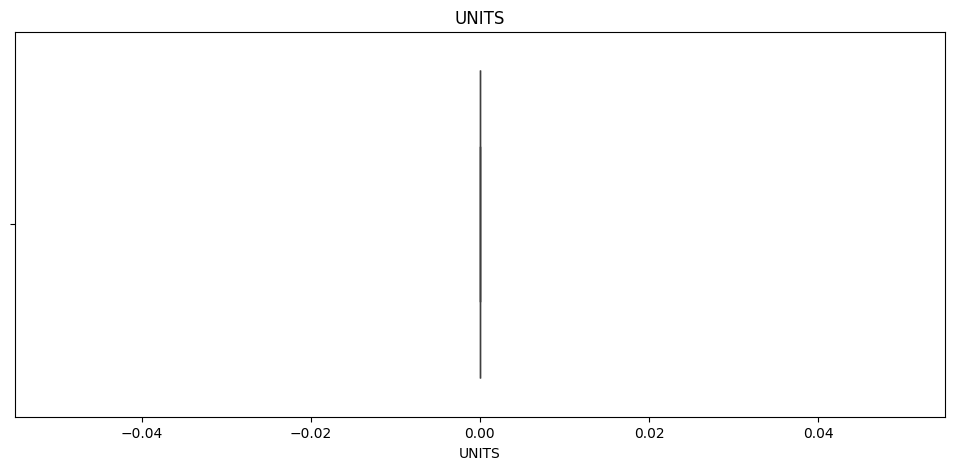

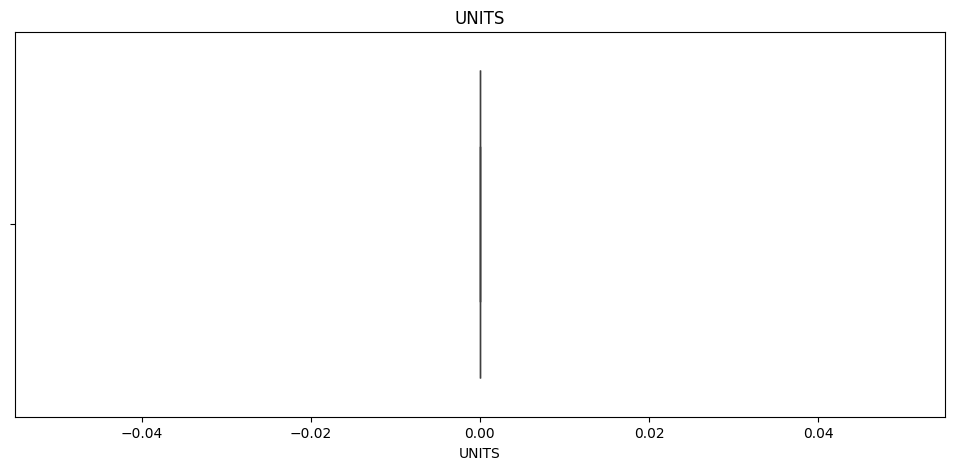

In [126]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="UNITS")
plt.title("UNITS")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="UNITS")
plt.title("UNITS")
plt.show()

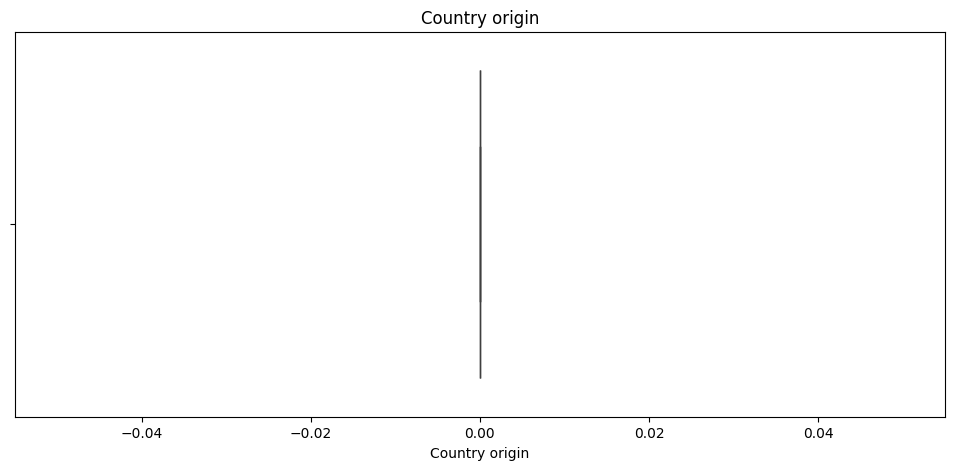

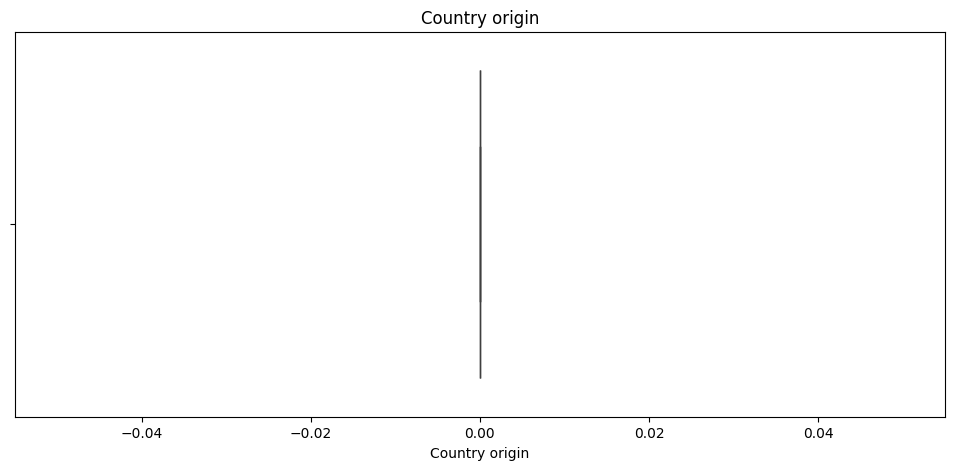

In [127]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Country origin")
plt.title("Country origin")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Country origin")
plt.title("Country origin")
plt.show()

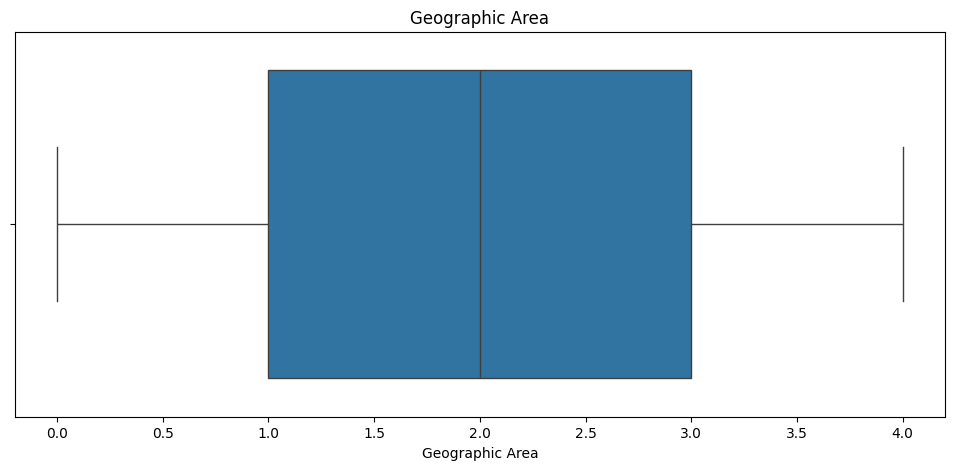

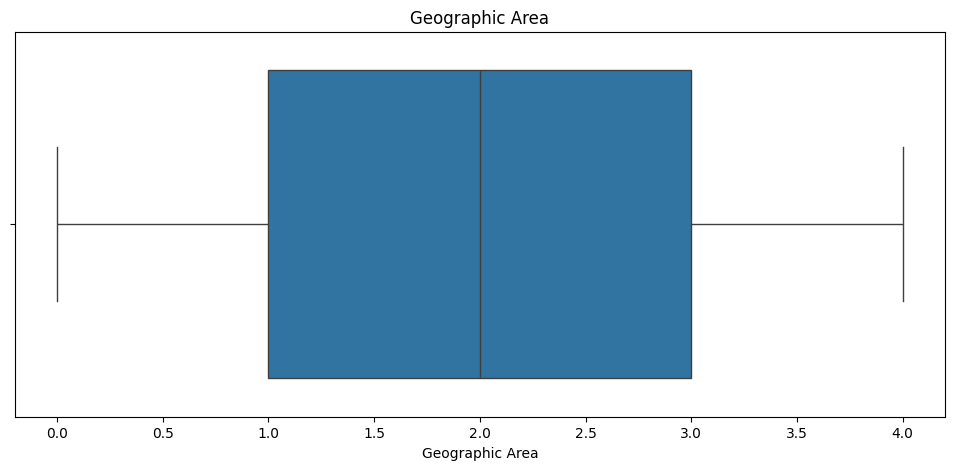

In [128]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Geographic Area")
plt.title("Geographic Area")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Geographic Area")
plt.title("Geographic Area")
plt.show()

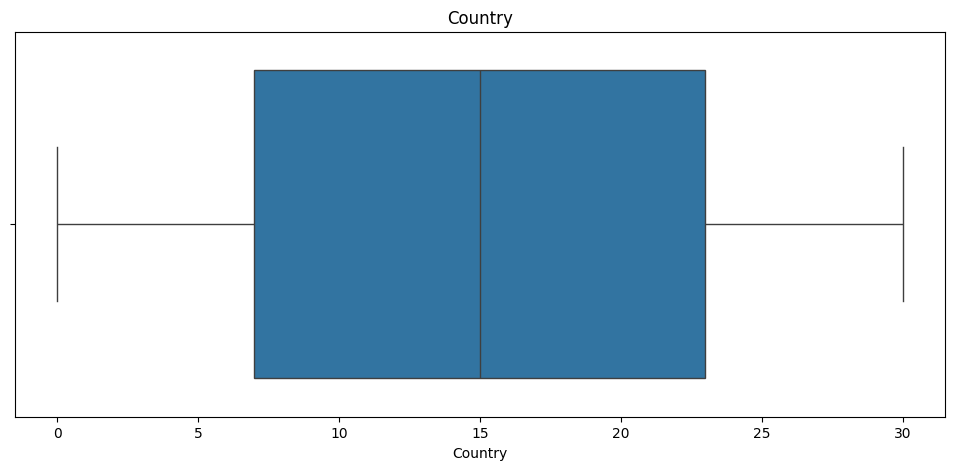

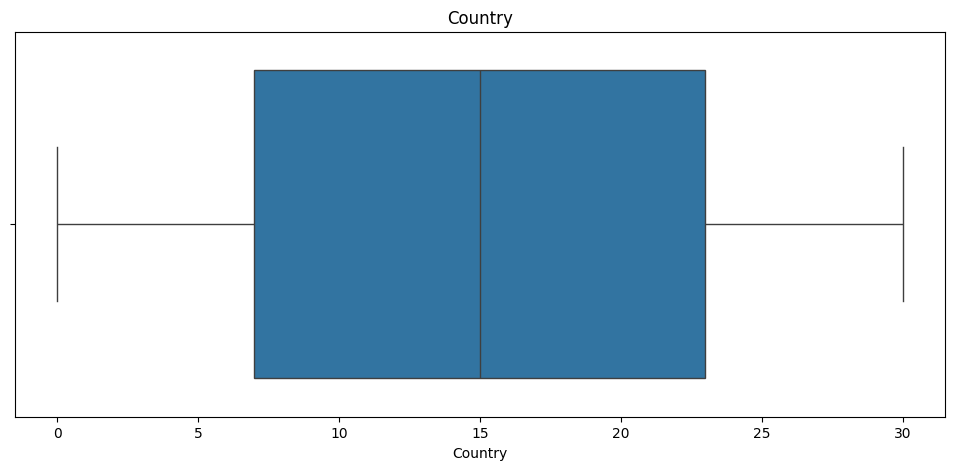

In [129]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Country")
plt.title("Country")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Country")
plt.title("Country")
plt.show()

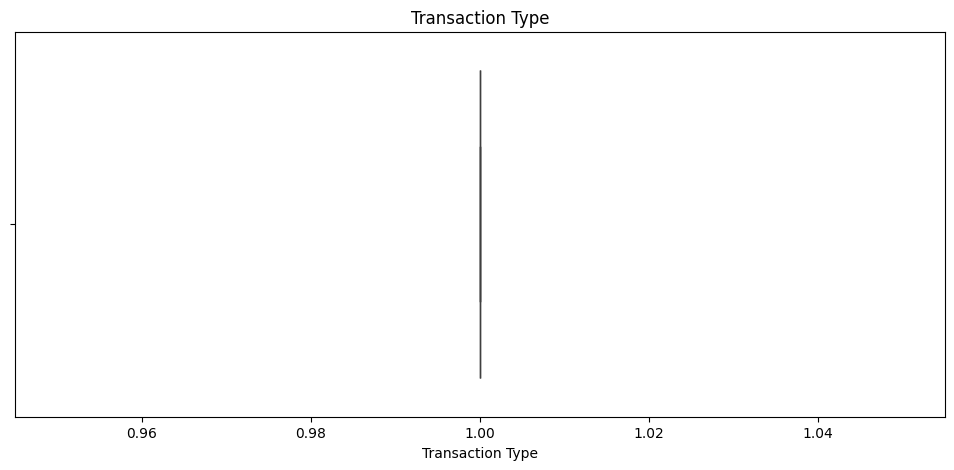

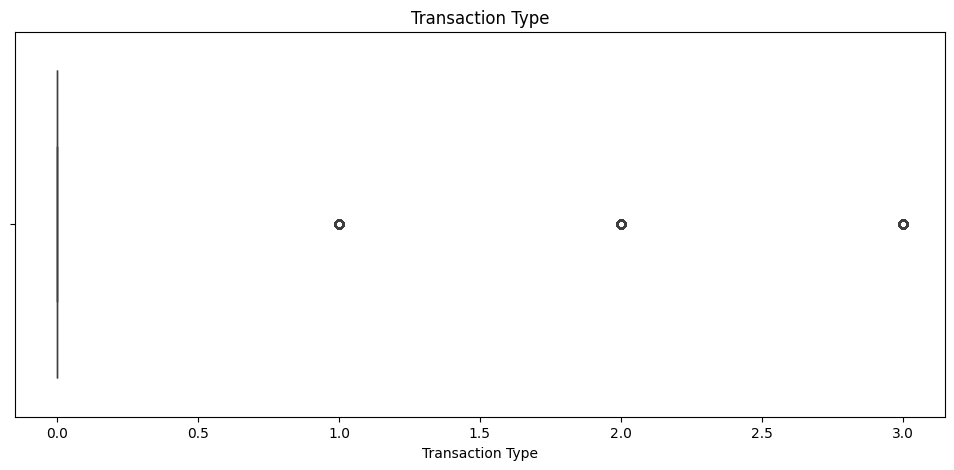

In [130]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Transaction Type")
plt.title("Transaction Type")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Transaction Type")
plt.title("Transaction Type")
plt.show()

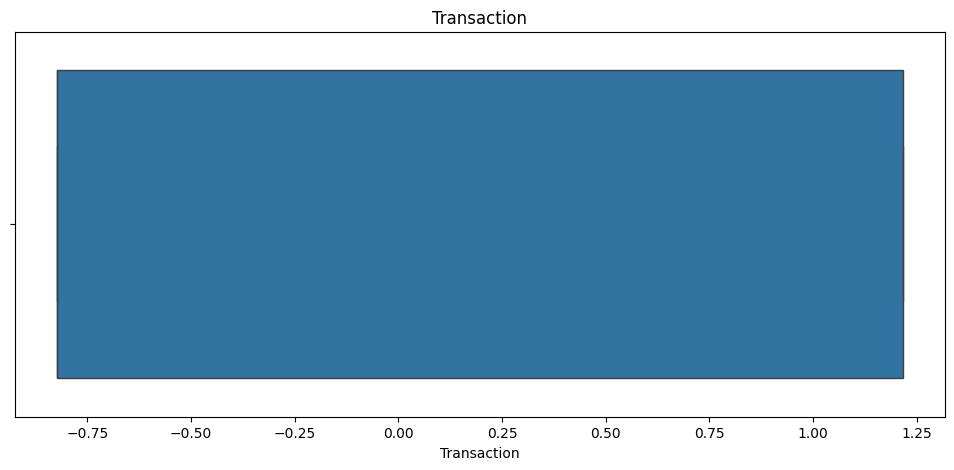

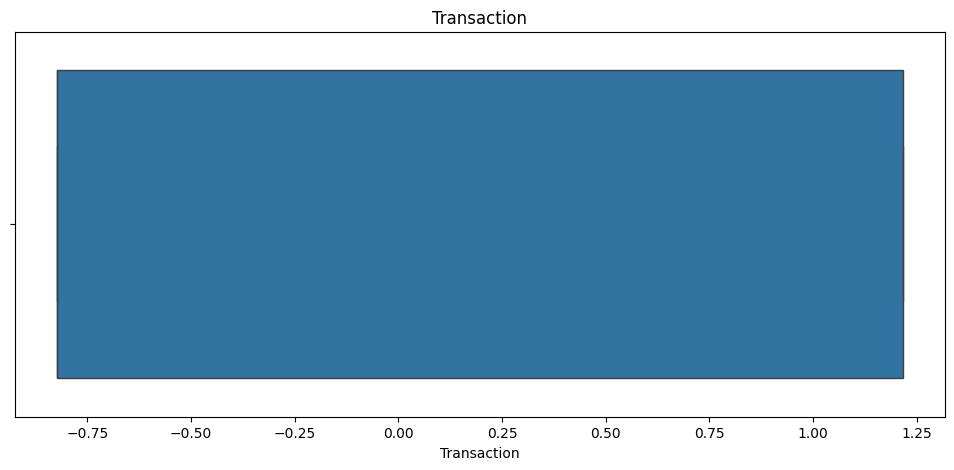

In [131]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Transaction")
plt.title("Transaction")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Transaction")
plt.title("Transaction")
plt.show()

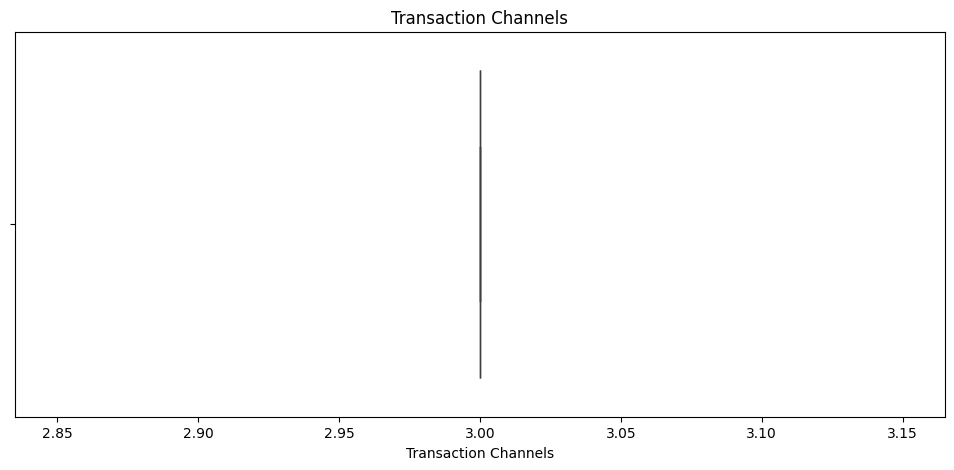

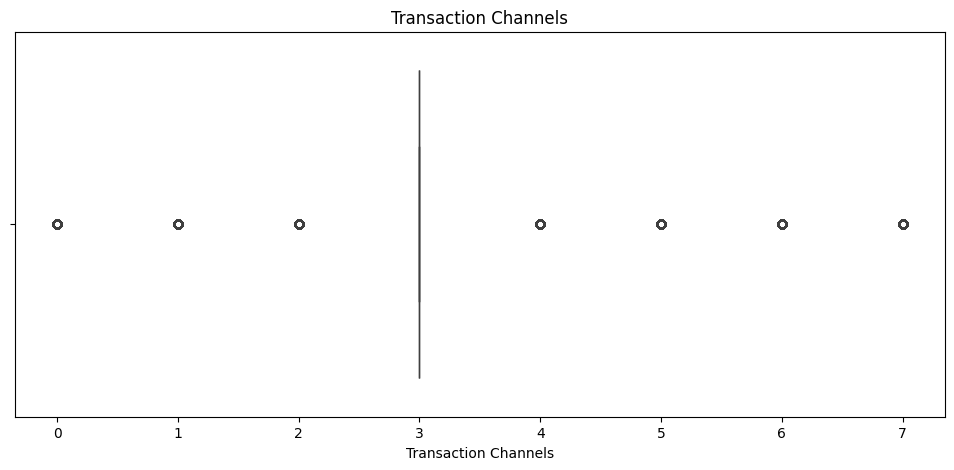

In [132]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Transaction Channels")
plt.title("Transaction Channels")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Transaction Channels")
plt.title("Transaction Channels")
plt.show()

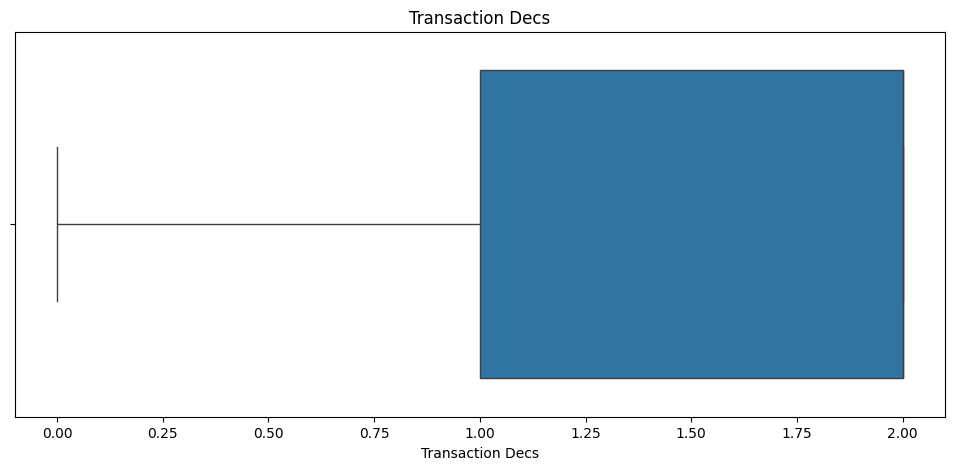

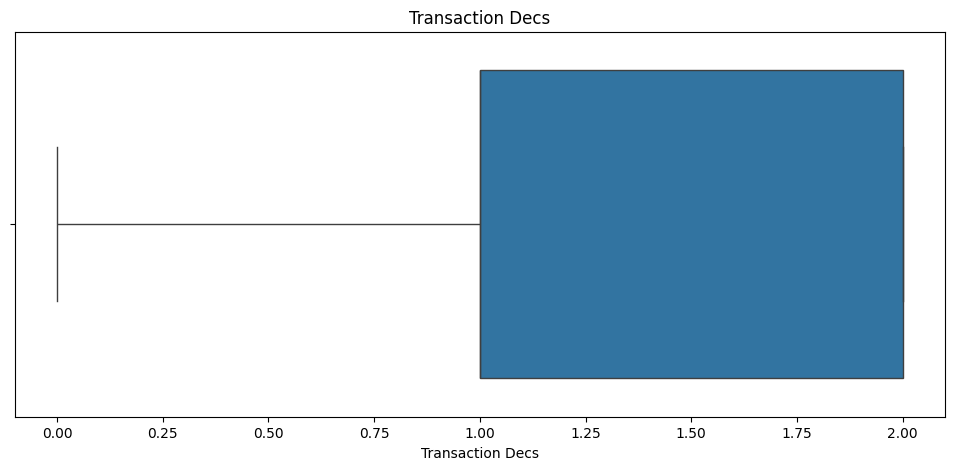

In [133]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Transaction Decs")
plt.title("Transaction Decs")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Transaction Decs")
plt.title("Transaction Decs")
plt.show()

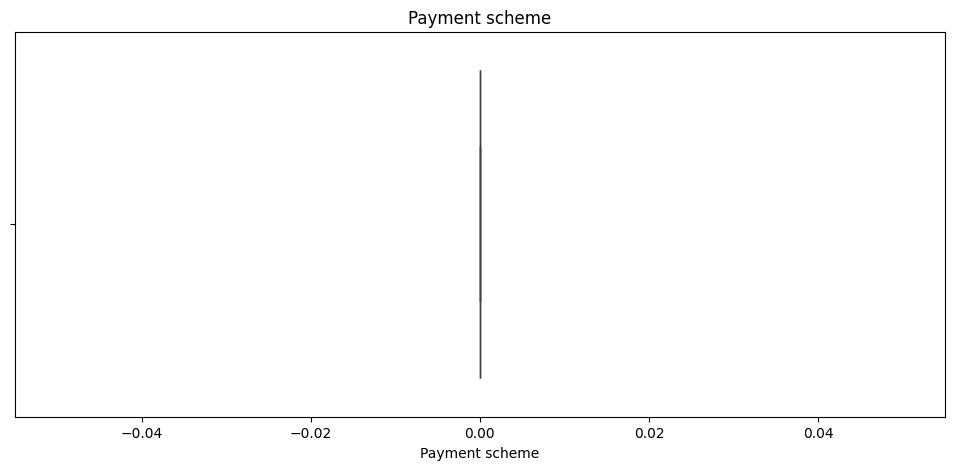

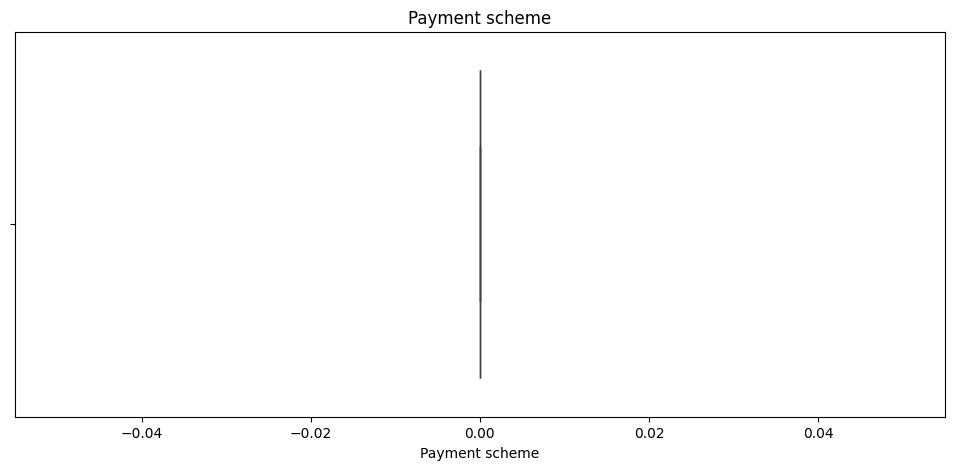

In [134]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Payment scheme")
plt.title("Payment scheme")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Payment scheme")
plt.title("Payment scheme")
plt.show()

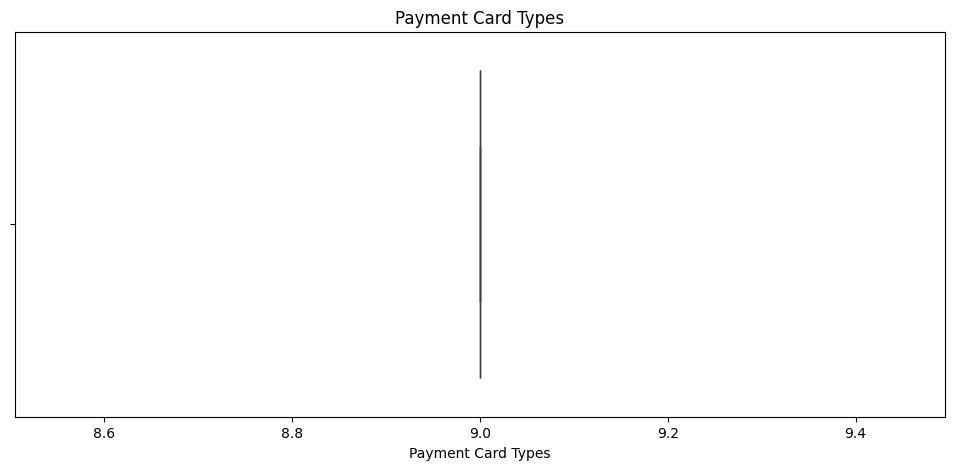

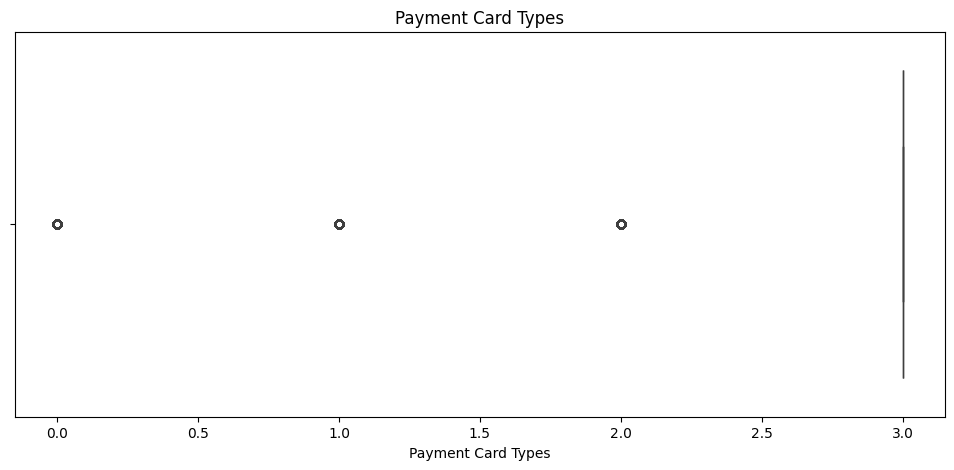

In [135]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Payment Card Types")
plt.title("Payment Card Types")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Payment Card Types")
plt.title("Payment Card Types")
plt.show()

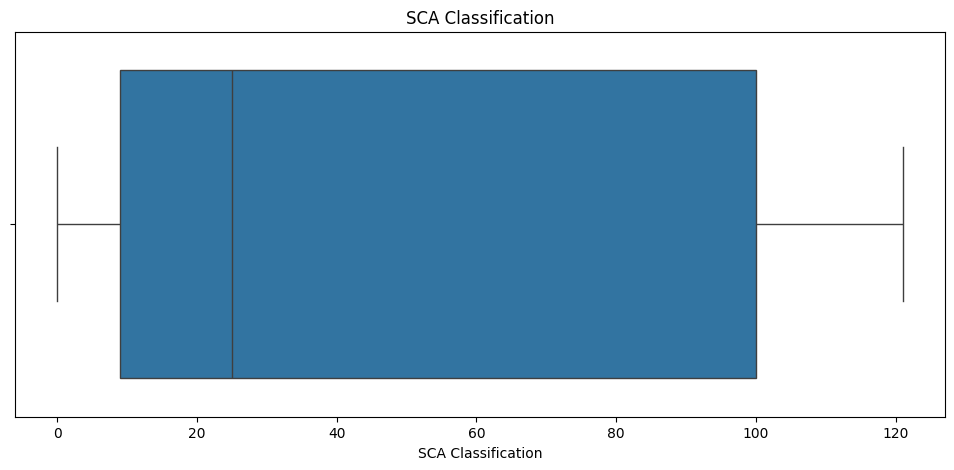

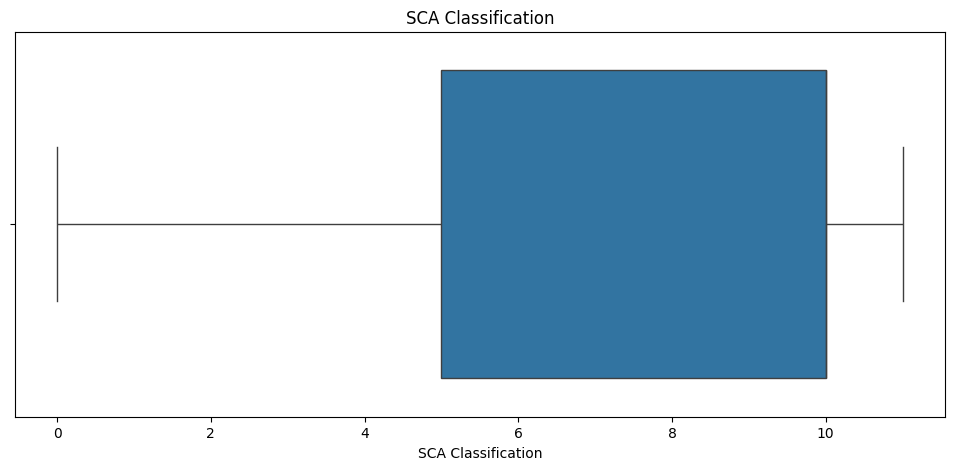

In [136]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="SCA Classification")
plt.title("SCA Classification")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="SCA Classification")
plt.title("SCA Classification")
plt.show()

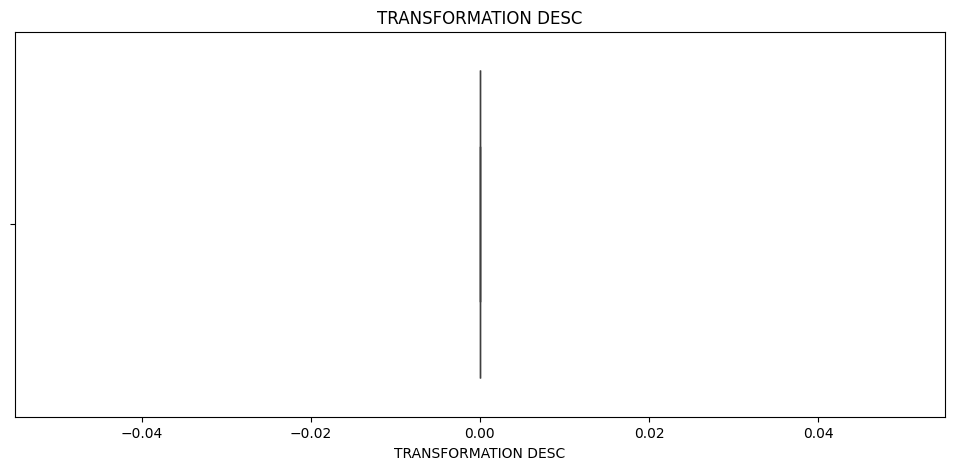

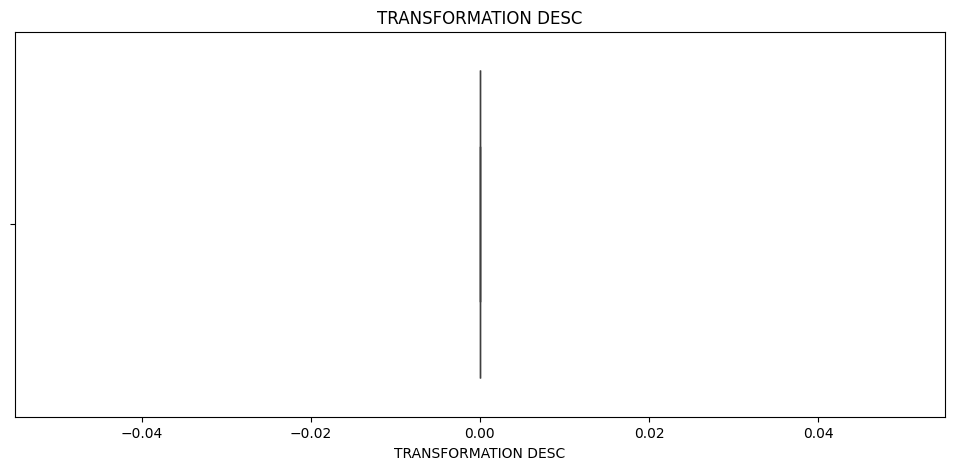

In [137]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="TRANSFORMATION DESC")
plt.title("TRANSFORMATION DESC")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="TRANSFORMATION DESC")
plt.title("TRANSFORMATION DESC")
plt.show()

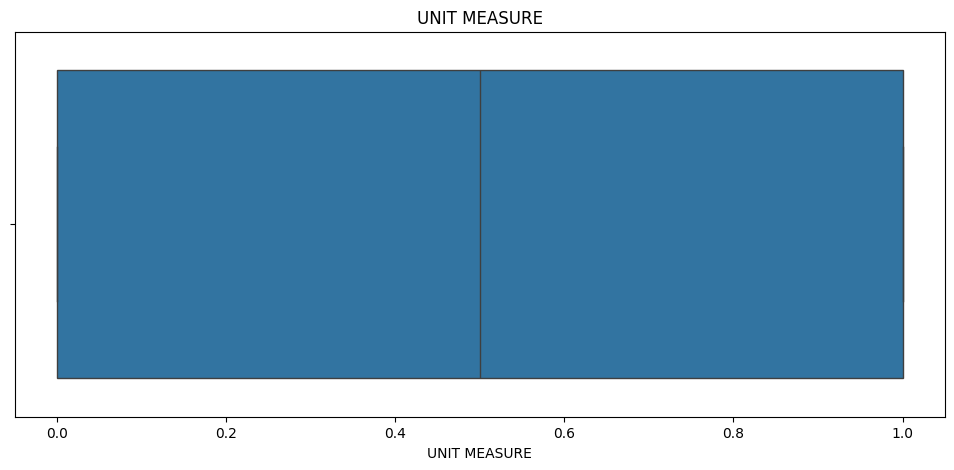

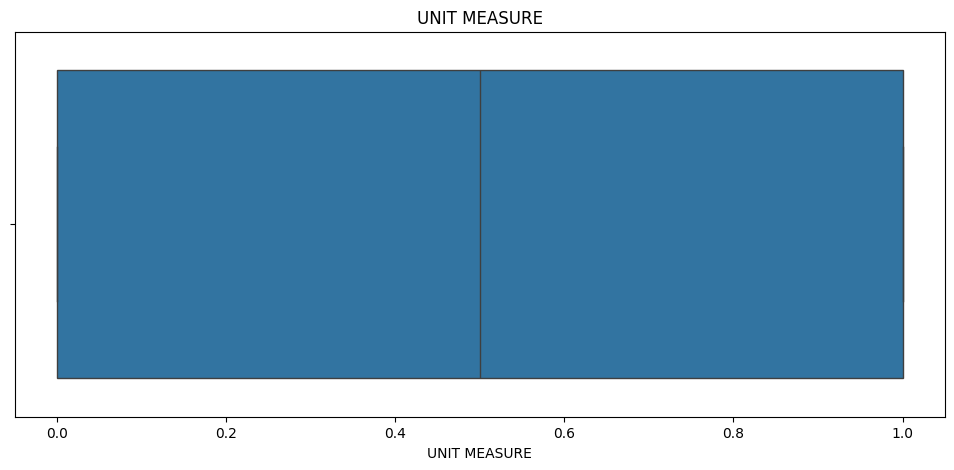

In [138]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="UNIT MEASURE")
plt.title("UNIT MEASURE")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="UNIT MEASURE")
plt.title("UNIT MEASURE")
plt.show()

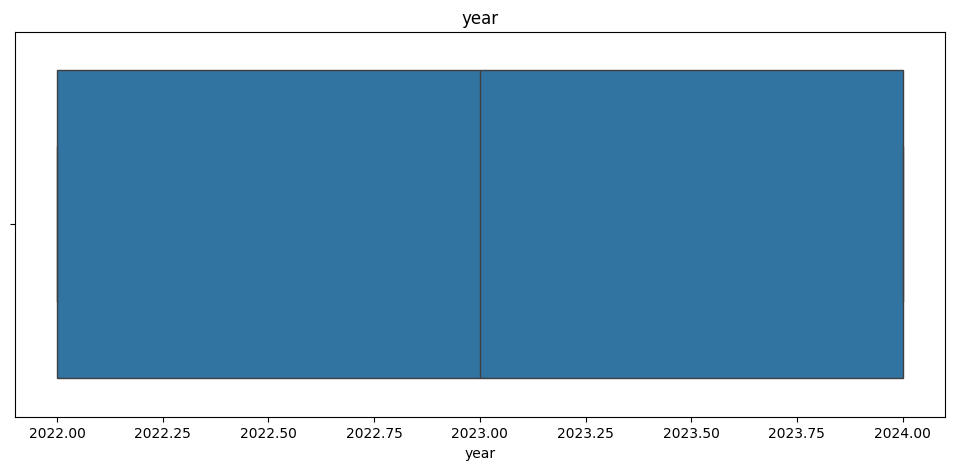

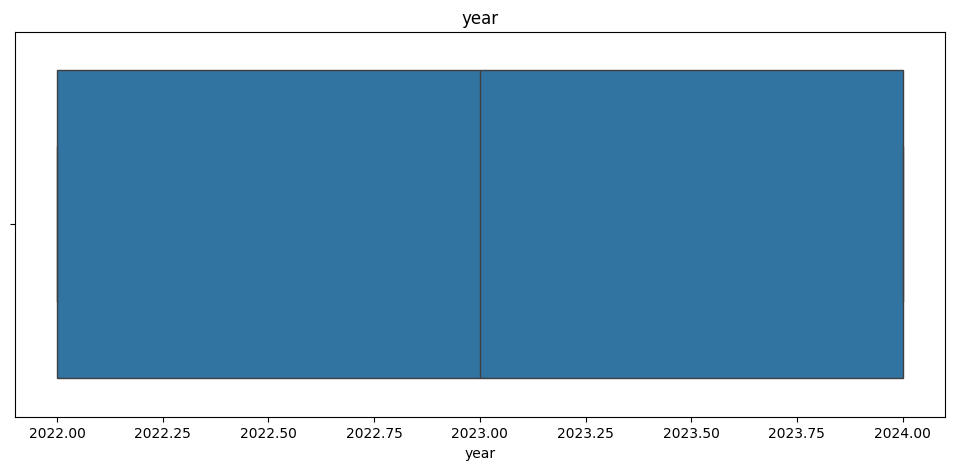

In [139]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="year")
plt.title("year")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="year")
plt.title("year")
plt.show()

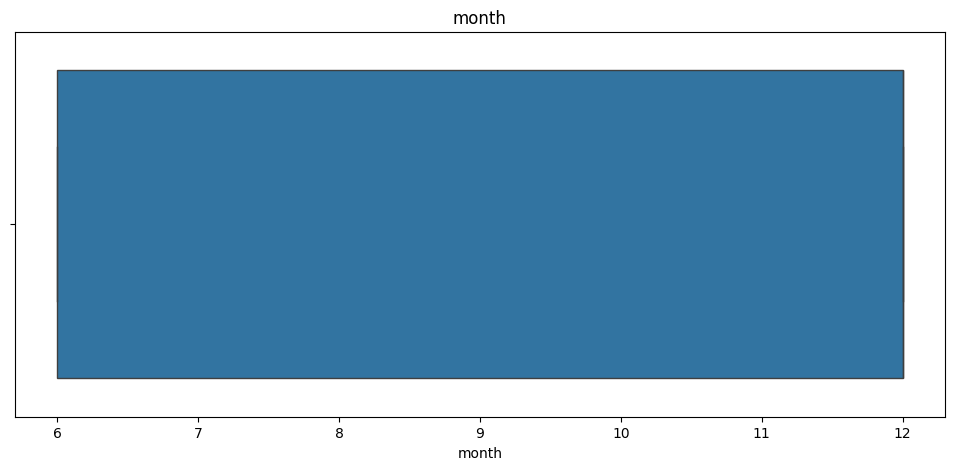

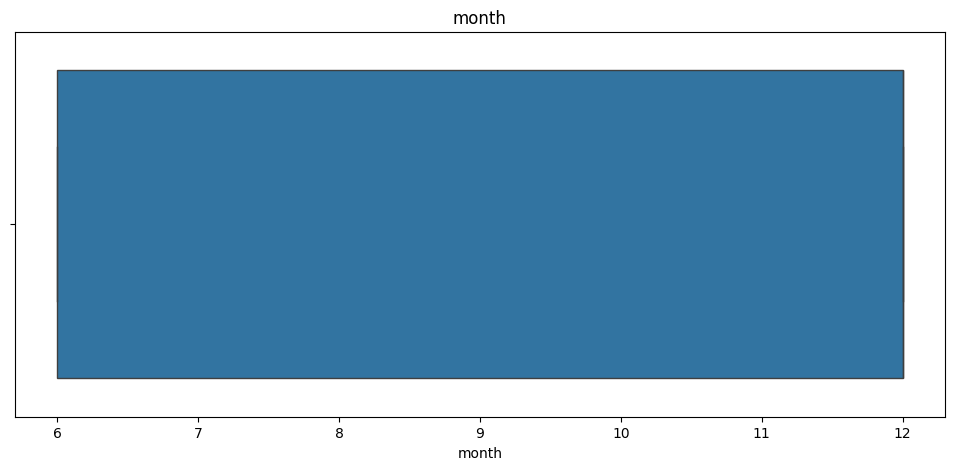

In [140]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="month")
plt.title("month")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="month")
plt.title("month")
plt.show()

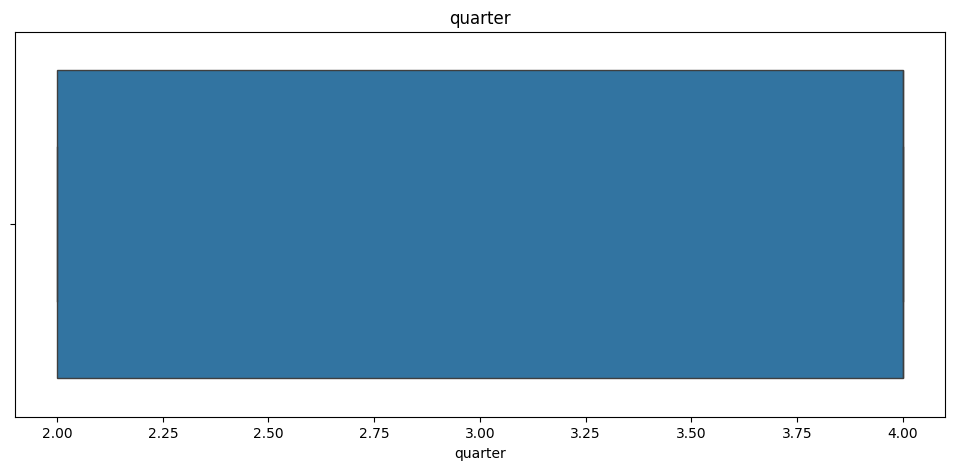

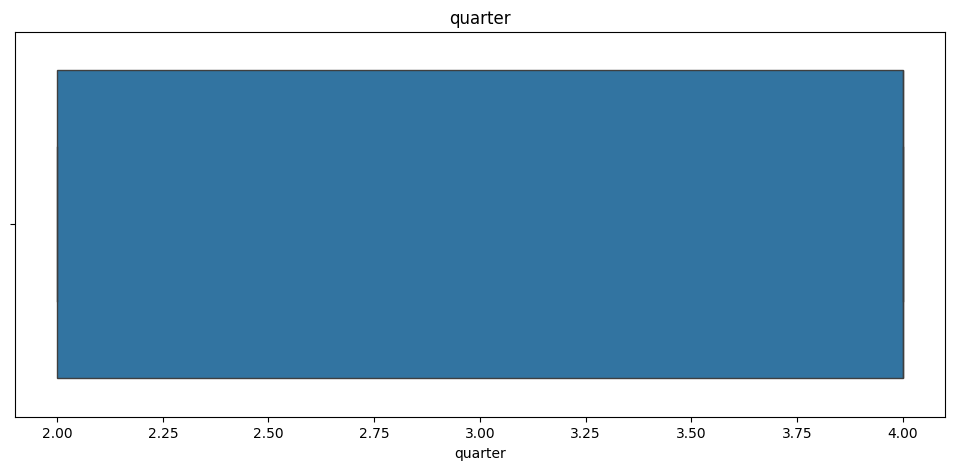

In [141]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="quarter")
plt.title("quarter")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="quarter")
plt.title("quarter")
plt.show()

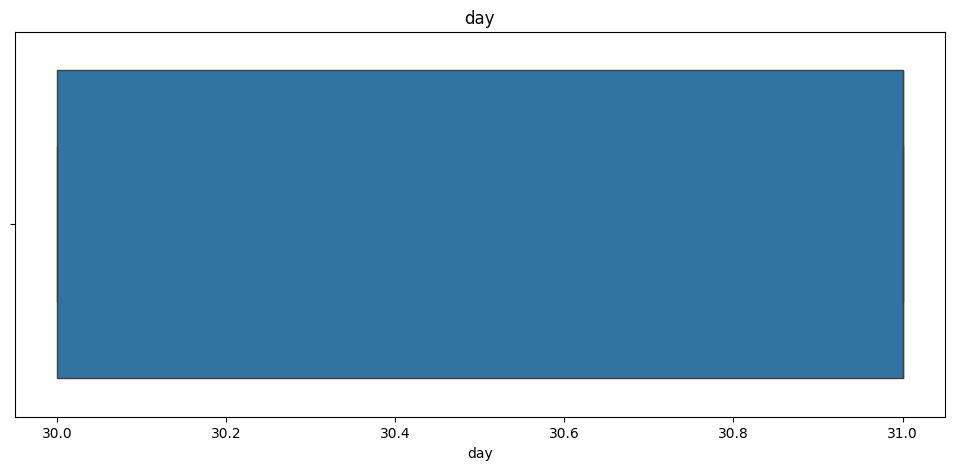

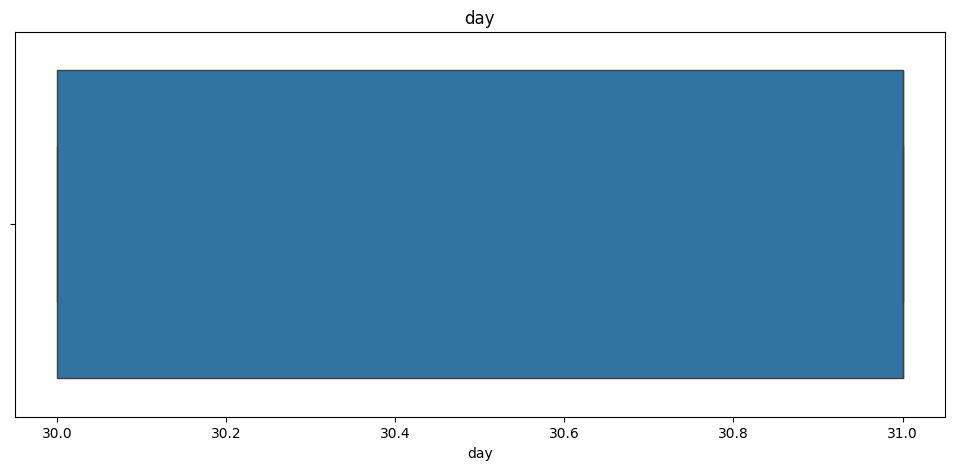

In [142]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="day")
plt.title("day")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="day")
plt.title("day")
plt.show()

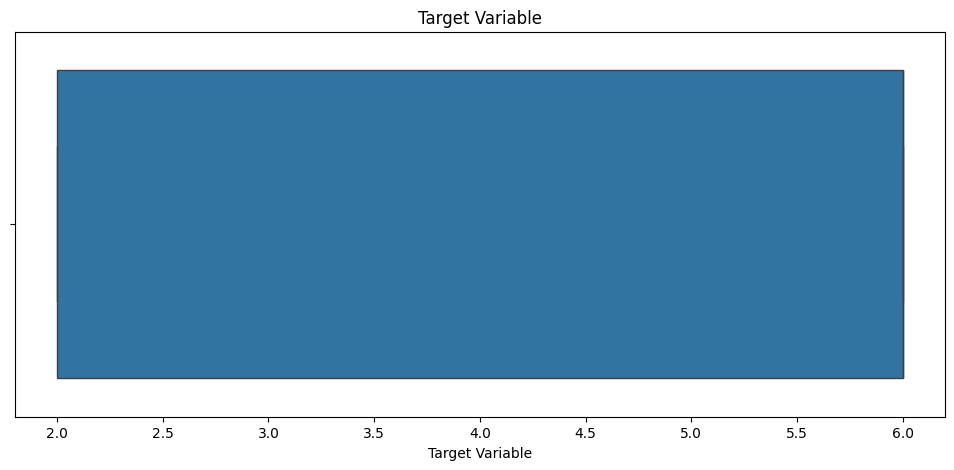

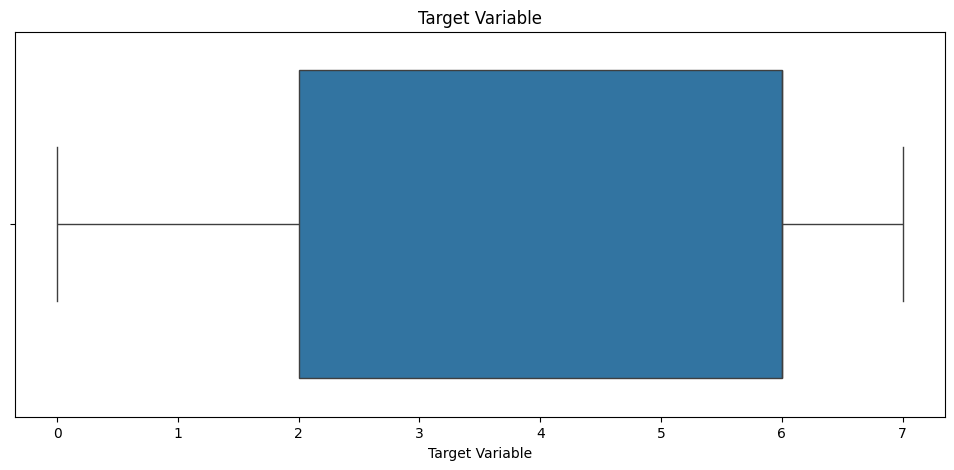

In [143]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_clean_no_outliers, x="Target Variable")
plt.title("Target Variable")
plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=df_final, x="Target Variable")
plt.title("Target Variable")
plt.show()

#### Probabilities, central tendency metrics and variation metrics, and perform a normality test

In [144]:
print("Card Types vs Fraud Types")
print("=" * 50)

# Get all unique card types
card_types = df["Payment Card Types"].unique()

print("Bayes Probability: P(Fraud | Card_Type)")
print("=" * 40)

for card in sorted(card_types):
    # Filter data for this card type
    card_data = df[df["Payment Card Types"] == card]
    total_card_transactions = len(card_data)
    
    if total_card_transactions > 0:
        print(f"\nCard Type {card}:")
        print(f"Total transactions: {total_card_transactions}")
        
        # Calculate probability for each fraud type
        for fraud_code in sorted(df["Target Variable"].unique()):
            fraud_count = len(card_data[card_data["Target Variable"] == fraud_code])
            probability = (fraud_count / total_card_transactions) * 100
            
            if probability > 0:
                print(f"  Fraud Code {fraud_code}: {probability:.2f}% ({fraud_count} cases)")

# Overall statistics
print("\n" + "=" * 40)
print("OVERALL STATISTICS:")
print(f"Total transactions: {len(df)}")
print(f"Unique card types: {len(card_types)}")

# Most risky card type overall
risk_scores = {}
for card in card_types:
    card_data = df[df["Payment Card Types"] == card]
    
    fraud_percentage = len(card_data[card_data["Target Variable"] != 6]) / len(card_data) * 100
    risk_scores[card] = fraud_percentage

most_risky = max(risk_scores, key=risk_scores.get)
print(f"\nMost risky card type: {most_risky}")
print(f"  Fraud rate: {risk_scores[most_risky]:.2f}%")

Card Types vs Fraud Types
Bayes Probability: P(Fraud | Card_Type)

Card Type 0:
Total transactions: 15928
  Fraud Code 2: 46.15% (7350 cases)
  Fraud Code 6: 53.85% (8578 cases)

Card Type 1:
Total transactions: 16936
  Fraud Code 2: 45.69% (7738 cases)
  Fraud Code 6: 54.31% (9198 cases)

Card Type 4:
Total transactions: 13894
  Fraud Code 2: 42.81% (5948 cases)
  Fraud Code 6: 57.19% (7946 cases)

Card Type 9:
Total transactions: 179920
  Fraud Code 0: 0.61% (1104 cases)
  Fraud Code 1: 0.62% (1108 cases)
  Fraud Code 2: 43.32% (77942 cases)
  Fraud Code 3: 0.64% (1156 cases)
  Fraud Code 4: 0.64% (1154 cases)
  Fraud Code 5: 0.62% (1122 cases)
  Fraud Code 6: 52.91% (95194 cases)
  Fraud Code 7: 0.63% (1140 cases)

OVERALL STATISTICS:
Total transactions: 226678
Unique card types: 4

Most risky card type: 9
  Fraud rate: 47.09%


In [145]:
df_final["Target Variable"].value_counts()

Target Variable
6    120916
2     98978
3      1156
4      1154
7      1140
5      1122
1      1108
0      1104
Name: count, dtype: int64

In [146]:
print("Country vs Fraud Types")
print("=" * 50)

# Get all unique countries
countries = df["Country"].unique()

for country in sorted(countries):
    # Filter data for this country
    country_data = df[df["Country"] == country]
    total_country_transactions = len(country_data)
    
    if total_country_transactions > 0:
        print(f"\nCountry Code {country}:")
        print(f"Total transactions: {total_country_transactions}")
        
        # Calculate probability for each fraud type
        for fraud_code in sorted(df["Target Variable"].unique()):
            fraud_count = len(country_data[country_data["Target Variable"] == fraud_code])
            probability = (fraud_count / total_country_transactions) * 100
            
            if probability > 0:
                print(f"  Fraud Code {fraud_code}: {probability:.2f}% ({fraud_count} cases)")

# Overall statistics
print("\n" + "=" * 40)
print("OVERALL STATISTICS:")
print(f"Total transactions: {len(df)}")
print(f"Unique countries: {len(countries)}")

# Most risky country overall
risk_scores = {}
for country in countries:
    country_data = df[df["Country"] == country]
    
    # Calculate % of transactions that are fraud (excluding 'Not applicable' code 6)
    fraud_percentage = len(country_data[country_data["Target Variable"] != 6]) / len(country_data) * 100
    risk_scores[country] = fraud_percentage

most_risky = max(risk_scores, key=risk_scores.get)
least_risky = min(risk_scores, key=risk_scores.get)

print(f"\nMost risky country: {most_risky}")
print(f"  Fraud rate: {risk_scores[most_risky]:.2f}%")
print(f"\nLeast risky country: {least_risky}")
print(f"  Fraud rate: {risk_scores[least_risky]:.2f}%")

# Show top 10 most risky countries
print("TOP 10 RISKIEST COUNTRIES:")
print("=" * 40)

sorted_countries = sorted(risk_scores.items(), key=lambda x: x[1], reverse=True)

for i, (country, score) in enumerate(sorted_countries[:10], 1):
    print(f"{i}. Country {country}: {score:.2f}% fraud rate")

Country vs Fraud Types

Country Code 0:
Total transactions: 7354
  Fraud Code 0: 0.49% (36 cases)
  Fraud Code 1: 0.49% (36 cases)
  Fraud Code 2: 43.46% (3196 cases)
  Fraud Code 3: 0.49% (36 cases)
  Fraud Code 4: 0.49% (36 cases)
  Fraud Code 5: 0.49% (36 cases)
  Fraud Code 6: 53.60% (3942 cases)
  Fraud Code 7: 0.49% (36 cases)

Country Code 1:
Total transactions: 7604
  Fraud Code 0: 0.47% (36 cases)
  Fraud Code 1: 0.47% (36 cases)
  Fraud Code 2: 45.29% (3444 cases)
  Fraud Code 3: 0.47% (36 cases)
  Fraud Code 4: 0.47% (36 cases)
  Fraud Code 5: 0.47% (36 cases)
  Fraud Code 6: 51.87% (3944 cases)
  Fraud Code 7: 0.47% (36 cases)

Country Code 2:
Total transactions: 7188
  Fraud Code 0: 0.50% (36 cases)
  Fraud Code 1: 0.50% (36 cases)
  Fraud Code 2: 43.54% (3130 cases)
  Fraud Code 3: 0.53% (38 cases)
  Fraud Code 4: 0.53% (38 cases)
  Fraud Code 5: 0.50% (36 cases)
  Fraud Code 6: 53.39% (3838 cases)
  Fraud Code 7: 0.50% (36 cases)

Country Code 3:
Total transactions: 7312

In [147]:
print("SCA Classification vs Fraud Types")
print("=" * 50)

# Get all unique SCA classifications
sca_types = df["SCA Classification"].unique()

for sca in sorted(sca_types):
    # Filter data for this SCA classification
    sca_data = df[df["SCA Classification"] == sca]
    total_sca_transactions = len(sca_data)
    
    if total_sca_transactions > 0:
        print(f"\nSCA Classification {sca}:")
        print(f"Total transactions: {total_sca_transactions}")
        
        # Calculate probability for each fraud type
        for fraud_code in sorted(df["Target Variable"].unique()):
            fraud_count = len(sca_data[sca_data["Target Variable"] == fraud_code])
            probability = (fraud_count / total_sca_transactions) * 100
            
            if probability > 0:
                print(f"  Fraud Code {fraud_code}: {probability:.2f}% ({fraud_count} cases)")

# Overall statistics
print("\n" + "=" * 40)
print("OVERALL STATISTICS:")
print(f"Total transactions: {len(df)}")
print(f"Unique SCA classifications: {len(sca_types)}")

# Most risky SCA classification overall
risk_scores = {}
for sca in sca_types:
    sca_data = df[df["SCA Classification"] == sca]
    
    # Calculate % of transactions that are fraud (excluding 'Not applicable' code 6)
    fraud_percentage = len(sca_data[sca_data["Target Variable"] != 6]) / len(sca_data) * 100
    risk_scores[sca] = fraud_percentage

most_risky = max(risk_scores, key=risk_scores.get)
least_risky = min(risk_scores, key=risk_scores.get)

print(f"\nMost risky SCA classification: {most_risky}")
print(f"  Fraud rate: {risk_scores[most_risky]:.2f}%")
print(f"\nLeast risky SCA classification: {least_risky}")
print(f"  Fraud rate: {risk_scores[least_risky]:.2f}%")

# Show all SCA classifications sorted by risk
print("ALL SCA CLASSIFICATIONS BY RISK:")
print("=" * 40)

sorted_sca = sorted(risk_scores.items(), key=lambda x: x[1], reverse=True)

for i, (sca, score) in enumerate(sorted_sca, 1):
    count = len(df[df["SCA Classification"] == sca])
    print(f"{i}. SCA {sca}: {score:.2f}% fraud rate ({count} transactions)")

SCA Classification vs Fraud Types

SCA Classification 0:
Total transactions: 12410
  Fraud Code 2: 40.31% (5002 cases)
  Fraud Code 6: 59.69% (7408 cases)

SCA Classification 1:
Total transactions: 6536
  Fraud Code 2: 43.97% (2874 cases)
  Fraud Code 6: 56.03% (3662 cases)

SCA Classification 4:
Total transactions: 6348
  Fraud Code 2: 42.19% (2678 cases)
  Fraud Code 6: 57.81% (3670 cases)

SCA Classification 9:
Total transactions: 6956
  Fraud Code 2: 47.24% (3286 cases)
  Fraud Code 6: 52.76% (3670 cases)

SCA Classification 16:
Total transactions: 13376
  Fraud Code 2: 45.04% (6024 cases)
  Fraud Code 6: 54.96% (7352 cases)

SCA Classification 25:
Total transactions: 11142
  Fraud Code 2: 47.08% (5246 cases)
  Fraud Code 6: 52.92% (5896 cases)

SCA Classification 36:
Total transactions: 2902
  Fraud Code 2: 45.55% (1322 cases)
  Fraud Code 6: 54.45% (1580 cases)

SCA Classification 49:
Total transactions: 7060
  Fraud Code 2: 47.56% (3358 cases)
  Fraud Code 6: 52.44% (3702 cases)

In [148]:
print("Transaction Amount vs Fraud Types")
print("=" * 50)

# Since Transaction is a continuous variable, I need to create bins
# transaction amount categories
df['Transaction_Category'] = pd.cut(df['Transaction'], 
                                    bins=[0, 100, 500, 1000, 5000, 10000, 50000, 100000, np.inf],
                                    labels=['0-100', '101-500', '501-1000', '1001-5000', 
                                           '5001-10000', '10001-50000', '50001-100000', '100000+'])

# Get all unique transaction categories
transaction_cats = df['Transaction_Category'].unique()

print("Bayes Probability: P(Fraud | Transaction_Category)")
print("=" * 40)

for cat in sorted(transaction_cats, key=lambda x: str(x)):
    # Filter data for this transaction category
    cat_data = df[df['Transaction_Category'] == cat]
    total_cat_transactions = len(cat_data)
    
    if total_cat_transactions > 0:
        print(f"\nTransaction Category {cat}:")
        print(f"Total transactions: {total_cat_transactions}")
        print(f"Avg amount: €{cat_data['Transaction'].mean():.2f}")
        print(f"Median amount: €{cat_data['Transaction'].median():.2f}")
        
        # Calculate probability for each fraud type
        for fraud_code in sorted(df['Target Variable'].unique()):
            fraud_count = len(cat_data[cat_data['Target Variable'] == fraud_code])
            probability = (fraud_count / total_cat_transactions) * 100
            
            if probability > 0:
                print(f"  Fraud Code {fraud_code}: {probability:.2f}% ({fraud_count} cases)")

# Overall statistics
print("\n" + "=" * 40)
print("OVERALL STATISTICS:")
print(f"Total transactions: {len(df)}")
print(f"Min transaction: €{df['Transaction'].min():.2f}")
print(f"Max transaction: €{df['Transaction'].max():.2f}")
print(f"Avg transaction: €{df['Transaction'].mean():.2f}")
print(f"Median transaction: €{df['Transaction'].median():.2f}")

# Most risky transaction category overall
risk_scores = {}
for cat in transaction_cats:
    cat_data = df[df['Transaction_Category'] == cat]
    
    if len(cat_data) > 0:
        # Calculate % of transactions that are fraud (excluding 'Not applicable' code 6)
        fraud_percentage = len(cat_data[cat_data['Target Variable'] != 6]) / len(cat_data) * 100
        risk_scores[cat] = fraud_percentage

most_risky = max(risk_scores, key=risk_scores.get)
least_risky = min(risk_scores, key=risk_scores.get)

print(f"\nMost risky transaction category: {most_risky}")
print(f"  Fraud rate: {risk_scores[most_risky]:.2f}%")
print(f"\nLeast risky transaction category: {least_risky}")
print(f"  Fraud rate: {risk_scores[least_risky]:.2f}%")

# Show all transaction categories sorted by risk
print("\n" + "=" * 40)
print("TRANSACTION CATEGORIES BY RISK:")
print("=" * 40)

sorted_cats = sorted(risk_scores.items(), key=lambda x: x[1], reverse=True)

for i, (cat, score) in enumerate(sorted_cats, 1):
    cat_data = df[df['Transaction_Category'] == cat]
    count = len(cat_data)
    avg_amount = cat_data['Transaction'].mean()
    print(f"{i}. Category {cat}: {score:.2f}% fraud rate")
    print(f"   {count} transactions, Avg: €{avg_amount:.2f}")

Transaction Amount vs Fraud Types
Bayes Probability: P(Fraud | Transaction_Category)

Transaction Category 0-100:
Total transactions: 91478
Avg amount: €1.22
Median amount: €1.22
  Fraud Code 2: 44.90% (41070 cases)
  Fraud Code 6: 55.10% (50408 cases)

OVERALL STATISTICS:
Total transactions: 226678
Min transaction: €-0.82
Max transaction: €1.22
Avg transaction: €-0.00
Median transaction: €-0.82

Most risky transaction category: 0-100
  Fraud rate: 44.90%

Least risky transaction category: 0-100
  Fraud rate: 44.90%

TRANSACTION CATEGORIES BY RISK:
1. Category 0-100: 44.90% fraud rate
   91478 transactions, Avg: €1.22


In [149]:
print("Target Variable vs Quarter")
print("=" * 60)

if 'Target Variable' in df_final.columns and "quarter" in df_final.columns:
    # Get ALL target values (0-7)
    all_targets = sorted(df_final["Target Variable"].unique())
    all_quarters = sorted(df_final["quarter"].unique())
    
    # 1. Contingency table with ALL values
    contingency = pd.crosstab(df_final["Target Variable"], df_final["quarter"])
    print("COMPLETE CONTINGENCY TABLE:")
    print(contingency)
    
    # 2. Statistical test
    chi2, p, dof, expected = chi2_contingency(contingency)
    print(f"\nSTATISTICAL TEST:")
    print(f"Chi-square: {chi2:.4f}")
    print(f"p-value: {p:.6f}")
    print(f"Degrees of freedom: {dof}")
    
    # 3. Effect size
    n = contingency.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))
    print(f"Cramer's V (effect size): {cramers_v:.4f}")
    
    # 4. Interpretation
    print(f"\nINTERPRETATION:")
    if p < 0.05:
        print("✓ SIGNIFICANT: Transaction categories DISTRIBUTION differs by quarter")
        print(f"  (p = {p:.6f} < 0.05)")
        
        
        print(f"\nDISTRIBUTION BY QUARTER (percentage of each category):")
        # Calculate percentages
        percent_table = pd.crosstab(df_final["Target Variable"], df_final["quarter"], 
                                    normalize='columns') * 100
        
        for quarter in all_quarters:
            print(f"\n  Quarter {quarter}:")
            for target in all_targets:
                if target in percent_table.index and quarter in percent_table.columns:
                    pct = percent_table.loc[target, quarter]
                    count = contingency.loc[target, quarter]
                    print(f"    Target {target}: {count:,} ({pct:.1f}%)")
                    
    else:
        print("NOT SIGNIFICANT: Transaction categories are SIMILAR across quarters")
        print(f"  (p = {p:.6f} ≥ 0.05)")
        print(f"  → The proportion of each transaction type (0-7) doesn't change by quarter")

Target Variable vs Quarter
COMPLETE CONTINGENCY TABLE:
quarter              2      4
Target Variable              
0                  552    552
1                  556    552
2                49238  49740
3                  570    586
4                  568    586
5                  558    564
6                60250  60666
7                  570    570

STATISTICAL TEST:
Chi-square: 0.5110
p-value: 0.999405
Degrees of freedom: 7
Cramer's V (effect size): 0.0015

INTERPRETATION:
NOT SIGNIFICANT: Transaction categories are SIMILAR across quarters
  (p = 0.999405 ≥ 0.05)
  → The proportion of each transaction type (0-7) doesn't change by quarter


In [150]:
print("Target Variable vs Month")
print("=" * 60)

if "Target Variable" in df_final.columns and "month" in df_final.columns:
    contingency2 = pd.crosstab(df_final["Target Variable"], df_final["month"])
    print("Contingency Table:")
    print(contingency2)
    
    chi2_2, p2, dof2, expected2 = chi2_contingency(contingency2)
    print(f"\nChi-square: {chi2_2:.4f}")
    print(f"p-value: {p2:.6f}")
        
    if p2 < 0.05:
        print("SIGNIFICANT: Month and Fraud are RELATED (p < 0.05)")
        n = contingency2.sum().sum()
        cramers_v = np.sqrt(chi2_2 / (n * (min(contingency2.shape) - 1)))
        print(f"Cramer's V (effect size): {cramers_v:.4f}")
    else:
        print("NOT SIGNIFICANT: No relationship between Month and Fraud")


Target Variable vs Month
Contingency Table:
month               6      12
Target Variable              
0                  552    552
1                  556    552
2                49238  49740
3                  570    586
4                  568    586
5                  558    564
6                60250  60666
7                  570    570

Chi-square: 0.5110
p-value: 0.999405
NOT SIGNIFICANT: No relationship between Month and Fraud


In [151]:
print("Target Variable vs Payment Card Types")
print("=" * 60)

if "Target Variable" in df_final.columns and "Payment Card Types" in df_final.columns:
    contingency4 = pd.crosstab(df_final["Target Variable"], df_final["Payment Card Types"])
    print("Contingency Table:")
    print(contingency4)
    
    chi2_4, p4, dof4, expected4 = chi2_contingency(contingency4)
    print(f"\nChi-square: {chi2_4:.4f}")
    print(f"p-value: {p4:.10f}")
        
    if p4 < 0.05:
        print("SIGNIFICANT: Payment Card Types and Fraud are RELATED (p < 0.05)")
        n = contingency4.sum().sum()
        cramers_v = np.sqrt(chi2_4 / (n * (min(contingency4.shape) - 1)))
        print(f"Cramer's V (effect size): {cramers_v:.4f}")
    else:
        print("NOT SIGNIFICANT: No relationship between Payment Card Types and Fraud")

Target Variable vs Payment Card Types
Contingency Table:
Payment Card Types     0     1     2      3
Target Variable                            
0                      0     0     0   1104
1                      0     0     0   1108
2                   7350  7738  5948  77942
3                      0     0     0   1156
4                      0     0     0   1154
5                      0     0     0   1122
6                   8578  9198  7946  95194
7                      0     0     0   1140

Chi-square: 1857.2544
p-value: 0.0000000000
SIGNIFICANT: Payment Card Types and Fraud are RELATED (p < 0.05)
Cramer's V (effect size): 0.0523


In [152]:
print("Target Variable vs SCA Classification")
print("=" * 60)

if "Target Variable" in df_final.columns and "SCA Classification" in df_final.columns:
    contingency5 = pd.crosstab(df_final["Target Variable"], df_final["SCA Classification"])
    print("Contingency Table:")
    print(contingency5)
    
    chi2_5, p5, dof5, expected5 = chi2_contingency(contingency5)
    print(f"\nChi-square: {chi2_5:.4f}")
    print(f"p-value: {p5:.10f}")
        
    if p5 < 0.05:
        print("SIGNIFICANT: SCA Classification and Fraud are RELATED (p < 0.05)")
        n = contingency5.sum().sum()
        cramers_v = np.sqrt(chi2_5 / (n * (min(contingency5.shape) - 1)))
        print(f"Cramer's V (effect size): {cramers_v:.4f}")
    else:
        print("NOT SIGNIFICANT: No relationship between SCA Classification and Fraud")

Target Variable vs SCA Classification
Contingency Table:
SCA Classification    0     1     2     3     4     5     6     7     8   \
Target Variable                                                            
0                      0     0     0     0     0     0     0     0     0   
1                      0     0     0     0     0     0     0     0     0   
2                   5002  2874  2678  3286  6024  5246  1322  3358  2262   
3                      0     0     0     0     0     0     0     0     0   
4                      0     0     0     0     0     0     0     0     0   
5                      0     0     0     0     0     0     0     0     0   
6                   7408  3662  3670  3670  7352  5896  1580  3702  2696   
7                      0     0     0     0     0     0     0     0     0   

SCA Classification    9      10    11  
Target Variable                        
0                      0   1104     0  
1                      0   1108     0  
2                   23

In [153]:
print("Target Variable vs Country")
print("=" * 60)

if "Target Variable" in df_final.columns and "Country" in df_final.columns:
    contingency6 = pd.crosstab(df_final["Target Variable"], df_final["Country"])
    print("Contingency Table (first 10 countries):")
    print(contingency6.iloc[:, :10])  # Show first 10 columns
    
    chi2_6, p6, dof6, expected6 = chi2_contingency(contingency6)
    print(f"\nChi-square: {chi2_6:.4f}")
    print(f"p-value: {p6:.10f}")
        
    if p6 < 0.05:
        print("SIGNIFICANT: Country and Fraud are RELATED (p < 0.05)")
        n = contingency6.sum().sum()
        cramers_v = np.sqrt(chi2_6 / (n * (min(contingency6.shape) - 1)))
        print(f"Cramer's V (effect size): {cramers_v:.4f}")
    else:
        print("NOT SIGNIFICANT: No relationship between Country and Fraud")

Target Variable vs Country
Contingency Table (first 10 countries):
Country             0     1     2     3     4     5     6     7     8     9
Target Variable                                                            
0                  36    36    36    36    36    36    36    36    36    36
1                  36    36    36    36    36    36    36    36    36    36
2                3196  3444  3130  3212  3172  3510  3170  3078  3528  2948
3                  36    36    38    36    38    36    36    36    38    36
4                  36    36    38    36    38    36    36    36    38    36
5                  36    36    36    36    36    36    36    36    36    36
6                3942  3944  3838  3884  3934  3994  3918  3876  3982  3870
7                  36    36    36    36    36    36    36    36    36    36

Chi-square: 279.6540
p-value: 0.0009228576
SIGNIFICANT: Country and Fraud are RELATED (p < 0.05)
Cramer's V (effect size): 0.0133


In [154]:
print("Target Variable vs Geographic Area")
print("=" * 60)

if "Target Variable" in df_final.columns and "Geographic Area" in df_final.columns:
    contingency7 = pd.crosstab(df_final["Target Variable"], df_final["Geographic Area"])
    print("Contingency Table:")
    print(contingency7)
    
    chi2_7, p7, dof7, expected7 = chi2_contingency(contingency7)
    print(f"\nChi-square: {chi2_7:.4f}")
    print(f"p-value: {p7:.10f}")
    print(f"Degrees of freedom: {dof7}")
    
    if p7 < 0.05:
        print("SIGNIFICANT: Geographic Area and Fraud are RELATED (p < 0.05)")
        n = contingency7.sum().sum()
        cramers_v = np.sqrt(chi2_7 / (n * (min(contingency7.shape) - 1)))
        print(f"Cramer's V (effect size): {cramers_v:.4f}")
    else:
        print("NOT SIGNIFICANT: No relationship between Geographic Area and Fraud")

Target Variable vs Geographic Area
Contingency Table:
Geographic Area      0      1      2      3      4
Target Variable                                   
0                   12     12    348    360    372
1                   12     14    348    362    372
2                11810  11836  24896  25140  25296
3                   12     40    360    372    372
4                   12     38    360    372    372
5                   12     18    354    366    372
6                22142  20938  25840  25956  26040
7                   12     24    360    372    372

Chi-square: 5954.4479
p-value: 0.0000000000
Degrees of freedom: 28
SIGNIFICANT: Geographic Area and Fraud are RELATED (p < 0.05)
Cramer's V (effect size): 0.0810


In [155]:
print("Target Variable vs Transaction Channels")
print("=" * 60)

if "Target Variable" in df_final.columns and "Transaction Channels" in df_final.columns:
    contingency8 = pd.crosstab(df_final["Target Variable"], df_final["Transaction Channels"])
    print("Contingency Table:")
    print(contingency8)
    
    chi2_8, p8, dof8, expected8 = chi2_contingency(contingency8)
    print(f"\nChi-square: {chi2_8:.4f}")
    print(f"p-value: {p8:.10f}")
        
    if p8 < 0.05:
        print("SIGNIFICANT: Transaction Channels and Fraud are RELATED (p < 0.05)")
        n = contingency8.sum().sum()
        cramers_v = np.sqrt(chi2_8 / (n * (min(contingency8.shape) - 1)))
        print(f"Cramer's V (effect size): {cramers_v:.4f}")
    else:
        print("NOT SIGNIFICANT: No relationship between Transaction Channels and Fraud")

Target Variable vs Transaction Channels
Contingency Table:
Transaction Channels     0     1     2      3     4      5     6     7
Target Variable                                                       
0                        0  1104     0      0     0      0     0     0
1                        0  1108     0      0     0      0     0     0
2                     2208  8132  6038  67592  1520   8160  3974  1354
3                        0  1156     0      0     0      0     0     0
4                        0  1154     0      0     0      0     0     0
5                        0  1122     0      0     0      0     0     0
6                     2378  9568  7408  82908  1852  10614  4704  1484
7                        0  1140     0      0     0      0     0     0

Chi-square: 57805.7226
p-value: 0.0000000000
SIGNIFICANT: Transaction Channels and Fraud are RELATED (p < 0.05)
Cramer's V (effect size): 0.1909


In [156]:
print("Target Variable vs Payment Scheme")
print("=" * 60)

if "Target Variable" in df_final.columns and "Payment scheme" in df_final.columns:
    contingency9 = pd.crosstab(df_final["Target Variable"], df_final["Payment scheme"])
    print("Contingency Table:")
    print(contingency9)
    
    chi2_9, p9, dof9, expected9 = chi2_contingency(contingency9)
    print(f"\nChi-square: {chi2_9:.4f}")
    print(f"p-value: {p9:.10f}")
        
    if p9 < 0.05:
        print("SIGNIFICANT: Payment Scheme and Fraud are RELATED (p < 0.05)")
        n = contingency9.sum().sum()
        cramers_v = np.sqrt(chi2_9 / (n * (min(contingency9.shape) - 1)))
        print(f"Cramer's V (effect size): {cramers_v:.4f}")
    else:
        print("NOT SIGNIFICANT: No relationship between Payment Scheme and Fraud")

Target Variable vs Payment Scheme
Contingency Table:
Payment scheme        0
Target Variable        
0                  1104
1                  1108
2                 98978
3                  1156
4                  1154
5                  1122
6                120916
7                  1140

Chi-square: 0.0000
p-value: 1.0000000000
NOT SIGNIFICANT: No relationship between Payment Scheme and Fraud


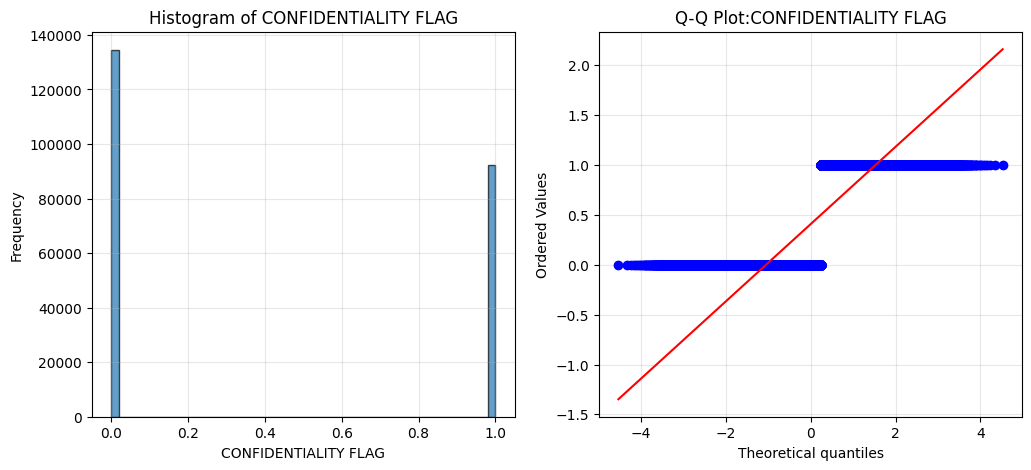

In [157]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["CONFIDENTIALITY FLAG"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("CONFIDENTIALITY FLAG")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of CONFIDENTIALITY FLAG")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot:CONFIDENTIALITY FLAG")
ax2.grid(True, alpha=0.3)

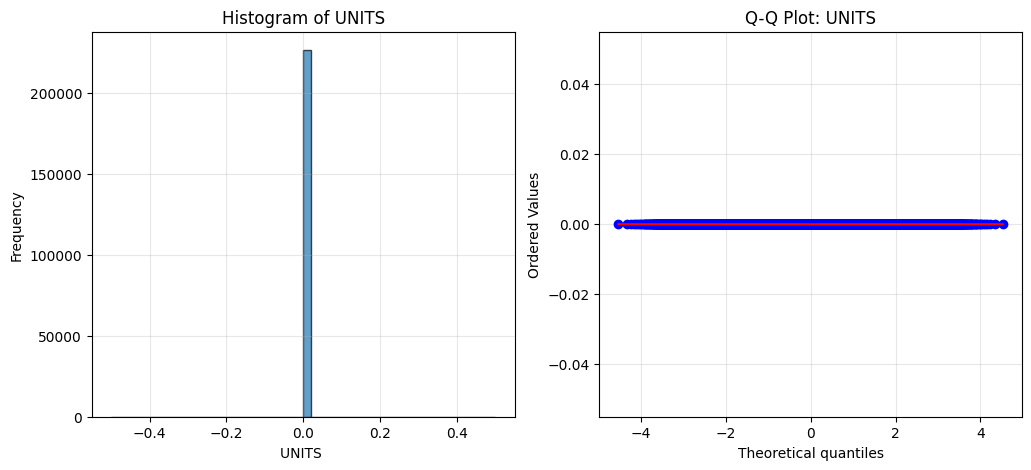

In [158]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["UNITS"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("UNITS ")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of UNITS")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: UNITS")
ax2.grid(True, alpha=0.3)

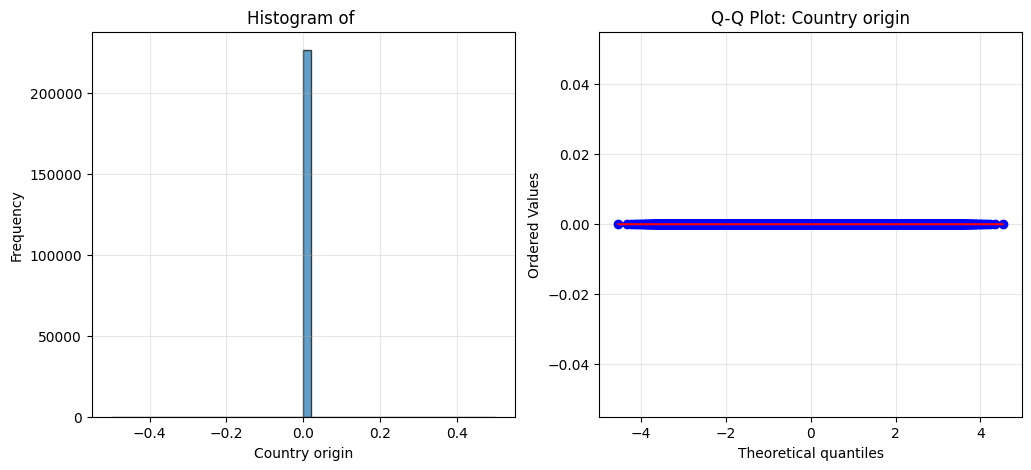

In [159]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Country origin"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Country origin")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of ")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Country origin")
ax2.grid(True, alpha=0.3)

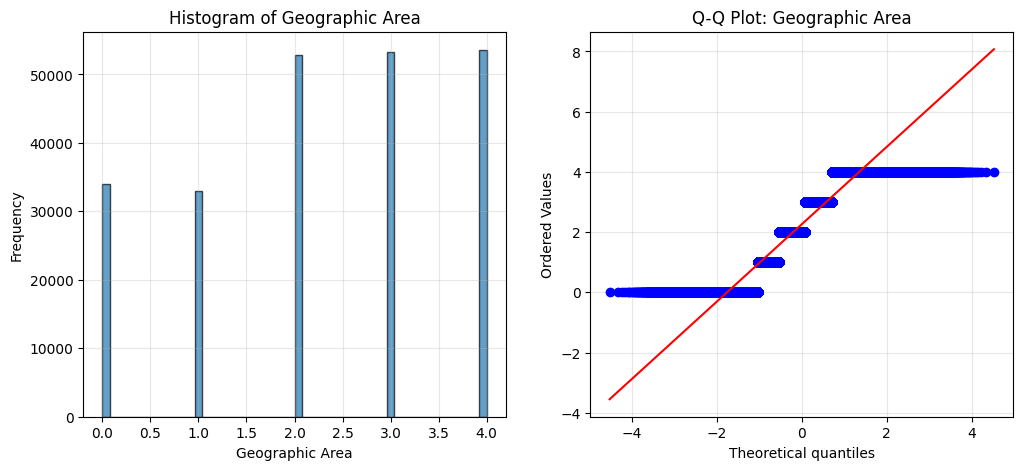

In [160]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Geographic Area"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Geographic Area")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Geographic Area")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Geographic Area")
ax2.grid(True, alpha=0.3)

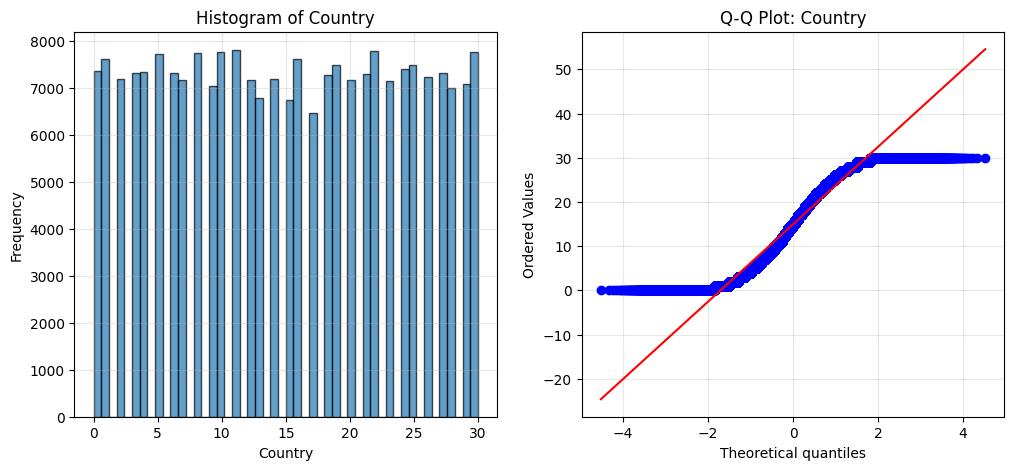

In [161]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Country"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Country")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Country")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Country")
ax2.grid(True, alpha=0.3)

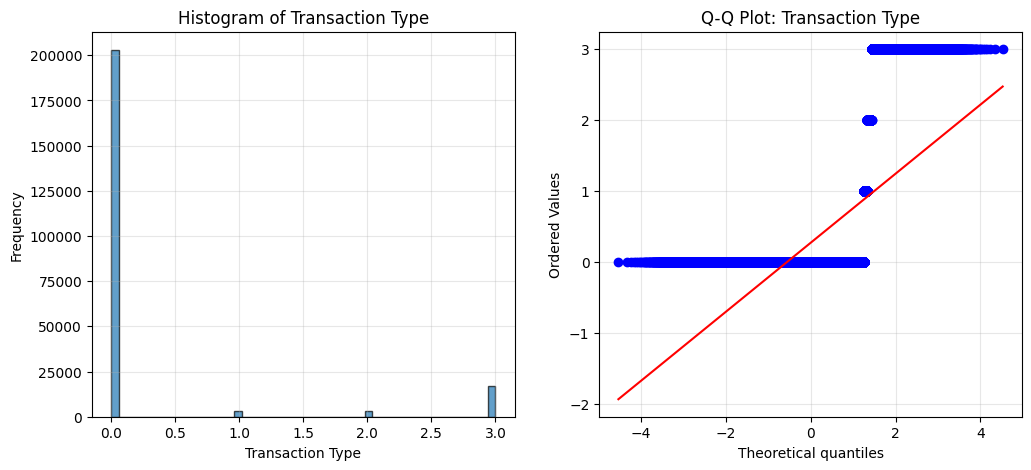

In [162]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Transaction Type"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Transaction Type")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Transaction Type")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Transaction Type")
ax2.grid(True, alpha=0.3)

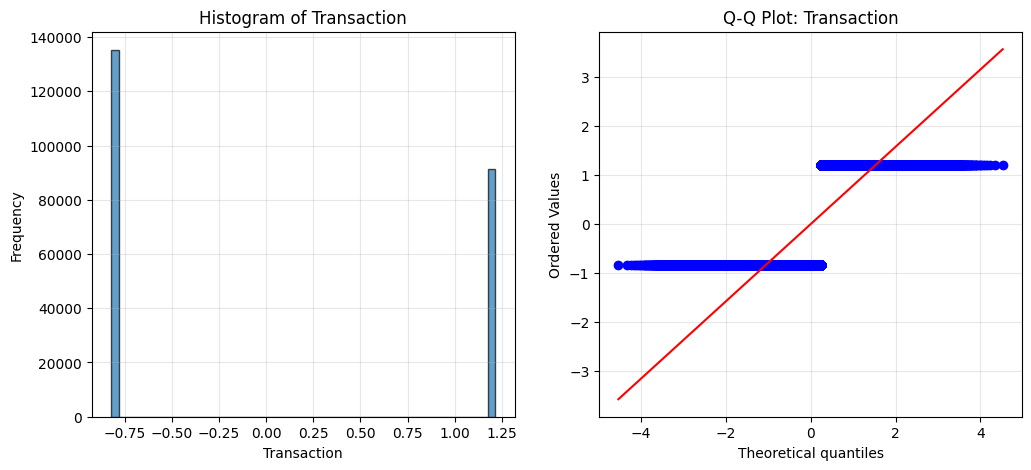

In [163]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Transaction"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Transaction")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Transaction")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Transaction")
ax2.grid(True, alpha=0.3)

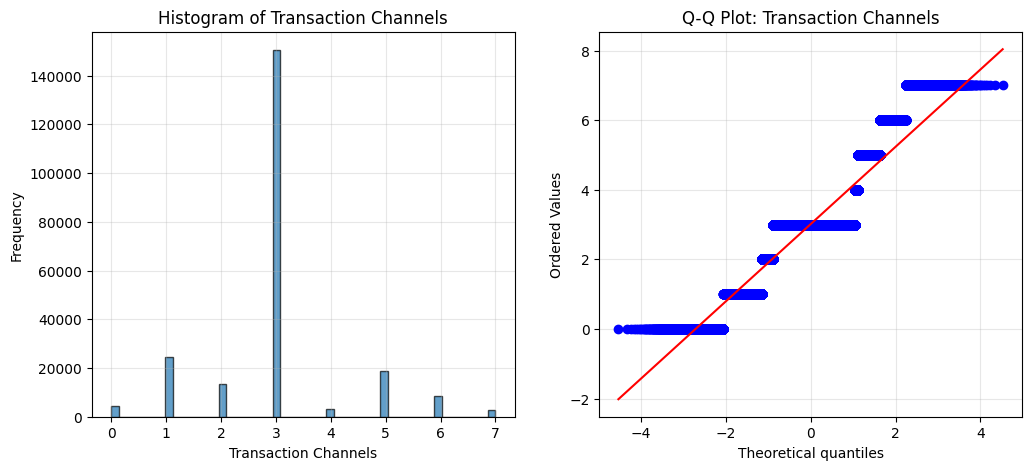

In [164]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Transaction Channels"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Transaction Channels")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Transaction Channels")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Transaction Channels")
ax2.grid(True, alpha=0.3)

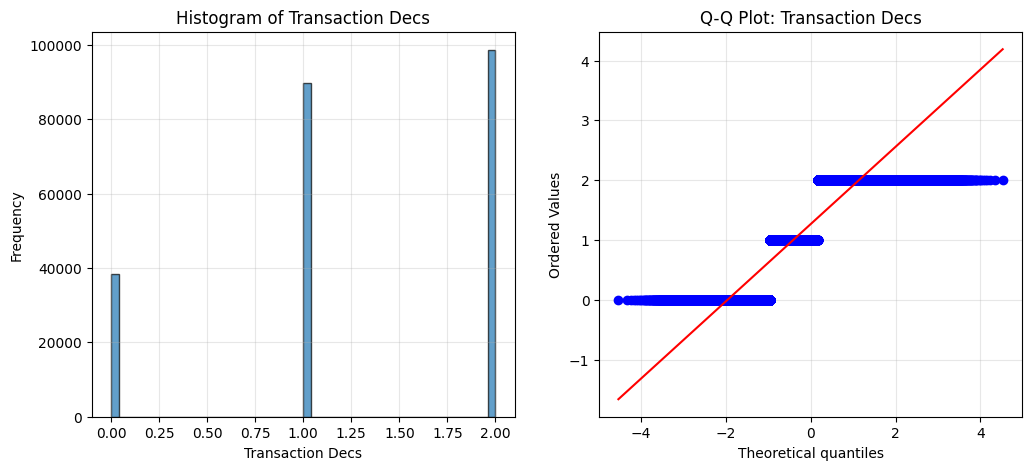

In [165]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Transaction Decs"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Transaction Decs")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Transaction Decs")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Transaction Decs")
ax2.grid(True, alpha=0.3)

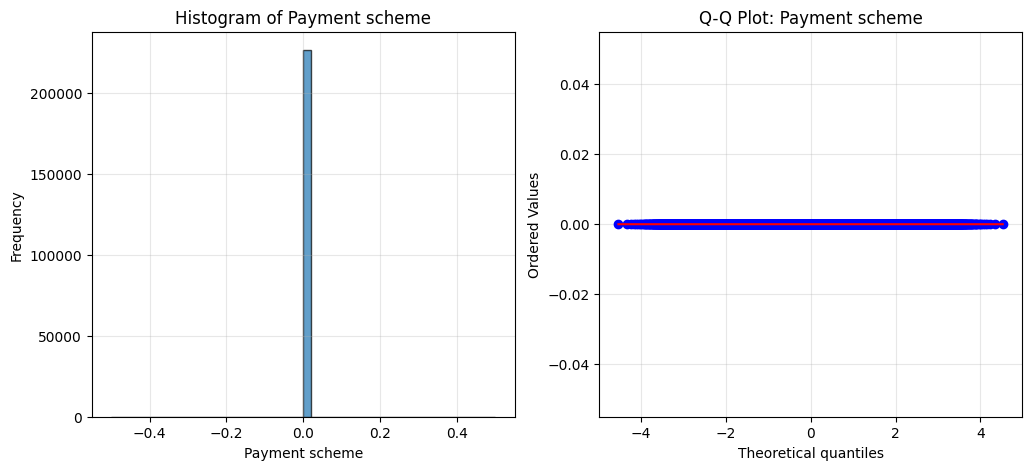

In [166]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Payment scheme"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Payment scheme")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Payment scheme")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Payment scheme")
ax2.grid(True, alpha=0.3)

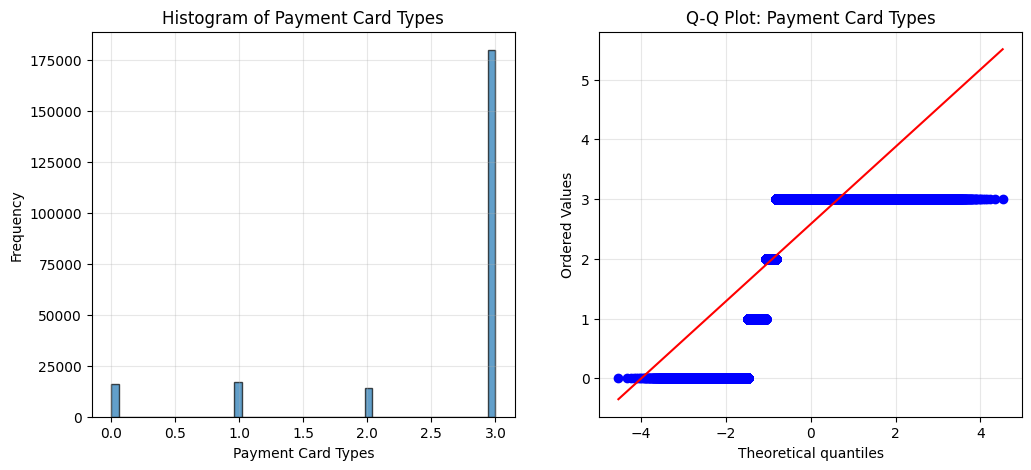

In [167]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Payment Card Types"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Payment Card Types")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Payment Card Types")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Payment Card Types")
ax2.grid(True, alpha=0.3)

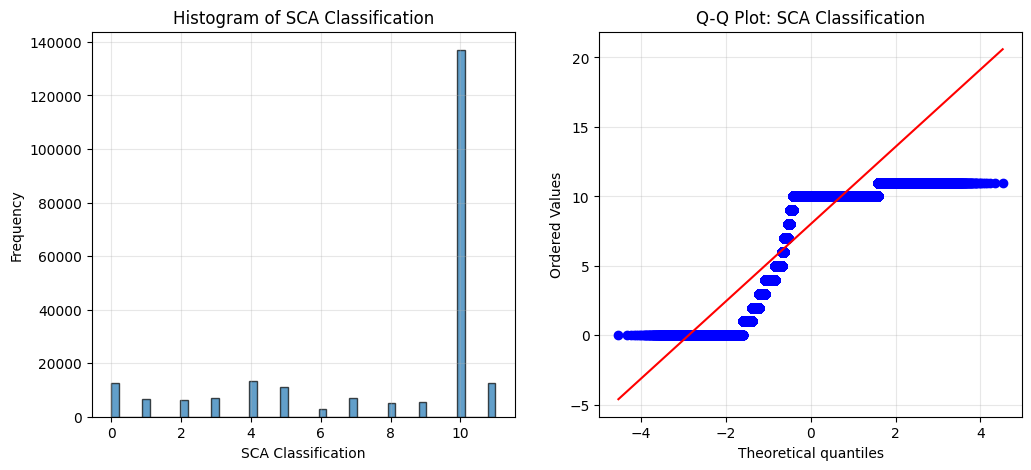

In [168]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["SCA Classification"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("SCA Classification")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of SCA Classification")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: SCA Classification")
ax2.grid(True, alpha=0.3)

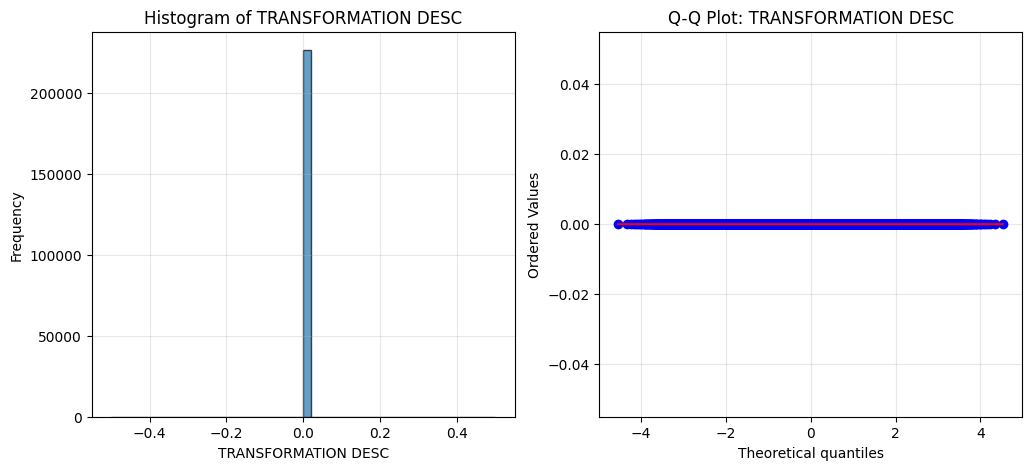

In [169]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["TRANSFORMATION DESC"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("TRANSFORMATION DESC")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of TRANSFORMATION DESC")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: TRANSFORMATION DESC")
ax2.grid(True, alpha=0.3)

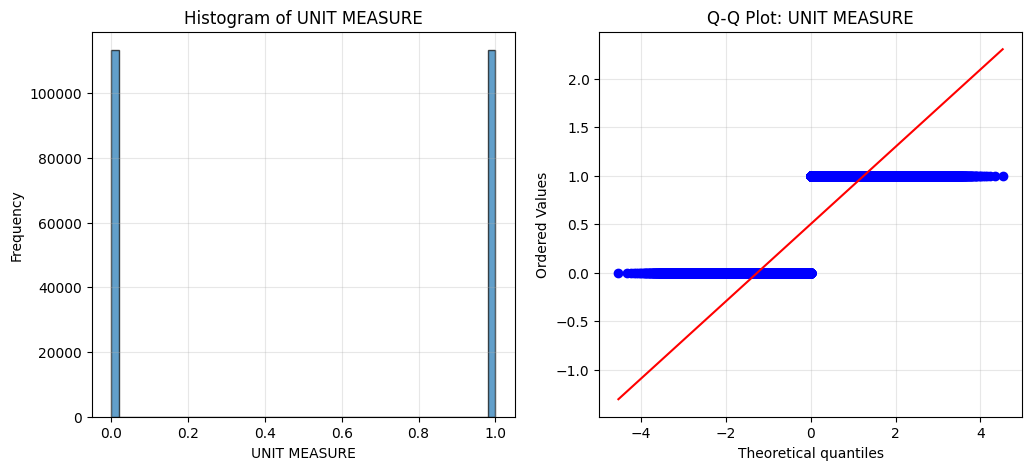

In [170]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["UNIT MEASURE"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("UNIT MEASURE")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of UNIT MEASURE")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: UNIT MEASURE")
ax2.grid(True, alpha=0.3)

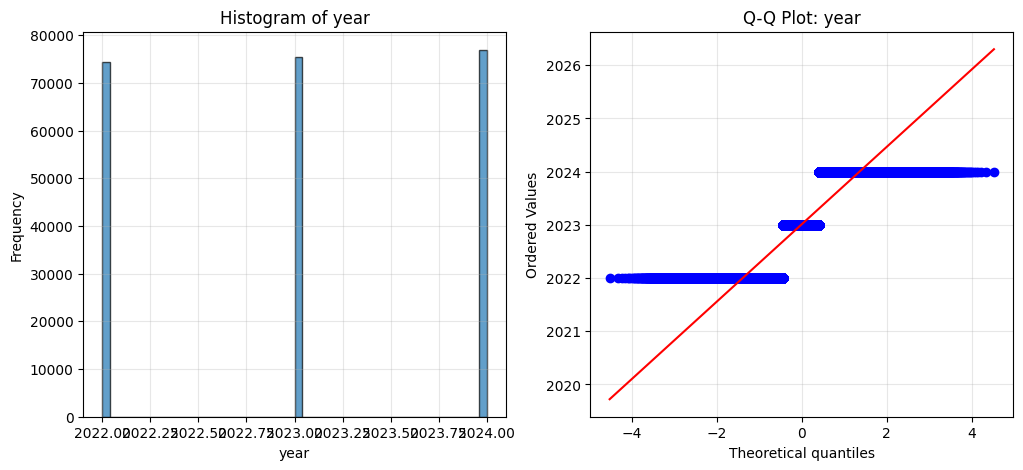

In [171]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["year"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("year")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of year")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: year")
ax2.grid(True, alpha=0.3)

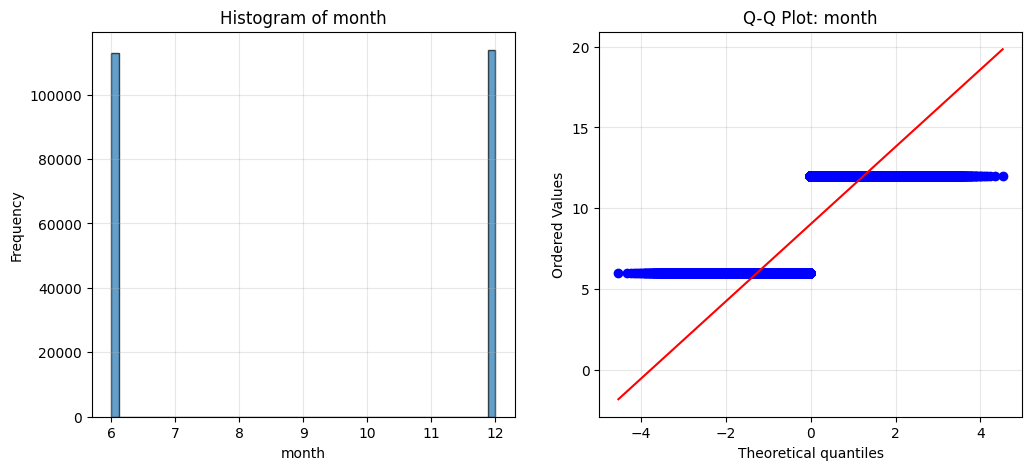

In [172]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["month"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("month")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of month")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: month")
ax2.grid(True, alpha=0.3)

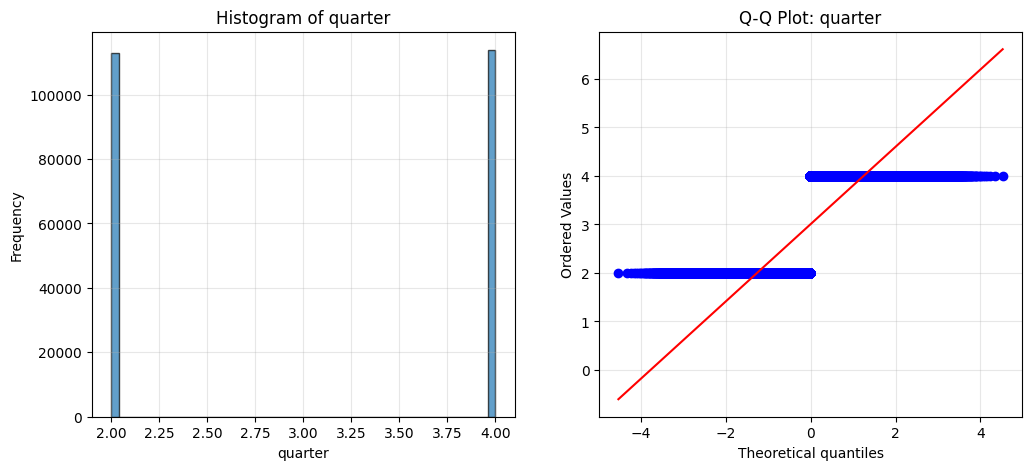

In [173]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["quarter"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("quarter")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of quarter")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: quarter")
ax2.grid(True, alpha=0.3)

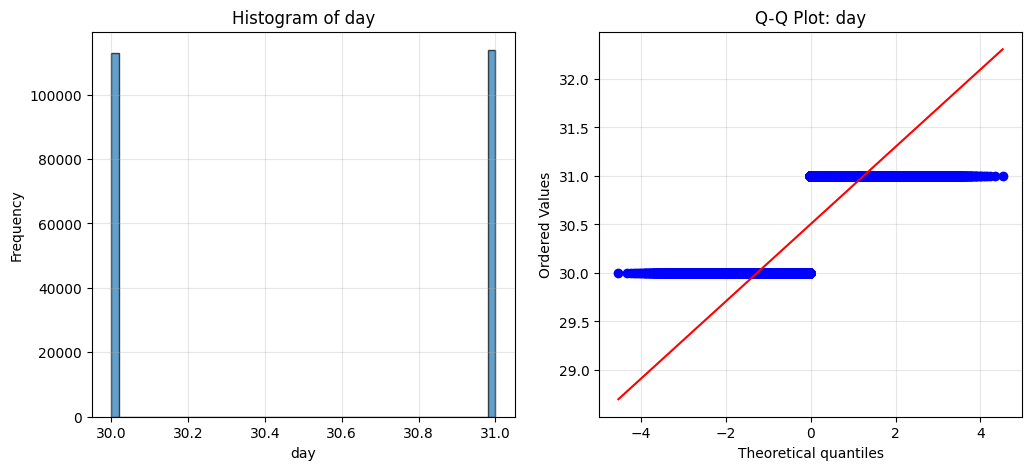

In [174]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["day"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("day")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of day")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: day")
ax2.grid(True, alpha=0.3)

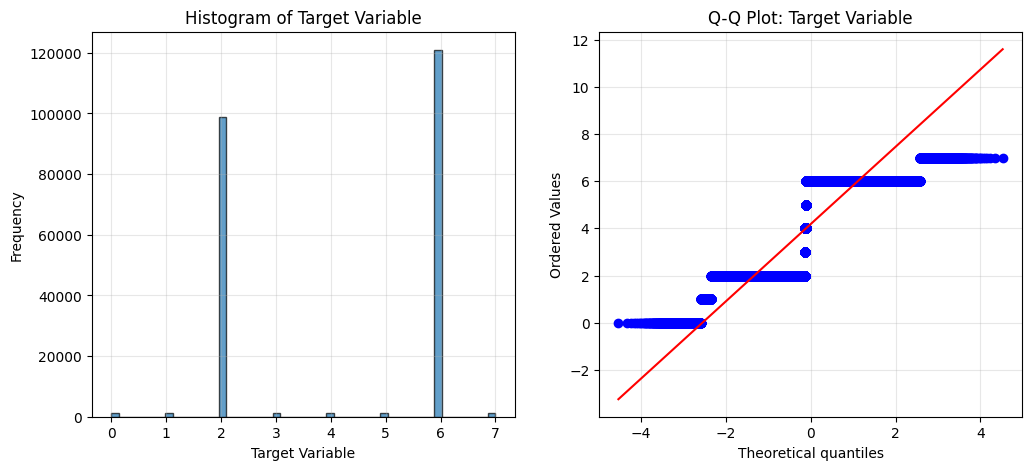

In [175]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
prices = df_final["Target Variable"]   
# Plot 1: Histogram
ax1.hist(prices, bins=50, edgecolor="black", alpha=0.7)
ax1.set_xlabel("Target Variable")
ax1.set_ylabel("Frequency")
ax1.set_title("Histogram of Target Variable")
ax1.grid(True, alpha=0.3)
    
# Plot 2: Q-Q Plot
stats.probplot(prices, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot: Target Variable")
ax2.grid(True, alpha=0.3)

### Confidence Intervals and Inferential Statistics

In [176]:
# Shapiro-Wilk Test
stat, p = shapiro(df_final["CONFIDENTIALITY FLAG"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["UNITS"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Country origin"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Geographic Area"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Country"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Transaction Type"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Transaction Decs"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Payment scheme"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Payment Card Types"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["SCA Classification"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["TRANSFORMATION DESC"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["UNIT MEASURE"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["year"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["month"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["quarter"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["day"])
print("Statistics=%.3f, p=%.3f" % (stat, p))
stat, p = shapiro(df_final["Target Variable"])
print("Statistics=%.3f, p=%.3f" % (stat, p))

Statistics=0.624, p=0.000
Statistics=1.000, p=1.000
Statistics=1.000, p=1.000
Statistics=0.889, p=0.000
Statistics=0.951, p=0.000
Statistics=0.349, p=0.000
Statistics=0.349, p=0.000
Statistics=0.782, p=0.000
Statistics=1.000, p=1.000
Statistics=0.515, p=0.000
Statistics=0.698, p=0.000
Statistics=1.000, p=1.000
Statistics=0.637, p=0.000
Statistics=0.793, p=0.000
Statistics=0.637, p=0.000
Statistics=0.637, p=0.000
Statistics=0.637, p=0.000
Statistics=0.668, p=0.000


C:\Users\kramo\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 226678.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\kramo\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


In [177]:
print("CONFIDENTIALITY FLAG")
print("-" * 40)
data = df_final["CONFIDENTIALITY FLAG"]

sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)

print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")

alpha = 0.05
mu_0 = 0.82 

t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)

print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

CONFIDENTIALITY FLAG
----------------------------------------
Sample Mean: 0.40685
Sample Standard Deviation: 0.49125
T-statistic: -400.41631
P-value: 1.00000
Fail to reject the null hypothesis


In [178]:
print("UNITS")
print("-" * 40)
data = df_final["UNITS"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

UNITS
----------------------------------------
Sample Mean: 0.00000
Sample Standard Deviation: 0.00000
T-statistic: -inf
P-value: 1.00000
Fail to reject the null hypothesis


C:\Users\kramo\AppData\Local\Temp\ipykernel_13896\2135954443.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))


In [179]:
print("Geographic Area")
print("-" * 40)
data = df_final["Geographic Area"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Geographic Area
----------------------------------------
Sample Mean: 2.26235
Sample Standard Deviation: 1.36279
T-statistic: 503.89904
P-value: 0.00000
Reject the null hypothesis


In [180]:
print("Country origin")
print("-" * 40)
data = df_final["Country origin"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Country origin
----------------------------------------
Sample Mean: 0.00000
Sample Standard Deviation: 0.00000
T-statistic: -inf
P-value: 1.00000
Fail to reject the null hypothesis


C:\Users\kramo\AppData\Local\Temp\ipykernel_13896\4276903683.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))


In [181]:
print("Transaction Type")
print("-" * 40)
data = df_final["Transaction Type"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Transaction Type
----------------------------------------
Sample Mean: 0.27100
Sample Standard Deviation: 0.82516
T-statistic: -316.76502
P-value: 1.00000
Fail to reject the null hypothesis


In [182]:
print("Transaction")
print("-" * 40)
data = df_final["Transaction"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Transaction
----------------------------------------
Sample Mean: -0.00000
Sample Standard Deviation: 1.00000
T-statistic: -390.40699
P-value: 1.00000
Fail to reject the null hypothesis


In [183]:
print("Transaction Channels")
print("-" * 40)
data = df_final["Transaction Channels"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Transaction Channels
----------------------------------------
Sample Mean: 3.00941
Sample Standard Deviation: 1.25076
T-statistic: 833.40954
P-value: 0.00000
Reject the null hypothesis


In [184]:
print("Transaction Decs")
print("-" * 40)
data = df_final["Transaction Decs"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Transaction Decs
----------------------------------------
Sample Mean: 1.26506
Sample Standard Deviation: 0.73097
T-statistic: 289.88509
P-value: 0.00000
Reject the null hypothesis


In [185]:
print("Payment scheme")
print("-" * 40)
data = df_final["Payment scheme"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Payment scheme
----------------------------------------
Sample Mean: 0.00000
Sample Standard Deviation: 0.00000
T-statistic: -inf
P-value: 1.00000
Fail to reject the null hypothesis


C:\Users\kramo\AppData\Local\Temp\ipykernel_13896\2285003697.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))


In [186]:
print("Payment Card Types")
print("-" * 40)
data = df_final["Payment Card Types"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Payment Card Types
----------------------------------------
Sample Mean: 2.57848
Sample Standard Deviation: 0.90270
T-statistic: 927.46133
P-value: 0.00000
Reject the null hypothesis


In [187]:
print("SCA Classification")
print("-" * 40)
data = df_final["SCA Classification"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

SCA Classification
----------------------------------------
Sample Mean: 7.99788
Sample Standard Deviation: 3.33215
T-statistic: 1025.59771
P-value: 0.00000
Reject the null hypothesis


In [188]:
print("TRANSFORMATION DESC")
print("-" * 40)
data = df_final["TRANSFORMATION DESC"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

TRANSFORMATION DESC
----------------------------------------
Sample Mean: 0.00000
Sample Standard Deviation: 0.00000
T-statistic: -inf
P-value: 1.00000
Fail to reject the null hypothesis


C:\Users\kramo\AppData\Local\Temp\ipykernel_13896\2957513692.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))


In [189]:
print("UNIT MEASURE")
print("-" * 40)
data = df_final["UNIT MEASURE"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

UNIT MEASURE
----------------------------------------
Sample Mean: 0.50000
Sample Standard Deviation: 0.50000
T-statistic: -304.70789
P-value: 1.00000
Fail to reject the null hypothesis


In [190]:
print("year")
print("-" * 40)
data = df_final["year"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

year
----------------------------------------
Sample Mean: 2023.01129
Sample Standard Deviation: 0.81680
T-statistic: 1178718.53138
P-value: 0.00000
Reject the null hypothesis


In [191]:
print("month")
print("-" * 40)
data = df_final["month"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

month
----------------------------------------
Sample Mean: 9.01263
Sample Standard Deviation: 2.99998
T-statistic: 1300.19784
P-value: 0.00000
Reject the null hypothesis


In [192]:
print("quarter")
print("-" * 40)
data = df_final["quarter"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

quarter
----------------------------------------
Sample Mean: 3.00421
Sample Standard Deviation: 0.99999
T-statistic: 1039.92421
P-value: 0.00000
Reject the null hypothesis


In [193]:
print("day")
print("-" * 40)
data = df_final["day"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

day
----------------------------------------
Sample Mean: 30.50210
Sample Standard Deviation: 0.50000
T-statistic: 28263.91100
P-value: 0.00000
Reject the null hypothesis


In [194]:
print("Target Variable")
print("-" * 40)
data = df_final["Target Variable"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Target Variable
----------------------------------------
Sample Mean: 4.17435
Sample Standard Deviation: 2.00677
T-statistic: 795.82079
P-value: 0.00000
Reject the null hypothesis


In [195]:
print("Country")
print("-" * 40)
data = df_final["Country"]
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)  
n = len(data)
print(f"Sample Mean: {sample_mean:.5f}")
print(f"Sample Standard Deviation: {sample_std:.5f}")
alpha = 0.05
mu_0 = 0.82 
t_statistic = (sample_mean - mu_0) / (sample_std / np.sqrt(n))
p_value = 1 - stats.t.cdf(t_statistic, df=n-1)
print(f"T-statistic: {t_statistic:.5f}")
print(f"P-value: {p_value:.5f}")
if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Country
----------------------------------------
Sample Mean: 14.96200
Sample Standard Deviation: 8.97561
T-statistic: 750.15607
P-value: 0.00000
Reject the null hypothesis


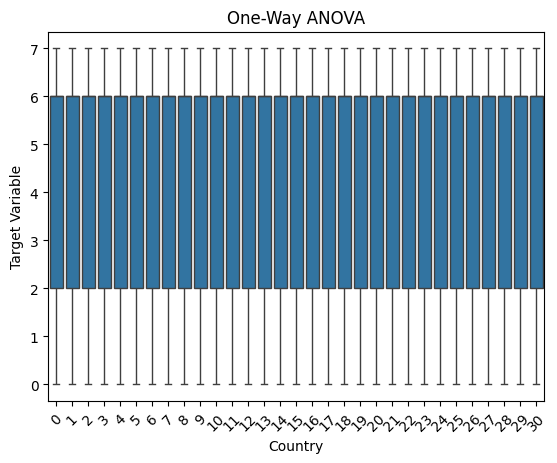

ANOVA Table:
                   sum_sq        df         F        PR(>F)
C(Country)     818.421449      30.0  6.779403  1.191238e-27
Residual    912040.797425  226647.0       NaN           NaN

P-value: 0.000000
SIGNIFICANT: Fraud probability differs across countries

Mean Mean Fraud Rate by Country:
             mean       std  count
Country                           
13       4.282346  1.996128   6786
15       4.276905  1.996986   6746
28       4.266438  1.997832   6996
17       4.256506  2.000435   6456
29       4.256360  1.998479   7076
9        4.241683  2.000893   7034
12       4.233343  2.001094   7174
14       4.230148  2.001943   7178
23       4.214146  2.003769   7154
21       4.203562  2.004089   7300
7        4.202510  2.004944   7170
20       4.197937  2.005392   7174
4        4.188097  2.005549   7326
6        4.185104  2.006348   7304
18       4.184117  2.006492   7278
0        4.183302  2.006413   7354
2        4.176683  2.006862   7188
26       4.173673  2.007518   723

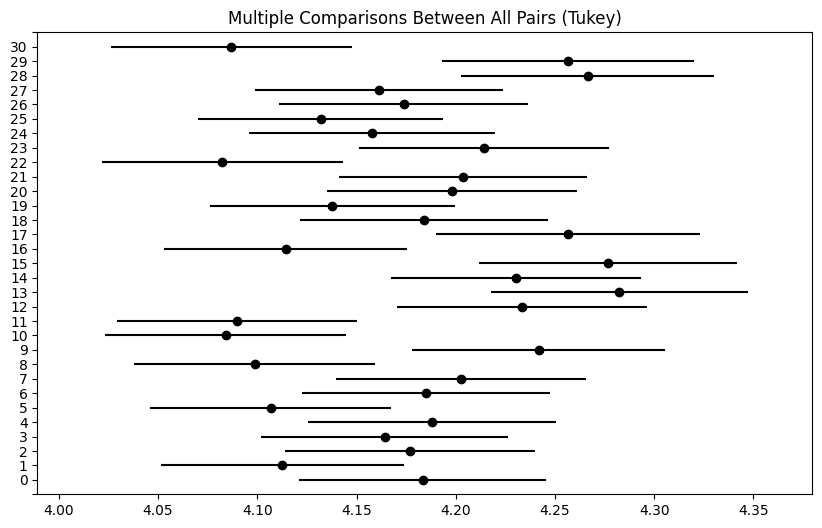

In [196]:
Country_counts = df_final["Country"].value_counts()
valid_counties = Country_counts[Country_counts >= 10].index
df_country_filtered = df_final[df_final["Country"].isin(valid_counties)]

sns.boxplot(x="Country", y="Target Variable", data=df_country_filtered)
plt.title("One-Way ANOVA")
plt.xlabel("Country")
plt.ylabel("Target Variable")
plt.xticks(rotation=45)
plt.show()

model1 = ols('Q("Target Variable") ~ C(Country)', data=df_country_filtered).fit()
anova_table1 = sm.stats.anova_lm(model1, typ=2)
print("ANOVA Table:")
print(anova_table1)

p_value1 = anova_table1.loc["C(Country)", "PR(>F)"]
print(f"\nP-value: {p_value1:.6f}")

if p_value1 < 0.05:
    print("SIGNIFICANT: Fraud probability differs across countries")
    
    print("\nMean Mean Fraud Rate by Country:")
    means1 = df_country_filtered.groupby("Country")["Target Variable"].agg(["mean", "std", "count"])
    print(means1.sort_values("mean", ascending=False))
    
    print("\nPost-hoc Tukey HSD Test:")
    tukey = pairwise_tukeyhsd(
        endog=df_country_filtered["Target Variable"],
        groups=df_country_filtered["Country"],
        alpha=0.05
    )
    print(tukey.summary())
else:
    print("NOT SIGNIFICANT: No significant difference in fraud probability across countries")

tukey.plot_simultaneous()
plt.show()


ANOVA: TRANSACTION TYPE vs TARGET VARIABLE


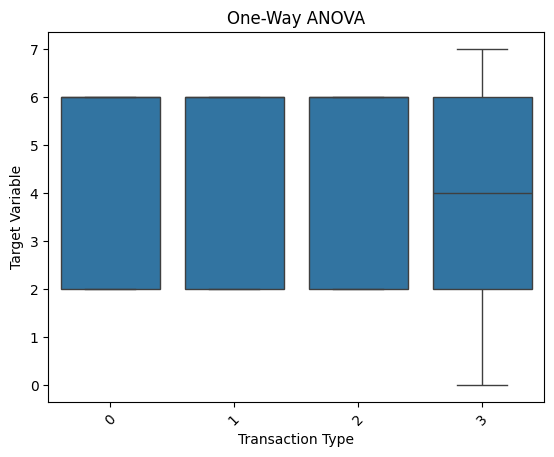

ANOVA Table:
                            sum_sq        df          F        PR(>F)
C(Transaction_Type)    1393.222664       3.0  115.49429  9.825246e-75
Residual             911465.996211  226674.0        NaN           NaN

P-value: 0.000000
SIGNIFICANT: Fraud probability differs across Transaction Type

Mean Fraud Rate by Transaction Type:
                      mean       std   count
Transaction Type                            
2                 4.228640  1.987187    3324
1                 4.227300  1.987340    3326
0                 4.195706  1.990407  202876
3                 3.901003  2.179592   17152

Post-hoc Tukey HSD Test:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   0.0316 0.8041 -0.0585  0.1216  False
     0      2   0.0329 0.7837 -0.0571   0.123  False
     0      3  -0.2947    0.0 -0.3357 -0.2537   True
     1      2   0.0013    1.0  -0.125  0.12

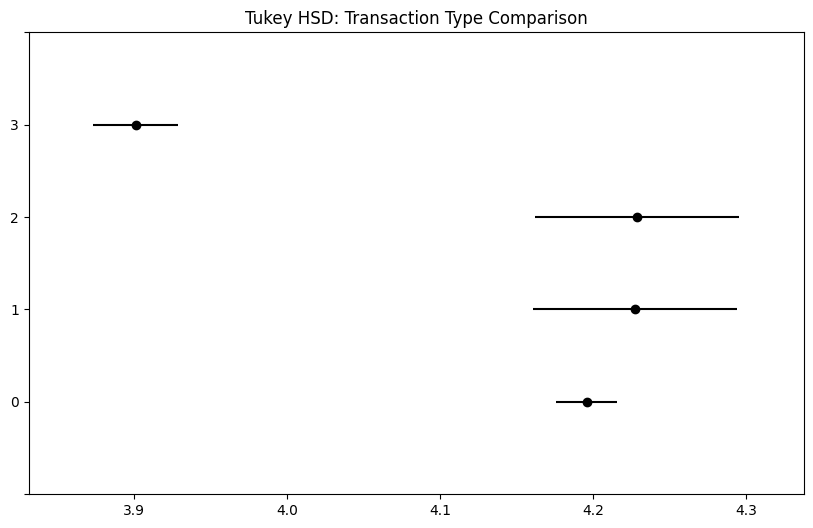

In [197]:
print("ANOVA: TRANSACTION TYPE vs TARGET VARIABLE")
print("=" * 60)

type_counts = df_final["Transaction Type"].value_counts()
valid_types = type_counts[type_counts >= 10].index
df_type_filtered = df_final[df_final["Transaction Type"].isin(valid_types)]

sns.boxplot(x="Transaction Type", y="Target Variable", data=df_type_filtered)
plt.title("One-Way ANOVA")
plt.xlabel("Transaction Type")
plt.ylabel("Target Variable")
plt.xticks(rotation=45)
plt.show()

model5 = ols('Q("Target Variable") ~ C(Transaction_Type)', data=df_type_filtered.rename(columns={"Transaction Type": "Transaction_Type"})).fit()
anova_table5 = sm.stats.anova_lm(model5, typ=2)
print("ANOVA Table:")
print(anova_table5)

p_value5 = anova_table5.loc["C(Transaction_Type)", "PR(>F)"]
print(f"\nP-value: {p_value5:.6f}")

if p_value5 < 0.05:
    print("SIGNIFICANT: Fraud probability differs across Transaction Type")
    
    print("\nMean Fraud Rate by Transaction Type:")
    means5 = df_type_filtered.groupby("Transaction Type")["Target Variable"].agg(["mean", "std", "count"])
    print(means5.sort_values("mean", ascending=False))
    
    print("\nPost-hoc Tukey HSD Test:")
    tukey = pairwise_tukeyhsd(
        endog=df_type_filtered["Target Variable"],
        groups=df_type_filtered["Transaction Type"],
        alpha=0.05
    )
    print(tukey.summary())
    
    tukey.plot_simultaneous()
    plt.title("Tukey HSD: Transaction Type Comparison")
    plt.show()
else:
    print("NOT SIGNIFICANT: No significant difference in fraud probability across Transaction Type")

ANOVA: CONFIDENTIALITY FLAG vs TARGET VARIABLE


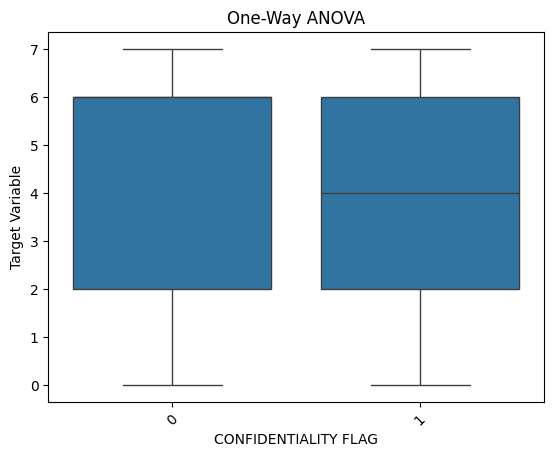

ANOVA Table:
                                sum_sq        df            F  PR(>F)
C(CONFIDENTIALITY_FLAG)    7414.648814       1.0  1856.240559     0.0
Residual                 905444.570060  226676.0          NaN     NaN

P-value: 0.000000
SIGNIFICANT: Fraud probability differs across CONFIDENTIALITY FLAG

Mean Fraud Rate by CONFIDENTIALITY FLAG:
                          mean       std   count
CONFIDENTIALITY FLAG                            
0                     4.324141  1.970111  134454
1                     3.955977  2.039447   92224

Post-hoc Tukey HSD Test:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     0      1  -0.3682   0.0 -0.3849 -0.3514   True
---------------------------------------------------


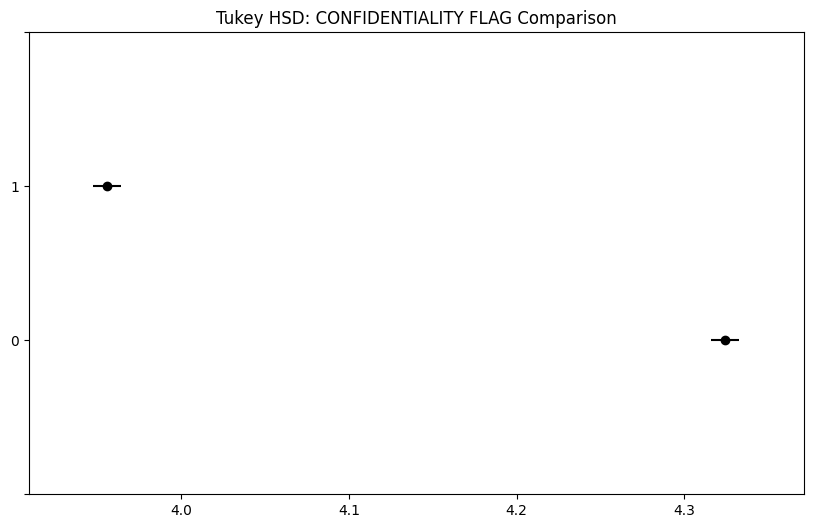

In [198]:
print("ANOVA: CONFIDENTIALITY FLAG vs TARGET VARIABLE")
print("=" * 60)

flag_counts = df_final["CONFIDENTIALITY FLAG"].value_counts()
valid_flags = flag_counts[flag_counts >= 10].index
df_flag_filtered = df_final[df_final["CONFIDENTIALITY FLAG"].isin(valid_flags)]

sns.boxplot(x="CONFIDENTIALITY FLAG", y="Target Variable", data=df_flag_filtered)
plt.title("One-Way ANOVA")
plt.xlabel("CONFIDENTIALITY FLAG")
plt.ylabel("Target Variable")
plt.xticks(rotation=45)
plt.show()

model8 = ols('Q("Target Variable") ~ C(CONFIDENTIALITY_FLAG)', data=df_flag_filtered.rename(columns={"CONFIDENTIALITY FLAG": "CONFIDENTIALITY_FLAG"})).fit()
anova_table8 = sm.stats.anova_lm(model8, typ=2)
print("ANOVA Table:")
print(anova_table8)

p_value8 = anova_table8.loc["C(CONFIDENTIALITY_FLAG)", "PR(>F)"]
print(f"\nP-value: {p_value8:.6f}")

if p_value8 < 0.05:
    print("SIGNIFICANT: Fraud probability differs across CONFIDENTIALITY FLAG")
    
    print("\nMean Fraud Rate by CONFIDENTIALITY FLAG:")
    means8 = df_flag_filtered.groupby("CONFIDENTIALITY FLAG")["Target Variable"].agg(["mean", "std", "count"])
    print(means8.sort_values("mean", ascending=False))
    
    print("\nPost-hoc Tukey HSD Test:")
    tukey = pairwise_tukeyhsd(
        endog=df_flag_filtered["Target Variable"],
        groups=df_flag_filtered["CONFIDENTIALITY FLAG"],
        alpha=0.05
    )
    print(tukey.summary())
    
    tukey.plot_simultaneous()
    plt.title("Tukey HSD: CONFIDENTIALITY FLAG Comparison")
    plt.show()
else:
    print("NOT SIGNIFICANT: No significant difference in fraud probability across CONFIDENTIALITY FLAG")

In [199]:
print("LEVENE TEST: TRANSACTION TYPE")
print("=" * 60)

if "Transaction Type" in df_final.columns:
    top_types = df_final["Transaction Type"].value_counts().head(3).index
    print(f"Testing top 3 Transaction Type: {list(top_types)}")
    
    w_levene, p_levene = stats.levene(
        df_final.loc[df_final["Transaction Type"] == top_types[0], "Target Variable"].dropna(),
        df_final.loc[df_final["Transaction Type"] == top_types[1], "Target Variable"].dropna(),
        df_final.loc[df_final["Transaction Type"] == top_types[2], "Target Variable"].dropna()
    )
    print(f"Levene test: W={w_levene:.3f}, p={p_levene:.6f}")
    
    if p_levene > 0.05:
        print("Equal variances (p > 0.05)")
    else:
        print("Unequal variances (p < 0.05)")

LEVENE TEST: TRANSACTION TYPE
Testing top 3 Transaction Type: [0, 3, 1]
Levene test: W=76.214, p=0.000000
Unequal variances (p < 0.05)


#### Correlation Analysis

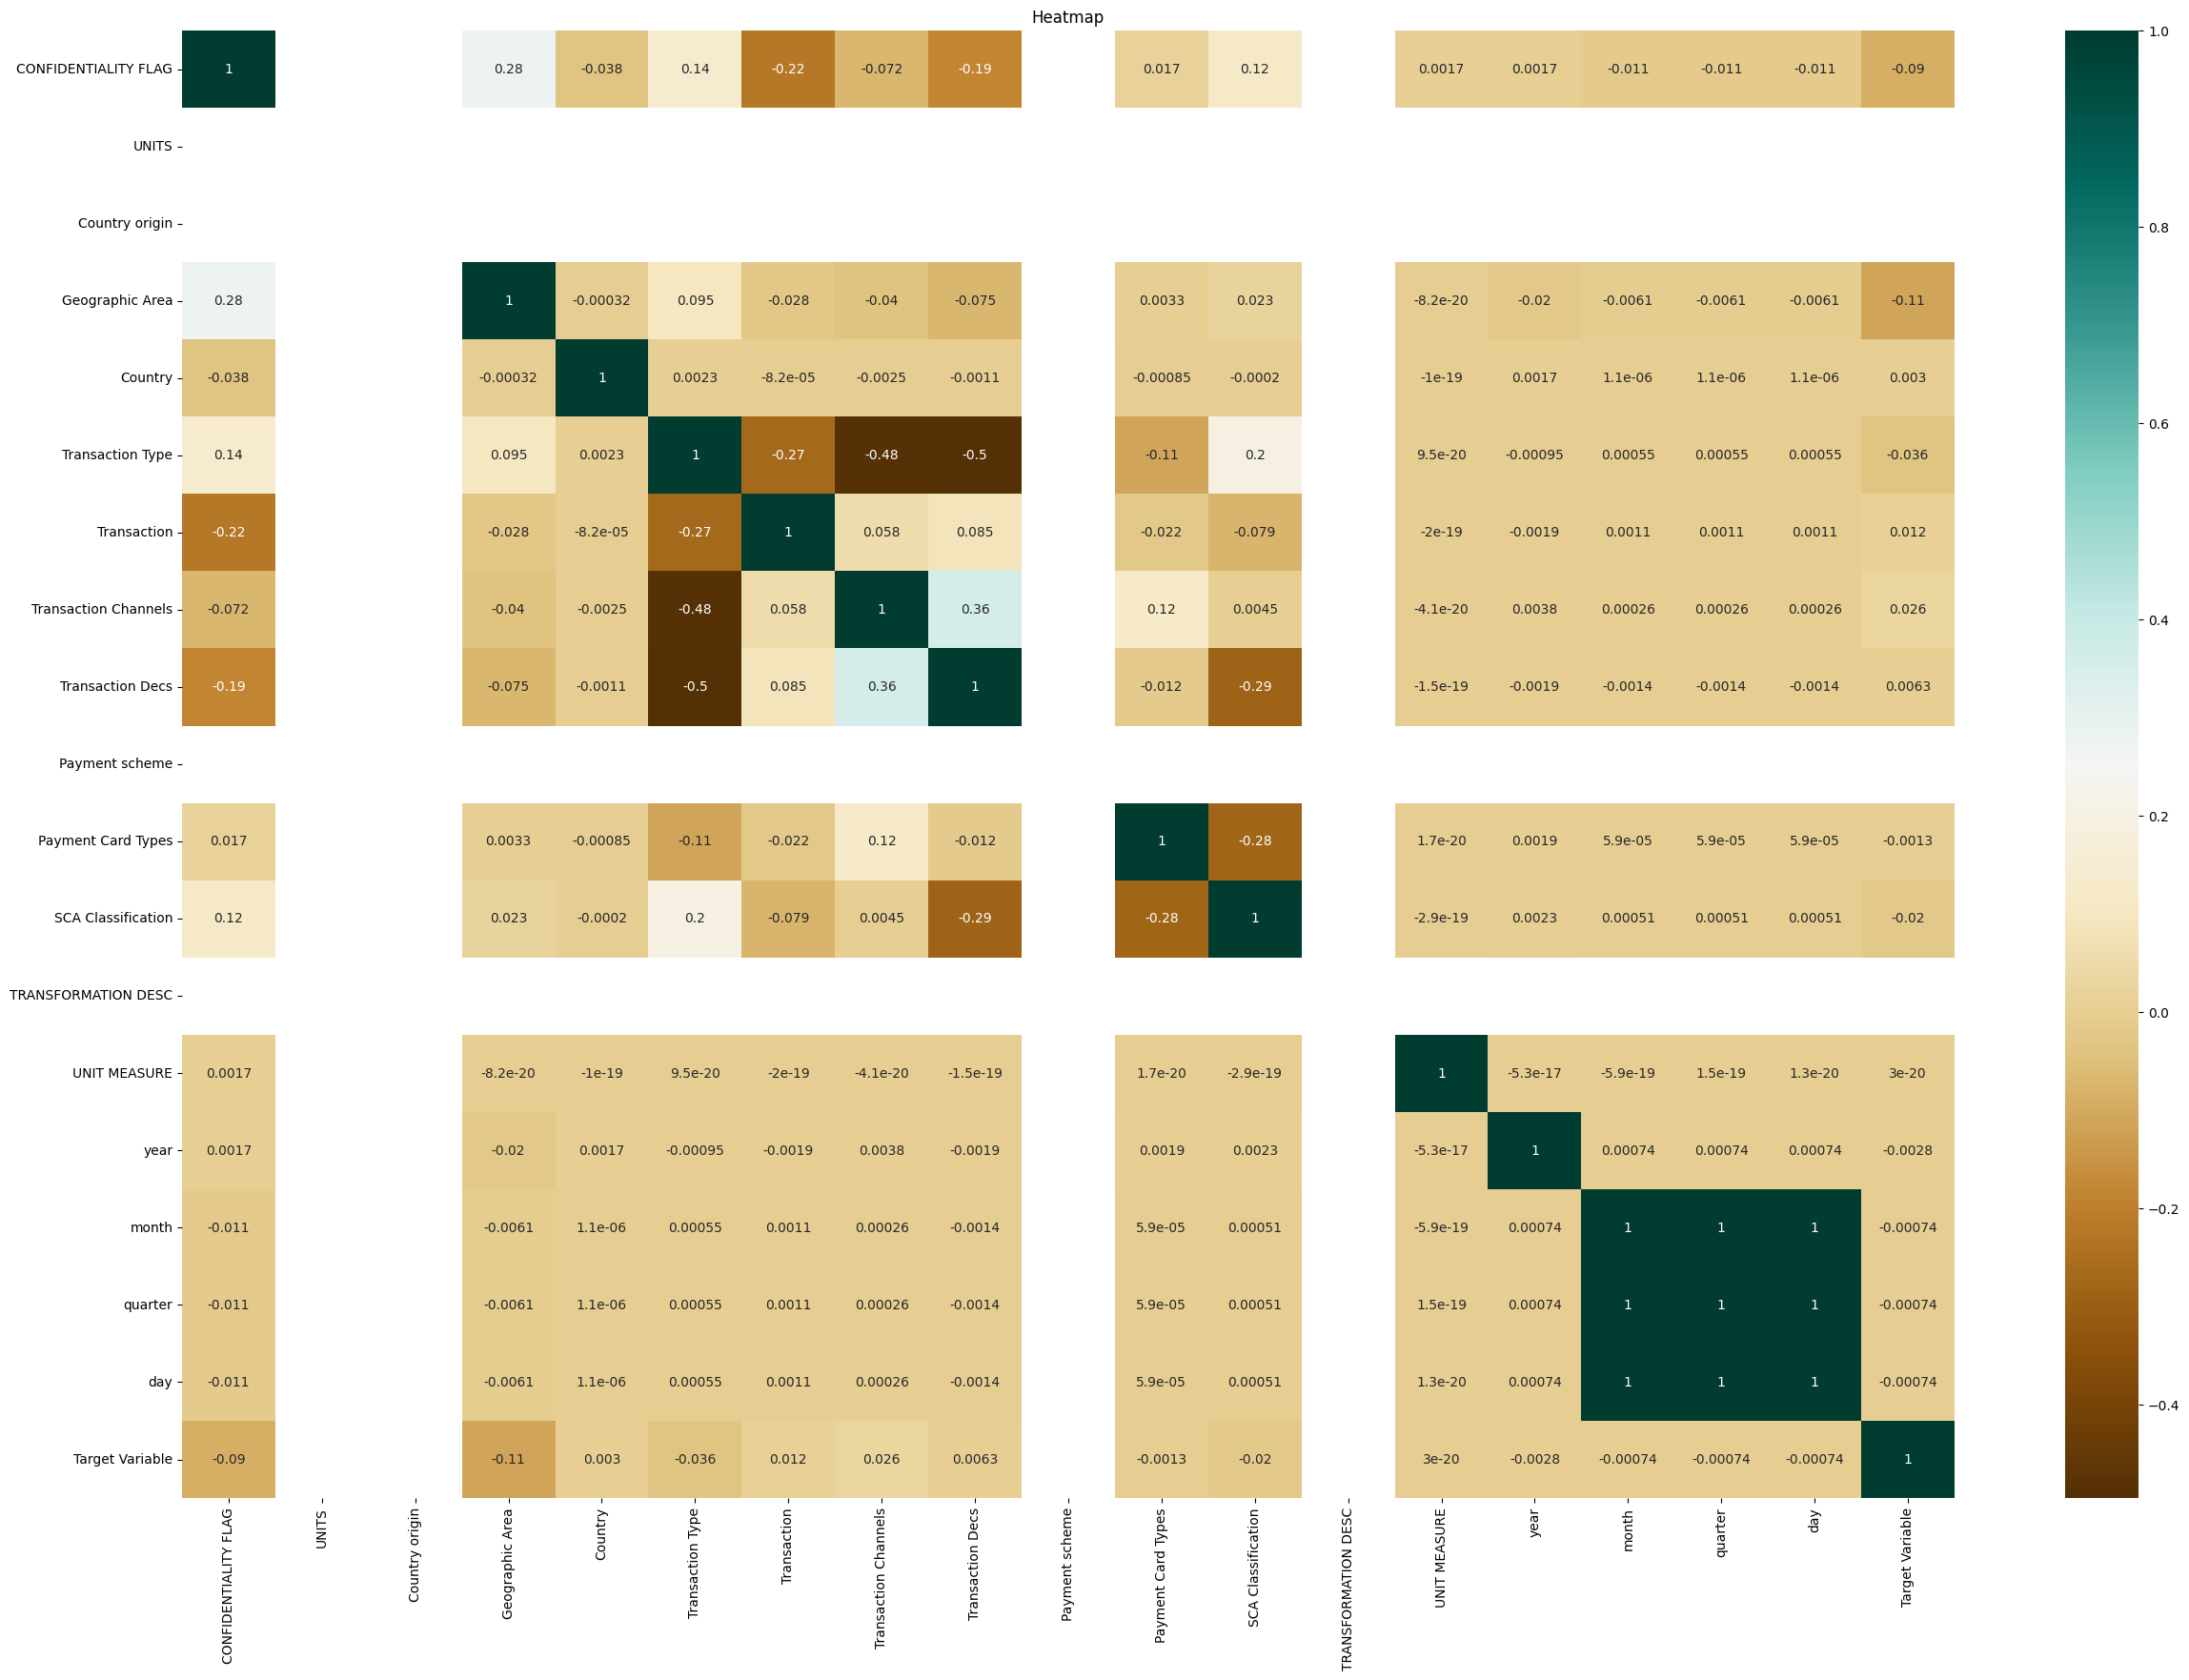

,CONFIDENTIALITY FLAG,UNITS,Country origin,Geographic Area,Country,Transaction Type,Transaction,Transaction Channels,Transaction Decs,Payment scheme,Payment Card Types,SCA Classification,TRANSFORMATION DESC,UNIT MEASURE,year,month,quarter,day,Target Variable
CONFIDENTIALITY FLAG,1.000000,NaN,NaN,2.778747e-01,-3.763417e-02,1.356927e-01,-2.225779e-01,-7.200153e-02,-1.854883e-01,NaN,1.655926e-02,1.157427e-01,NaN,1.706258e-03,1.687252e-03,-1.144223e-02,-1.144223e-02,-1.144223e-02,-9.012461e-02
UNITS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country origin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Geographic Area,0.277875,NaN,NaN,1.000000e+00,-3.174365e-04,9.482821e-02,-2.782358e-02,-4.012613e-02,-7.450051e-02,NaN,3.339088e-03,2.296011e-02,NaN,-8.194192e-20,-1.985403e-02,-6.119142e-03,-6.119142e-03,-6.119142e-03,-1.121892e-01
Country,-0.037634,NaN,NaN,-3.174365e-04,1.000000e+00,2.341138e-03,-8.188966e-05,-2.515336e-03,-1.080377e-03,NaN,-8.510243e-04,-1.976912e-04,NaN,-1.021513e-19,1.728981e-03,1.107367e-06,1.107367e-06,1.107367e-06,3.006651e-03
Transaction Type,0.135693,NaN,NaN,9.482821e-02,2.341138e-03,1.000000e+00,-2.701489e-01,-4.849967e-01,-4.954398e-01,NaN,-1.114494e-01,1.973330e-01,NaN,9.496923e-20,-9.540783e-04,5.531585e-04,5.531585e-04,5.531585e-04,-3.604171e-02
Transaction,-0.222578,NaN,NaN,-2.782358e-02,-8.188966e-05,-2.701489e-01,1.000000e+00,5.763435e-02,8.481243e-02,NaN,-2.223240e-02,-7.894953e-02,NaN,-1.988506e-19,-1.949775e-03,1.052106e-03,1.052106e-03,1.052106e-03,1.221706e-02
Transaction Channels,-0.072002,NaN,NaN,-4.012613e-02,-2.515336e-03,-4.849967e-01,5.763435e-02,1.000000e+00,3.569142e-01,NaN,1.199824e-01,4.522498e-03,NaN,-4.072499e-20,3.816845e-03,2.575468e-04,2.575468e-04,2.575468e-04,2.589285e-02
Transaction Decs,-0.185488,NaN,NaN,-7.450051e-02,-1.080377e-03,-4.954398e-01,8.481243e-02,3.569142e-01,1.000000e+00,NaN,-1.196211e-02,-2.887041e-01,NaN,-1.460689e-19,-1.851357e-03,-1.381288e-03,-1.381288e-03,-1.381288e-03,6.298050e-03
Payment scheme,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [200]:
numeric_df_clean = df_final.select_dtypes(include="number") 
plt.figure(figsize=(30, 20)) 
c = numeric_df_clean.corr()  
sns.heatmap(c, cmap="BrBG", annot=True) 
plt.title("Heatmap")
plt.show() 

c

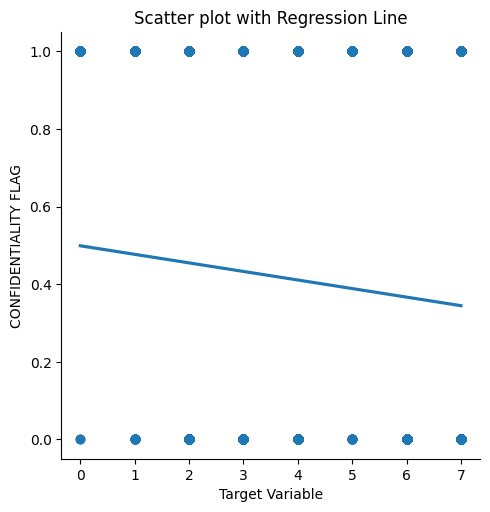

In [201]:
Correlation_df = df_final[["Target Variable", "CONFIDENTIALITY FLAG"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="CONFIDENTIALITY FLAG", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

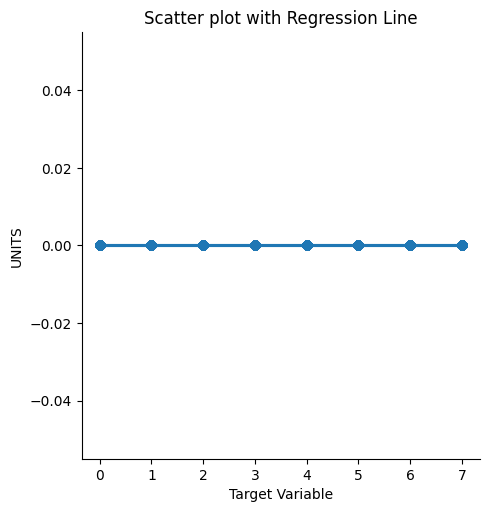

In [202]:
Correlation_df = df_final[["Target Variable", "UNITS"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="UNITS", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

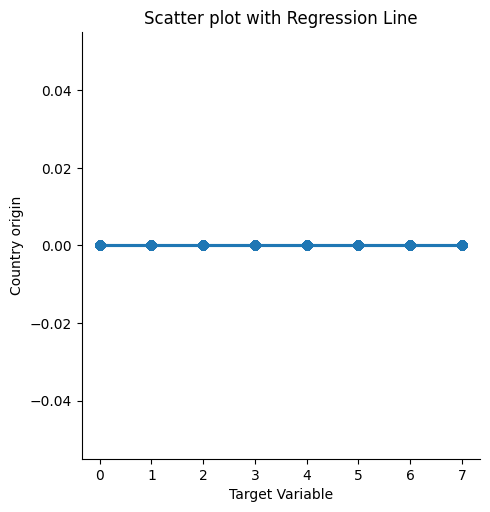

In [203]:
Correlation_df = df_final[["Target Variable", "Country origin"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Country origin", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

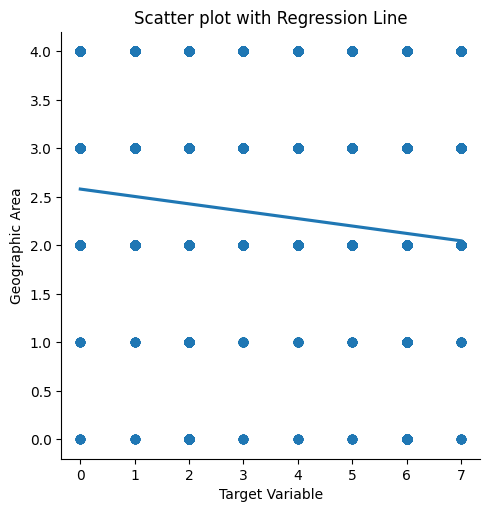

In [204]:
Correlation_df = df_final[["Target Variable", "Geographic Area"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Geographic Area", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

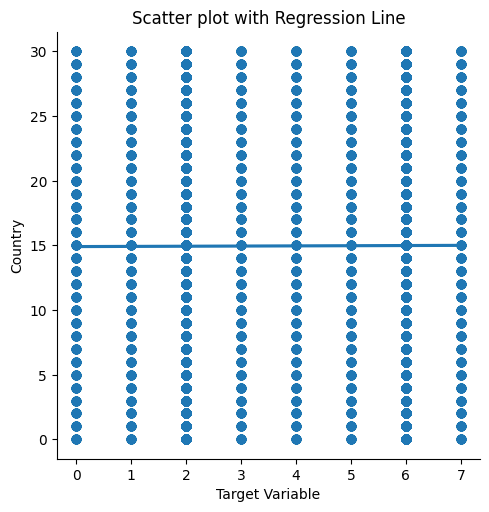

In [205]:
Correlation_df = df_final[["Target Variable", "Country"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Country", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

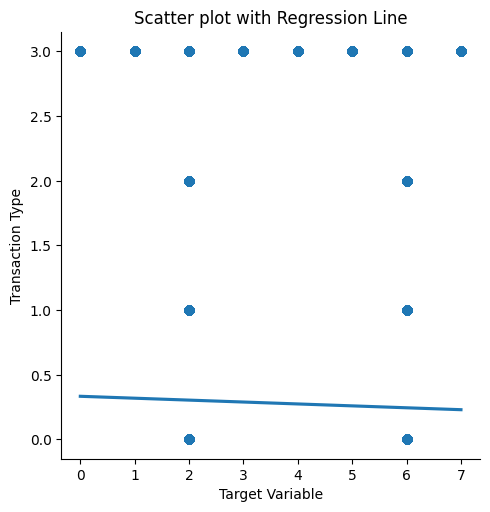

In [206]:
Correlation_df = df_final[["Target Variable", "Transaction Type"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Transaction Type", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

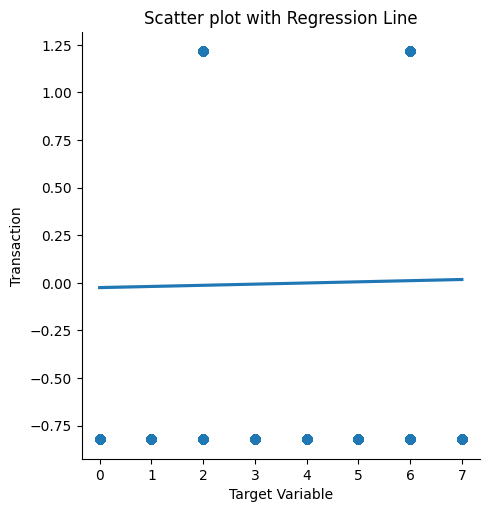

In [207]:
Correlation_df = df_final[["Target Variable", "Transaction"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Transaction", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

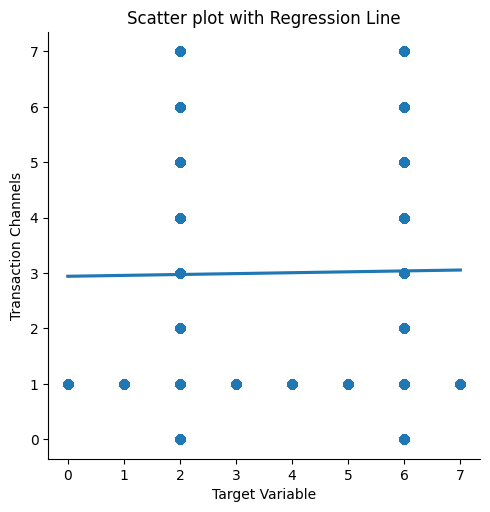

In [208]:
Correlation_df = df_final[["Target Variable", "Transaction Channels"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Transaction Channels", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

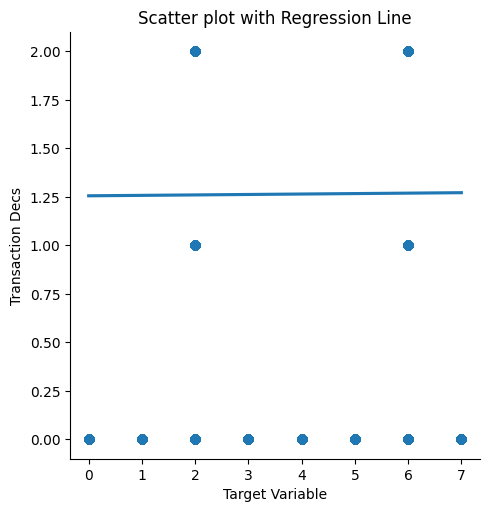

In [209]:
Correlation_df = df_final[["Target Variable", "Transaction Decs"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Transaction Decs", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

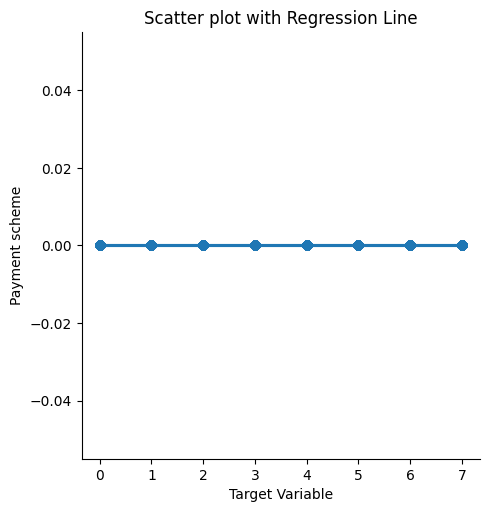

In [210]:
Correlation_df = df_final[["Target Variable", "Payment scheme"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Payment scheme", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

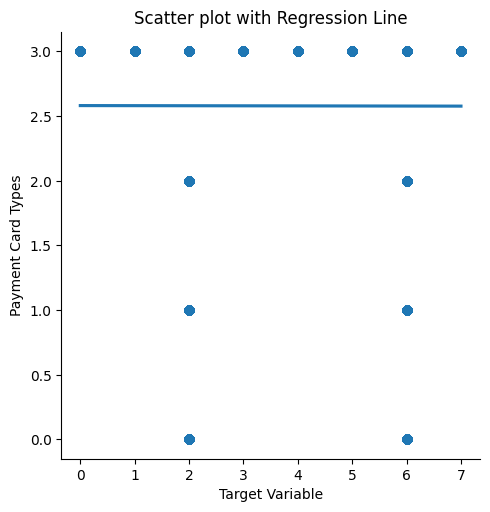

In [211]:
Correlation_df = df_final[["Target Variable", "Payment Card Types"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="Payment Card Types", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

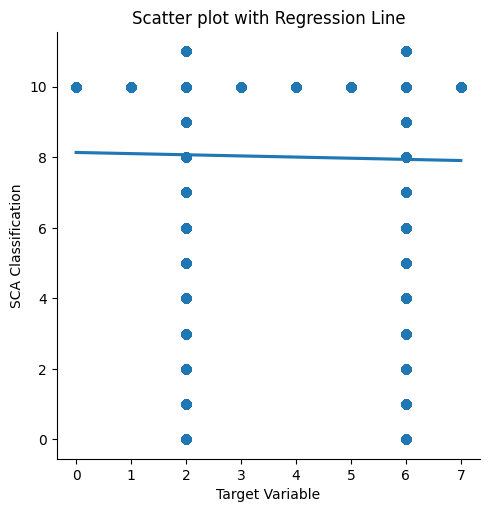

In [212]:
Correlation_df = df_final[["Target Variable", "SCA Classification"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="SCA Classification", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

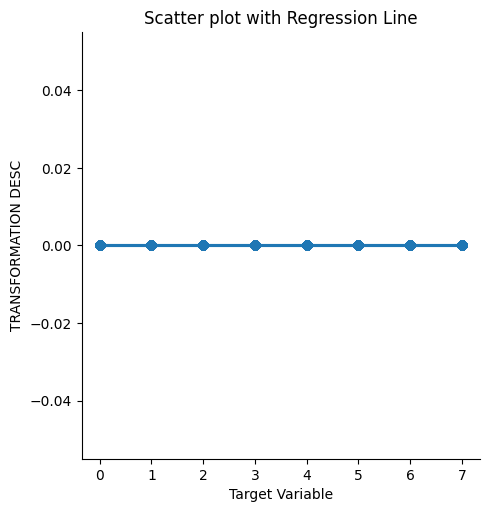

In [213]:
Correlation_df = df_final[["Target Variable", "TRANSFORMATION DESC"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="TRANSFORMATION DESC", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

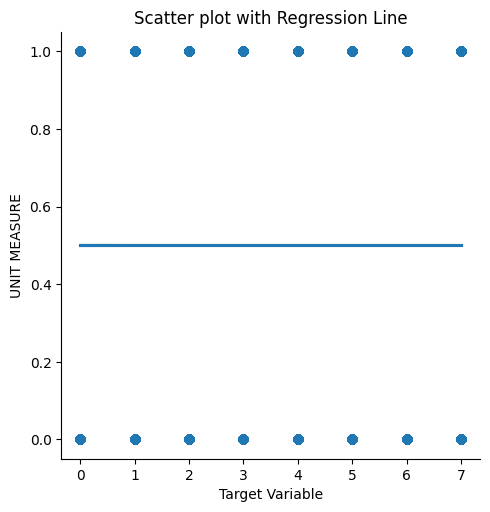

In [214]:
Correlation_df = df_final[["Target Variable", "UNIT MEASURE"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="UNIT MEASURE", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

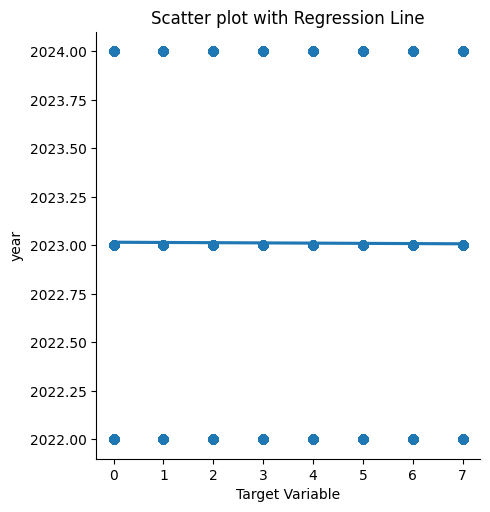

In [215]:
Correlation_df = df_final[["Target Variable", "year"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="year", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

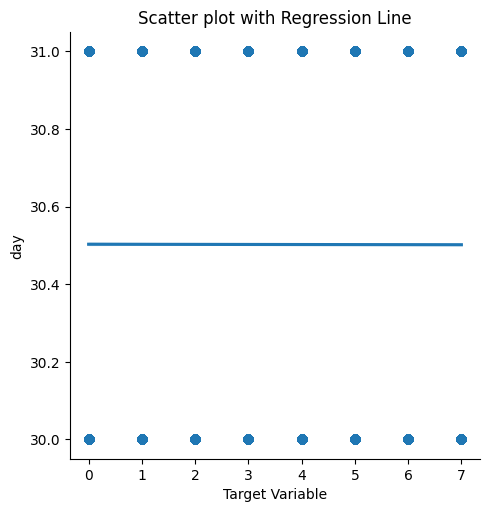

In [216]:
Correlation_df = df_final[["Target Variable", "day"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="day", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

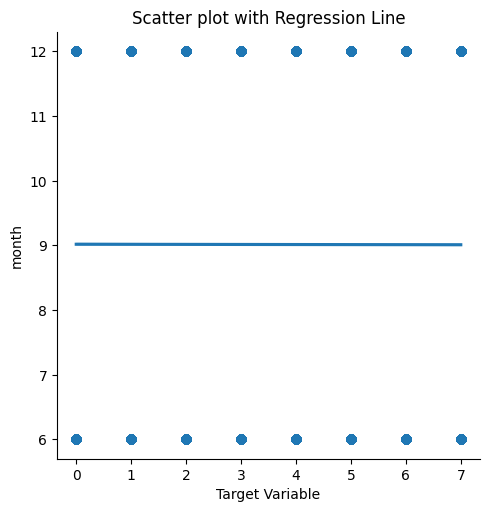

In [217]:
Correlation_df = df_final[["Target Variable", "month"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="month", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

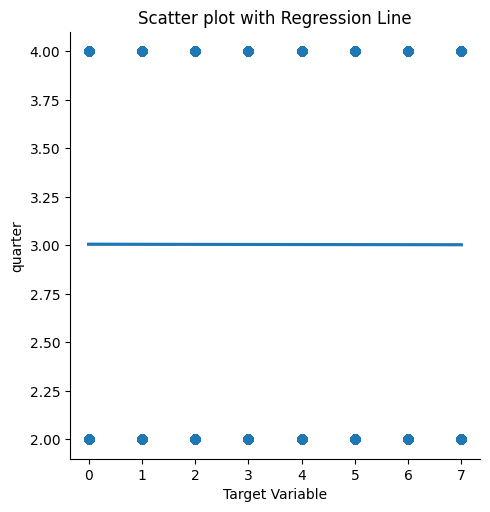

In [218]:
Correlation_df = df_final[["Target Variable", "quarter"]].copy()
cov_matrix = Correlation_df.cov()
pd.set_option("display.float_format", "{:.0f}".format)
cov_matrix
corr_matrix = Correlation_df.corr()
pd.set_option("display.float_format", "{:.5f}".format)
corr_matrix
sns.lmplot(x="Target Variable", y="quarter", data=Correlation_df)
plt.title("Scatter plot with Regression Line")
plt.show()

#### Visualization

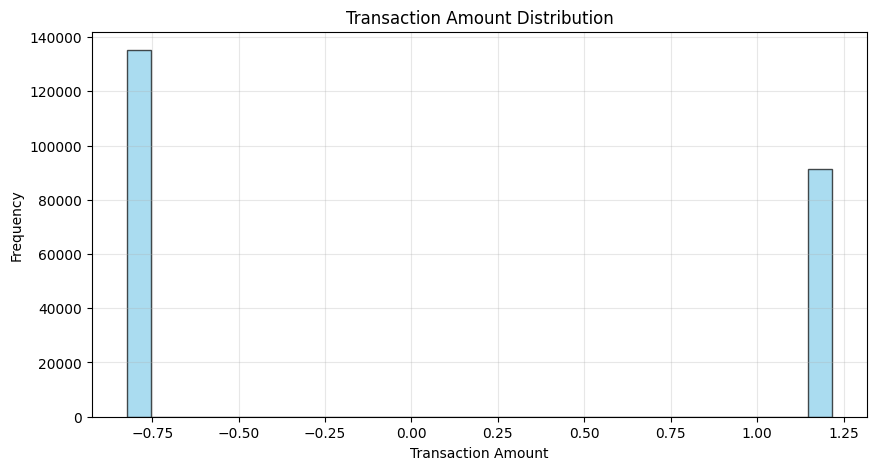

In [219]:
plt.figure(figsize=(10, 5))
plt.hist(df_final["Transaction"], bins=30, color="skyblue", edgecolor="black", alpha=0.7)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

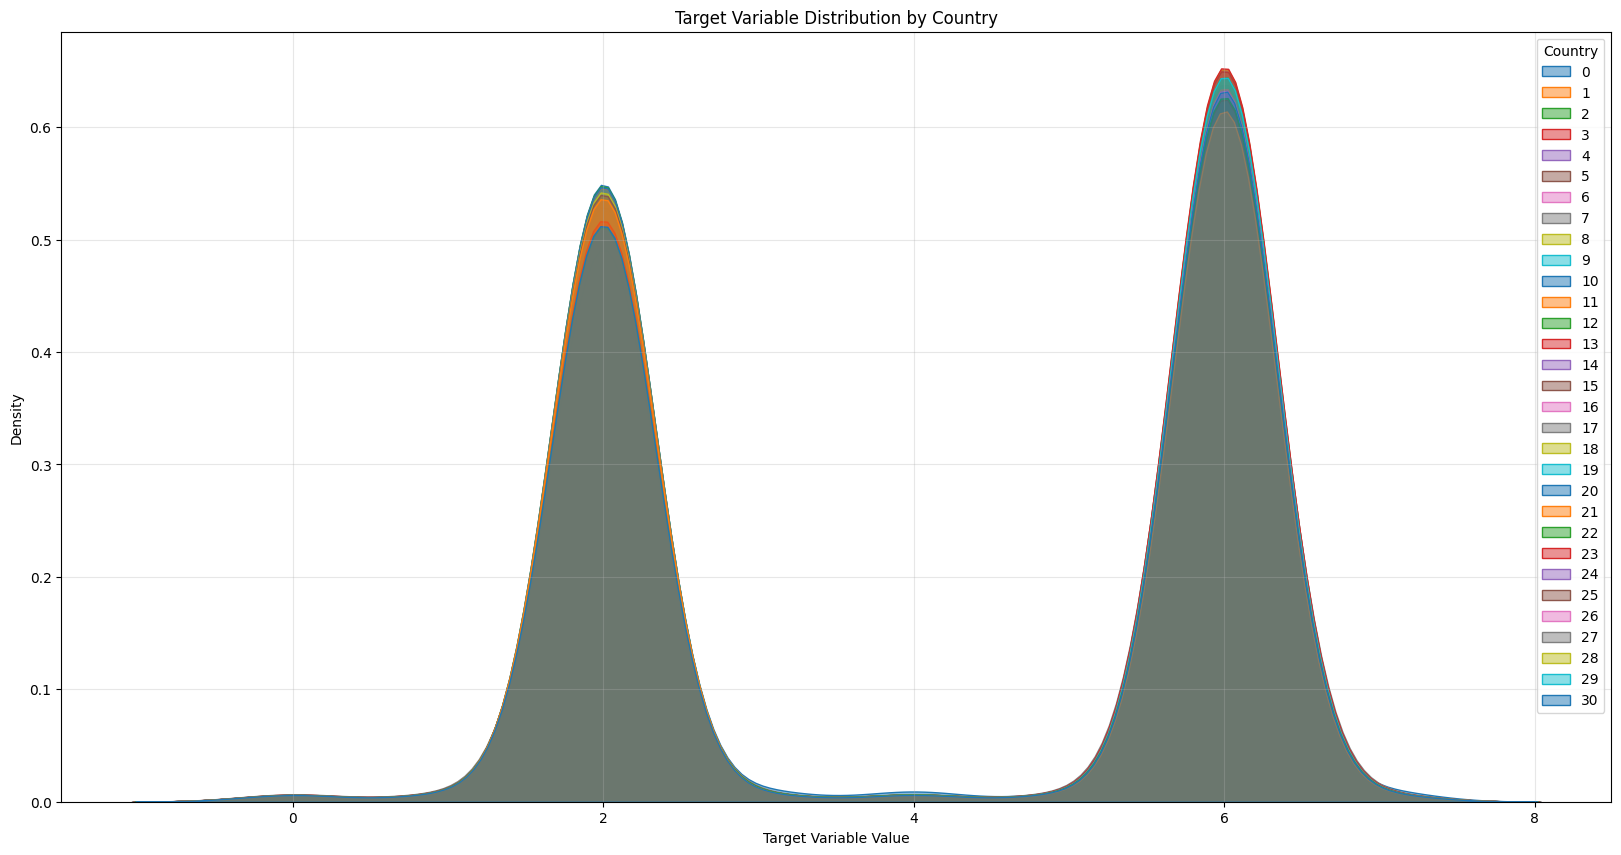

In [220]:
df_kde = df_final.copy()

plt.figure(figsize=(20, 10))
sns.kdeplot(data=df_kde, x="Target Variable", hue="Country", fill=True, 
            common_norm=False, alpha=0.5, palette="tab10")
plt.title("Target Variable Distribution by Country")
plt.xlabel("Target Variable Value")
plt.ylabel("Density")
plt.grid(True, alpha=0.3)
plt.show()

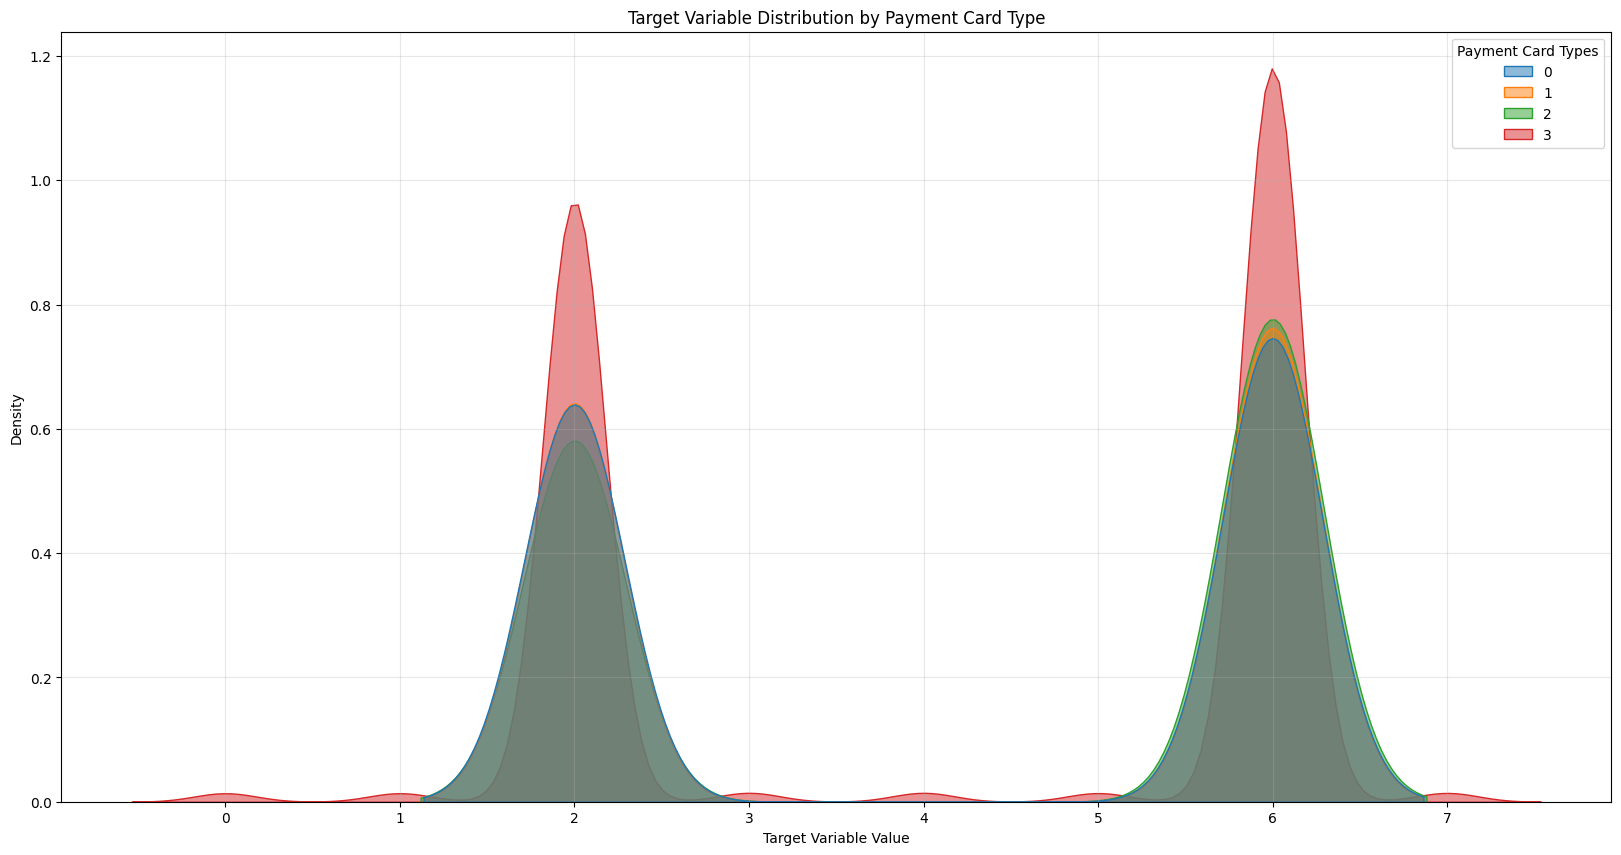

In [221]:
plt.figure(figsize=(20, 10))
sns.kdeplot(data=df_final, x="Target Variable", hue="Payment Card Types", 
            fill=True, common_norm=False, alpha=0.5, palette="tab10")
plt.title("Target Variable Distribution by Payment Card Type")
plt.xlabel("Target Variable Value")
plt.ylabel("Density")
plt.grid(True, alpha=0.3)
plt.show()

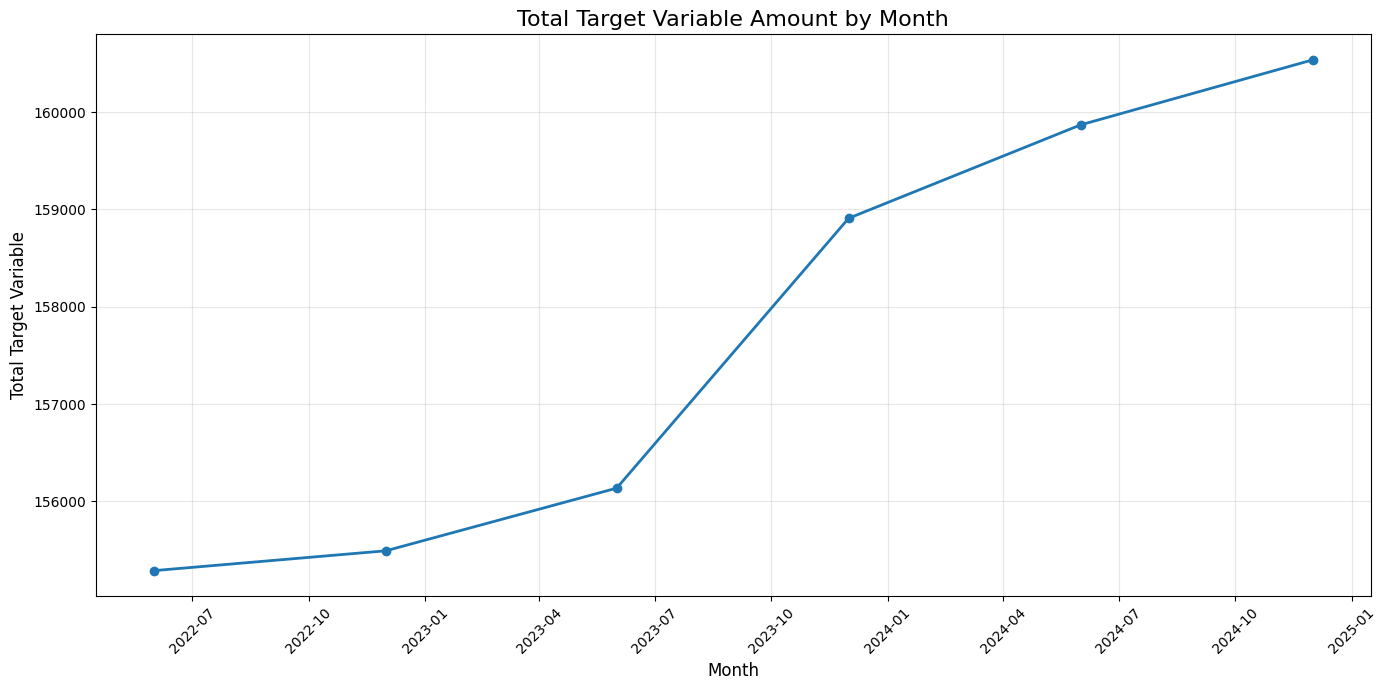

In [222]:
monthly_totals = df_final.groupby(["year", "month"])["Target Variable"].sum().reset_index()
monthly_totals["date"] = pd.to_datetime(monthly_totals["year"].astype(str) + "-" + monthly_totals["month"].astype(str) + "-01")

plt.figure(figsize=(14, 7))
plt.plot(monthly_totals["date"], monthly_totals["Target Variable"], marker="o", linewidth=2)
plt.title("Total Target Variable Amount by Month", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Target Variable", fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [223]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CONFIDENTIALITY FLAG  226678 non-null  int64  
 1   UNITS                 226678 non-null  int64  
 2   Country origin        226678 non-null  int64  
 3   Geographic Area       226678 non-null  int64  
 4   Country               226678 non-null  int64  
 5   Transaction Type      226678 non-null  int64  
 6   Transaction           226678 non-null  float64
 7   Transaction Channels  226678 non-null  int64  
 8   Transaction Decs      226678 non-null  int64  
 9   Payment scheme        226678 non-null  int64  
 10  Payment Card Types    226678 non-null  int64  
 11  SCA Classification    226678 non-null  int64  
 12  TRANSFORMATION DESC   226678 non-null  int64  
 13  UNIT MEASURE          226678 non-null  int64  
 14  year                  226678 non-null  int32  
 15  

### Data Understanding and EDA Enhancement ,Scaling, encoding and engineering feature

In [224]:
numeric_cols = df_final.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    skewness = df_final[col].skew()
    
    if abs(skewness) < 0.5:
        skew_text = "≈ Normal"
    elif 0.5 <= abs(skewness) < 1:
        skew_text = "Moderately skewed"
    elif abs(skewness) >= 1:
        skew_text = "Highly skewed"
    
    direction = "left" if skewness < 0 else "right"
    print(f"{col:<25} Skewness: {skewness:7.2f} ({direction}-skewed, {skew_text})")

CONFIDENTIALITY FLAG      Skewness:    0.38 (right-skewed, ≈ Normal)
UNITS                     Skewness:    0.00 (right-skewed, ≈ Normal)
Country origin            Skewness:    0.00 (right-skewed, ≈ Normal)
Geographic Area           Skewness:   -0.28 (left-skewed, ≈ Normal)
Country                   Skewness:    0.01 (right-skewed, ≈ Normal)
Transaction Type          Skewness:    2.85 (right-skewed, Highly skewed)
Transaction               Skewness:    0.39 (right-skewed, ≈ Normal)
Transaction Channels      Skewness:    0.51 (right-skewed, Moderately skewed)
Transaction Decs          Skewness:   -0.46 (left-skewed, ≈ Normal)
Payment scheme            Skewness:    0.00 (right-skewed, ≈ Normal)
Payment Card Types        Skewness:   -1.97 (left-skewed, Highly skewed)
SCA Classification        Skewness:   -1.26 (left-skewed, Highly skewed)
TRANSFORMATION DESC       Skewness:    0.00 (right-skewed, ≈ Normal)
UNIT MEASURE              Skewness:    0.00 (right-skewed, ≈ Normal)
year          

In [225]:
skewed = df_final.select_dtypes(include=np.number).apply(lambda x: x.skew())
for col in skewed[abs(skewed) > 1].index:
    shift = 1e-6 if df_final[col].min() >= 0 else abs(df_final[col].min()) + 1e-6
    df_final[f'{col}_log'] = np.log1p(df_final[col] + shift)
##this code reduces skewness by creating log-transformed versions of highly skewed columns.

In [226]:
numeric_cols = df_final.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    skewness = df_final[col].skew()
    
    if abs(skewness) < 0.5:
        skew_text = "≈ Normal"
    elif 0.5 <= abs(skewness) < 1:
        skew_text = "Moderately skewed"
    elif abs(skewness) >= 1:
        skew_text = "Highly skewed"
    
    direction = "left" if skewness < 0 else "right"
    print(f"{col:<25} Skewness: {skewness:7.2f} ({direction}-skewed, {skew_text})")

CONFIDENTIALITY FLAG      Skewness:    0.38 (right-skewed, ≈ Normal)
UNITS                     Skewness:    0.00 (right-skewed, ≈ Normal)
Country origin            Skewness:    0.00 (right-skewed, ≈ Normal)
Geographic Area           Skewness:   -0.28 (left-skewed, ≈ Normal)
Country                   Skewness:    0.01 (right-skewed, ≈ Normal)
Transaction Type          Skewness:    2.85 (right-skewed, Highly skewed)
Transaction               Skewness:    0.39 (right-skewed, ≈ Normal)
Transaction Channels      Skewness:    0.51 (right-skewed, Moderately skewed)
Transaction Decs          Skewness:   -0.46 (left-skewed, ≈ Normal)
Payment scheme            Skewness:    0.00 (right-skewed, ≈ Normal)
Payment Card Types        Skewness:   -1.97 (left-skewed, Highly skewed)
SCA Classification        Skewness:   -1.26 (left-skewed, Highly skewed)
TRANSFORMATION DESC       Skewness:    0.00 (right-skewed, ≈ Normal)
UNIT MEASURE              Skewness:    0.00 (right-skewed, ≈ Normal)
year          

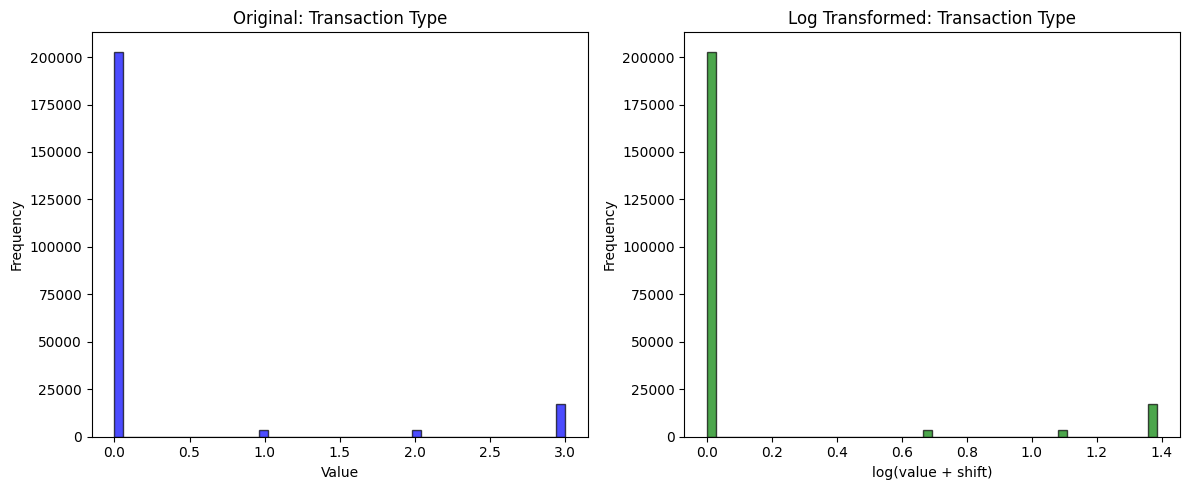

In [227]:
feature = "Transaction Type"   # or "UNITS" or any continuous column
log_feature = f"{feature}_log"

if feature in df_final.columns and log_feature in df_final.columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Histogram before transformation
    ax1.hist(df_final[feature].dropna(), bins=50, alpha=0.7, color='blue', edgecolor='black')
    ax1.set_title(f'Original: {feature}')
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Frequency")
    
    # Histogram after log transformation
    ax2.hist(df_final[log_feature].dropna(), bins=50, alpha=0.7, color='green', edgecolor='black')
    ax2.set_title(f'Log Transformed: {feature}')
    ax2.set_xlabel("log(value + shift)")
    ax2.set_ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Feature {feature} or {log_feature} not found in dataframe.")

In [228]:
feature = "Transaction Channels"   # or "UNITS" or any continuous column
log_feature = f"{feature}_log"

if feature in df_final.columns and log_feature in df_final.columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Histogram before transformation
    ax1.hist(df_final[feature].dropna(), bins=50, alpha=0.7, color='blue', edgecolor='black')
    ax1.set_title(f'Original: {feature}')
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Frequency")
    
    # Histogram after log transformation
    ax2.hist(df_final[log_feature].dropna(), bins=50, alpha=0.7, color='green', edgecolor='black')
    ax2.set_title(f'Log Transformed: {feature}')
    ax2.set_xlabel("log(value + shift)")
    ax2.set_ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Feature {feature} or {log_feature} not found in dataframe.")

Feature Transaction Channels or Transaction Channels_log not found in dataframe.


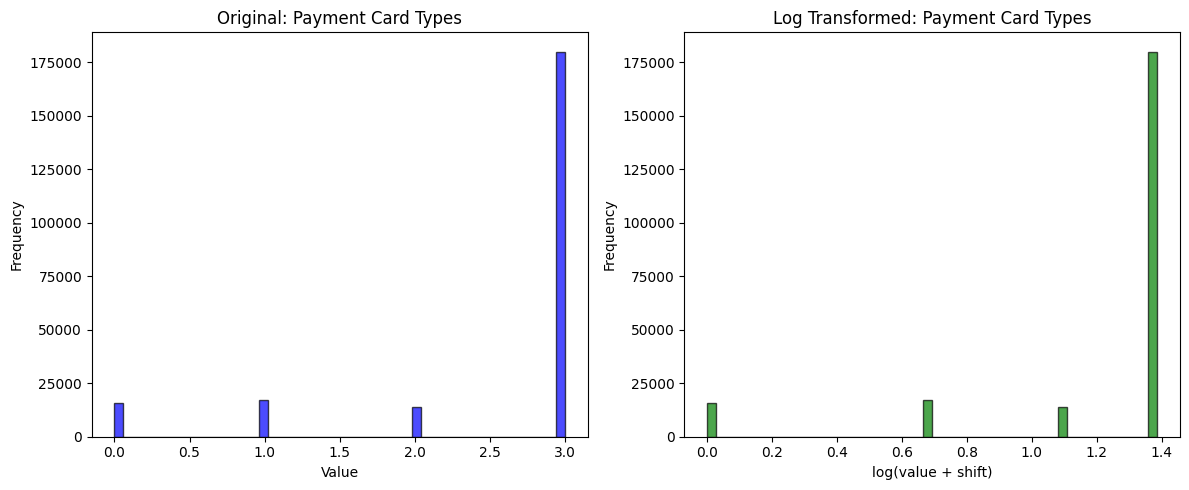

In [229]:

feature = "Payment Card Types"   # or "UNITS" or any continuous column
log_feature = f"{feature}_log"

if feature in df_final.columns and log_feature in df_final.columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Histogram before transformation
    ax1.hist(df_final[feature].dropna(), bins=50, alpha=0.7, color='blue', edgecolor='black')
    ax1.set_title(f'Original: {feature}')
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Frequency")
    
    # Histogram after log transformation
    ax2.hist(df_final[log_feature].dropna(), bins=50, alpha=0.7, color='green', edgecolor='black')
    ax2.set_title(f'Log Transformed: {feature}')
    ax2.set_xlabel("log(value + shift)")
    ax2.set_ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Feature {feature} or {log_feature} not found in dataframe.")

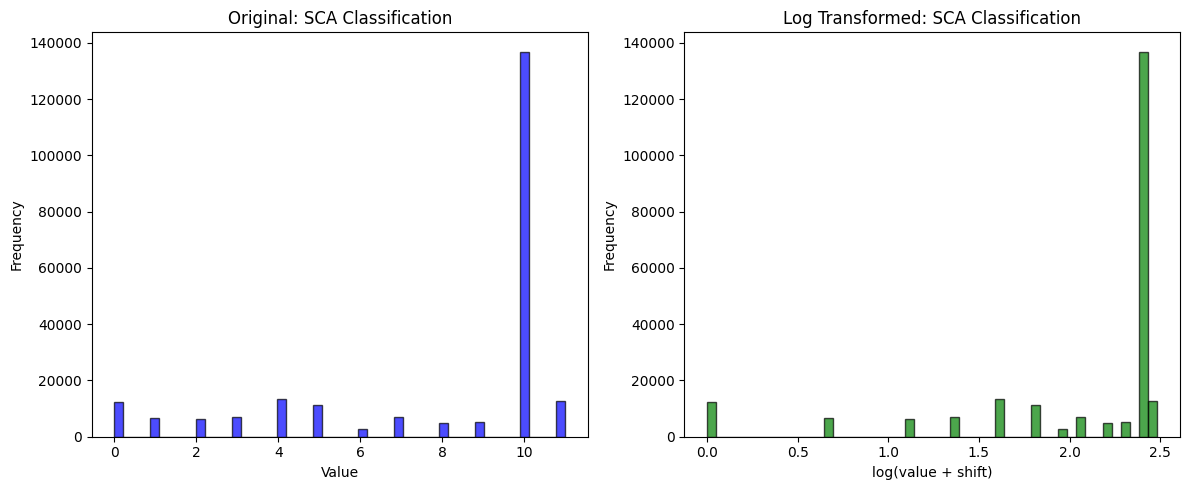

In [230]:

feature = "SCA Classification"   # or "UNITS" or any continuous column
log_feature = f"{feature}_log"

if feature in df_final.columns and log_feature in df_final.columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Histogram before transformation
    ax1.hist(df_final[feature].dropna(), bins=50, alpha=0.7, color='blue', edgecolor='black')
    ax1.set_title(f'Original: {feature}')
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Frequency")
    
    # Histogram after log transformation
    ax2.hist(df_final[log_feature].dropna(), bins=50, alpha=0.7, color='green', edgecolor='black')
    ax2.set_title(f'Log Transformed: {feature}')
    ax2.set_xlabel("log(value + shift)")
    ax2.set_ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Feature {feature} or {log_feature} not found in dataframe.")

In [231]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 22 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   CONFIDENTIALITY FLAG    226678 non-null  int64  
 1   UNITS                   226678 non-null  int64  
 2   Country origin          226678 non-null  int64  
 3   Geographic Area         226678 non-null  int64  
 4   Country                 226678 non-null  int64  
 5   Transaction Type        226678 non-null  int64  
 6   Transaction             226678 non-null  float64
 7   Transaction Channels    226678 non-null  int64  
 8   Transaction Decs        226678 non-null  int64  
 9   Payment scheme          226678 non-null  int64  
 10  Payment Card Types      226678 non-null  int64  
 11  SCA Classification      226678 non-null  int64  
 12  TRANSFORMATION DESC     226678 non-null  int64  
 13  UNIT MEASURE            226678 non-null  int64  
 14  year                

In [232]:
df_final.shape

(226678, 22)

In [233]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = [
    "CONFIDENTIALITY FLAG", "Country origin", "Geographic Area", "Country",
    "Transaction Type", "Transaction Channels", "Transaction Decs", "Payment scheme",
    "Payment Card Types", "SCA Classification", "TRANSFORMATION DESC", "UNIT MEASURE"
]


categorical_cols = [col for col in categorical_cols if col in df_final.columns]

# one-hot encoding
encoder = OneHotEncoder(drop="first", sparse_output=False)
encoded_array = encoder.fit_transform(df_final[categorical_cols])

# Create a DataFrame with encoded columns
encoded_cols = encoder.get_feature_names_out(categorical_cols)
encoded_df = pd.DataFrame(encoded_array, columns=encoded_cols, index=df_final.index)


df_final = df_final.drop(columns=categorical_cols)
df_final = pd.concat([df_final, encoded_df], axis=1)

print(f"One-hot encoding complete. New shape: {df_final.shape}")
print(f"Added {len(encoded_cols)} dummy columns.")

One-hot encoding complete. New shape: (226678, 72)
Added 62 dummy columns.


In [234]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226678 entries, 0 to 226677
Data columns (total 72 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   UNITS                   226678 non-null  int64  
 1   Transaction             226678 non-null  float64
 2   year                    226678 non-null  int32  
 3   month                   226678 non-null  int32  
 4   quarter                 226678 non-null  int32  
 5   day                     226678 non-null  int32  
 6   Target Variable         226678 non-null  int64  
 7   Transaction Type_log    226678 non-null  float64
 8   Payment Card Types_log  226678 non-null  float64
 9   SCA Classification_log  226678 non-null  float64
 10  CONFIDENTIALITY FLAG_1  226678 non-null  float64
 11  Geographic Area_1       226678 non-null  float64
 12  Geographic Area_2       226678 non-null  float64
 13  Geographic Area_3       226678 non-null  float64
 14  Geographic Area_4   

In [235]:
df_final.describe()

,UNITS,Transaction,year,month,quarter,day,Target Variable,Transaction Type_log,Payment Card Types_log,SCA Classification_log,...,SCA Classification_3,SCA Classification_4,SCA Classification_5,SCA Classification_6,SCA Classification_7,SCA Classification_8,SCA Classification_9,SCA Classification_10,SCA Classification_11,UNIT MEASURE_1
count,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,...,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000,226678.00000
mean,0.00000,-0.00000,2023.01129,9.01263,3.00421,30.50210,4.17435,0.13118,1.21946,2.05620,...,0.03069,0.05901,0.04915,0.01280,0.03115,0.02187,0.02386,0.60412,0.05577,0.50000
std,0.00000,1.00000,0.81680,2.99998,0.99999,0.50000,2.00677,0.39110,0.38494,0.65004,...,0.17247,0.23564,0.21619,0.11242,0.17371,0.14627,0.15261,0.48904,0.22948,0.50000
min,0.00000,-0.82256,2022.00000,6.00000,2.00000,30.00000,0.00000,0.00000,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
25%,0.00000,-0.82256,2022.00000,6.00000,2.00000,30.00000,2.00000,0.00000,1.38629,1.79176,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
50%,0.00000,-0.82256,2023.00000,12.00000,4.00000,31.00000,6.00000,0.00000,1.38629,2.39790,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.50000
75%,0.00000,1.21571,2024.00000,12.00000,4.00000,31.00000,6.00000,0.00000,1.38629,2.39790,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,1.00000
max,0.00000,1.21571,2024.00000,12.00000,4.00000,31.00000,7.00000,1.38629,1.38629,2.48491,...,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000


### Linear Discriminant and PCA

In [236]:
continuous_cols = ["UNITS", "Transaction", "year", "month", "quarter", "day"]
continuous_cols = [c for c in continuous_cols if c in df_final.columns]

# 2. All other non-target columns are dummy/one-hot
dummy_cols = [c for c in df_final.columns if c not in continuous_cols + ["Target Variable"]]

print(f"Continuous features: {len(continuous_cols)}")
print(f"Dummy features: {len(dummy_cols)}")

# 3. Preprocessor: scale EVERYTHING (both continuous and dummies)
preprocessor = ColumnTransformer([
    ("scaler", StandardScaler(), continuous_cols + dummy_cols)
])

# 4. PCA pipeline
pca_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("pca", PCA(n_components=0.95, random_state=42))
])

# 5. Split
X = df_final.drop(columns=["Target Variable"])
y = df_final["Target Variable"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Fit and transform
X_train_pca = pca_pipeline.fit_transform(X_train)
X_test_pca = pca_pipeline.transform(X_test)

print(f"Training PCA shape: {X_train_pca.shape}")
print(f"Explained variance ratio: {pca_pipeline.named_steps['pca'].explained_variance_ratio_.sum():.3f}")

Continuous features: 6
Dummy features: 65
Training PCA shape: (181342, 55)
Explained variance ratio: 0.959


In [237]:
bad_log_cols = ["Transaction Type_log", "Payment Card Types_log", "SCA Classification_log"]
df_final = df_final.drop(columns=[col for col in bad_log_cols if col in df_final.columns])

In [238]:
X = df_final.drop(columns=["Target Variable"])
y = df_final["Target Variable"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Original shape: {X_scaled.shape}")


Original shape: (226678, 68)


In [239]:
pca = PCA(n_components=14, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"After PCA (14 components): {X_pca.shape}")

After PCA (14 components): (226678, 14)


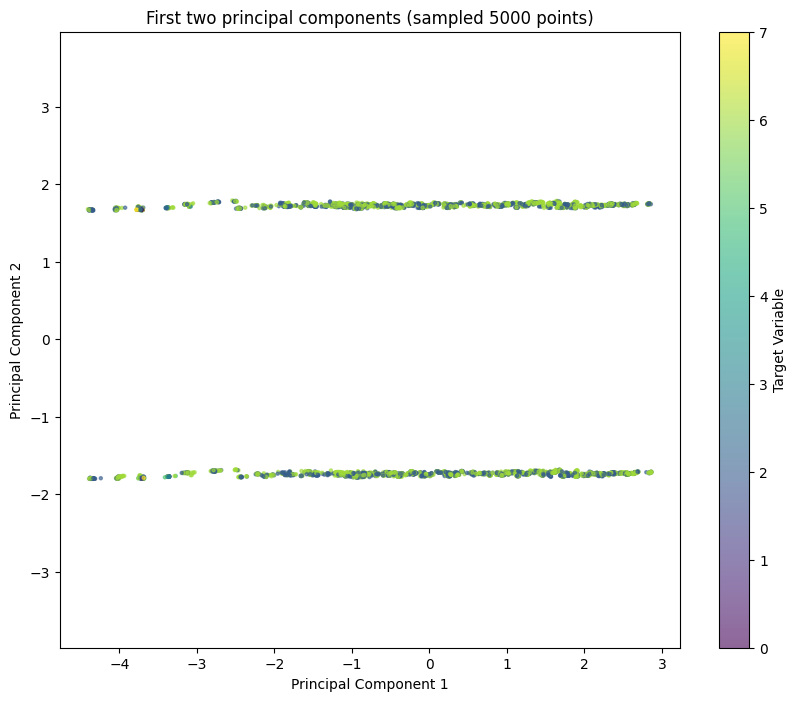

In [240]:
sample_size = min(5000, X_pca.shape[0])
rng = np.random.RandomState(1)
indices = rng.choice(X_pca.shape[0], sample_size, replace=False)
X_sample = X_pca[indices]
y_sample = y.iloc[indices]  # optional: color by target

plt.figure(figsize=(10, 8))
plt.scatter(X_sample[:, 0], X_sample[:, 1], c=y_sample, cmap="viridis", alpha=0.6, s=5)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"First two principal components (sampled {sample_size} points)")
plt.colorbar(label="Target Variable")
plt.axis("equal")
plt.show()

In [241]:
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_pca)

# Inverse transform back to 14 components (not original space yet)
X_14_reconstructed = pca_2d.inverse_transform(X_2d)

# Inverse transform back to original feature space (scaled)
X_reconstructed_scaled = pca.inverse_transform(X_14_reconstructed)

(np.float64(-0.05500000000000001),
 np.float64(0.05500000000000001),
 np.float64(-0.9244782729523809),
 np.float64(1.3176238042578428))

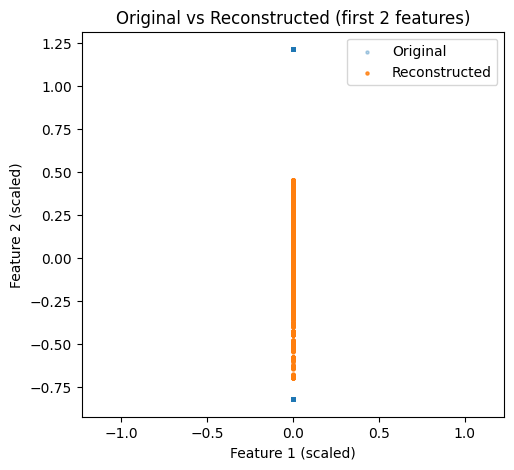

In [242]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_scaled[indices, 0], X_scaled[indices, 1], alpha=0.3, s=5, label="Original")
plt.scatter(X_reconstructed_scaled[indices, 0], X_reconstructed_scaled[indices, 1], alpha=0.8, s=5, label="Reconstructed")
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.title("Original vs Reconstructed (first 2 features)")
plt.legend()
plt.axis("equal")

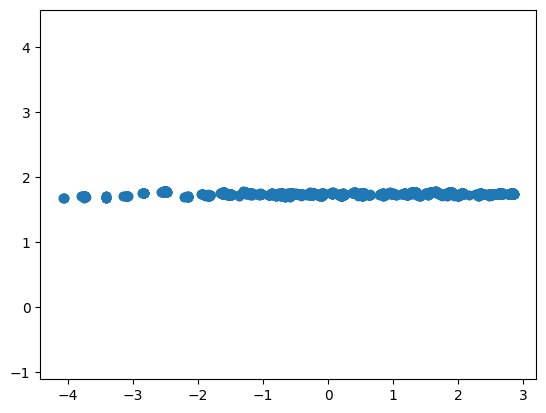

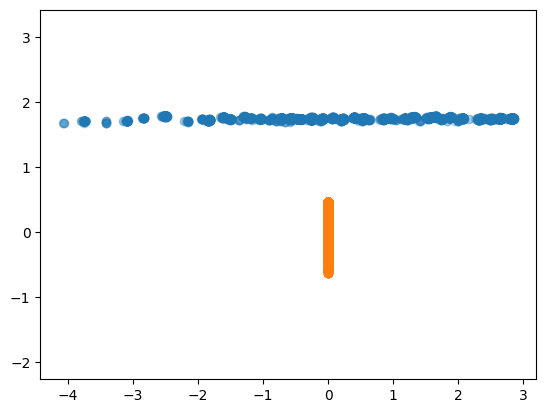

In [243]:
pca = PCA(n_components=14)
X_pca = pca.fit_transform(X_scaled)

rng = np.random.RandomState(1)
X = X_pca
plt.scatter(X[:5000, 0], X[:5000, 1]) 
plt.axis("equal")
plt.show()

pca_2d = PCA(n_components=2) 
X_2d = pca_2d.fit_transform(X_pca)
X_new = pca_2d.inverse_transform(X_2d)

X_new = pca.inverse_transform(X_new) 
plt.scatter(X[:5000, 0], X[:5000, 1], alpha=0.2) 
plt.scatter(X_new[:5000, 0], X_new[:5000, 1], alpha=0.8) 
plt.axis("equal")
plt.show()

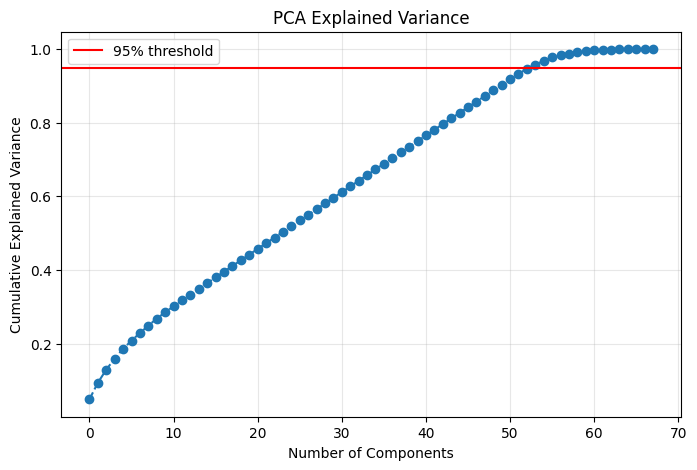

Number of components needed to explain 95% variance: 54


In [244]:
pca_full = PCA().fit(X_scaled)

plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker="o", linestyle="--")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True, alpha=0.3)
plt.axhline(y=0.95, color='r', linestyle='-', label='95% threshold')
plt.legend()
plt.show()

# Print how many components to reach 95%
n_95 = np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.95) + 1
print(f"Number of components needed to explain 95% variance: {n_95}")

In [245]:
pca_final = PCA(n_components=54, random_state=42)
X_projected = pca_final.fit_transform(X_scaled)

# Create DataFrame with PCA components
pca_columns = [f"C{i+1}" for i in range(X_projected.shape[1])]
df_pca = pd.DataFrame(X_projected, columns=pca_columns)

# Add your target variable
df_pca["Target Variable"] = y.values

# View results
print(df_pca.head(10))
print(f"\nTotal explained variance by 54 components: {pca_final.explained_variance_ratio_.sum():.2%}")
print(f"Original features: {X_scaled.shape[1]} → PCA components: {X_projected.shape[1]}")

        C1      C2       C3      C4       C5      C6      C7      C8      C9  \
0 -1.82881 1.72608 -0.83905 1.06061 -0.59674 0.83004 2.39799 0.22414 0.03367   
1 -1.82906 1.72606 -0.83889 1.06090 -0.59526 0.82906 2.39517 0.22411 0.03361   
2 -1.82881 1.72608 -0.83905 1.06061 -0.59674 0.83004 2.39799 0.22414 0.03367   
3 -1.82906 1.72606 -0.83889 1.06090 -0.59526 0.82906 2.39517 0.22411 0.03361   
4 -1.03986 1.74291  0.17974 1.09782 -2.45863 2.37178 0.74749 0.16653 0.02249   
5 -1.04011 1.74289  0.17990 1.09811 -2.45715 2.37079 0.74467 0.16649 0.02244   
6 -1.03986 1.74291  0.17974 1.09782 -2.45863 2.37178 0.74749 0.16653 0.02249   
7 -1.04011 1.74289  0.17990 1.09811 -2.45715 2.37079 0.74467 0.16649 0.02244   
8 -0.40884 1.73813 -0.42496 1.51239 -3.00788 1.90097 0.46094 0.15791 0.01124   
9 -0.40909 1.73811 -0.42481 1.51268 -3.00640 1.89998 0.45811 0.15787 0.01119   

      C10  ...      C46      C47      C48      C49      C50      C51      C52  \
0 1.19159  ... -0.11366  0.06246 -0.22

In [246]:
X = df_pca.drop(columns=["Target Variable"])
y = df_pca["Target Variable"]

# Split (stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Class distribution:\n{y.value_counts(normalize=True)}")

Training set: (181342, 54)
Test set: (45336, 54)
Class distribution:
Target Variable
6   0.53343
2   0.43665
3   0.00510
4   0.00509
7   0.00503
5   0.00495
1   0.00489
0   0.00487
Name: proportion, dtype: float64


In [247]:
from sklearn.svm import LinearSVC
models = {
    "Logistic Regression": LogisticRegression(solver='saga', max_iter=1000, random_state=42, n_jobs=-1),
    "Linear SVM": LinearSVC(max_iter=5000, dual='auto', random_state=42, C=1.0),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42)
}

In [248]:
import time
print("\n" + "="*60)
print("5-Fold Cross-Validation on Training Set")
print("="*60)

results = {}
for name, model in models.items():
    print(f"\nTraining {name}...", end=" ", flush=True)
    start = time.time()
    
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    elapsed = time.time() - start
    
    results[name] = scores
    print(f"done in {elapsed:.1f}s")
    print(f"  Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")


5-Fold Cross-Validation on Training Set

Training Logistic Regression... done in 431.1s
  Accuracy: 0.5302 (+/- 0.0013)

Training Linear SVM... done in 176.6s
  Accuracy: 0.5297 (+/- 0.0016)

Training Random Forest... done in 276.7s
  Accuracy: 0.4923 (+/- 0.0026)


In [249]:
print("\n" + "="*60)
print("Test Set Evaluation")
print("="*60)

best_models = {}
for name, model in models.items():
    print(f"\nFitting {name} on full training set...", end=" ", flush=True)
    start = time.time()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    elapsed = time.time() - start
    print(f"done in {elapsed:.1f}s")
    print(f"  Test Accuracy: {acc:.4f}")
    best_models[name] = model


Test Set Evaluation

Fitting Logistic Regression on full training set... done in 474.7s
  Test Accuracy: 0.5267

Fitting Linear SVM on full training set... done in 150.9s
  Test Accuracy: 0.5257

Fitting Random Forest on full training set... done in 70.8s
  Test Accuracy: 0.4591



Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.14      0.31      0.19       221
           1       0.12      0.14      0.13       222
           2       0.48      0.21      0.29     19796
           3       0.19      0.09      0.12       231
           4       0.09      0.01      0.02       231
           5       0.13      0.17      0.14       224
           6       0.55      0.81      0.66     24183
           7       0.09      0.03      0.04       228

    accuracy                           0.53     45336
   macro avg       0.22      0.22      0.20     45336
weighted avg       0.51      0.53      0.48     45336



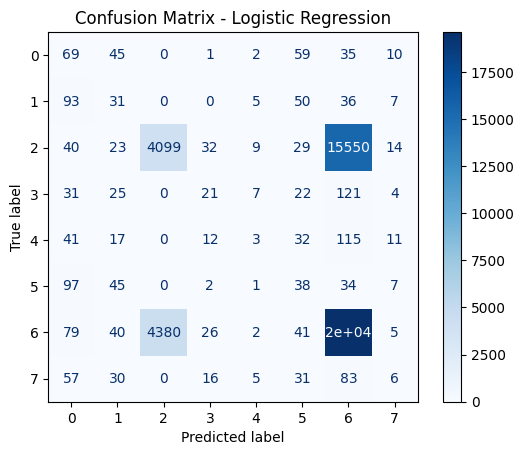

In [250]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
best_name = max(best_models, key=lambda name: accuracy_score(y_test, best_models[name].predict(X_test)))
best_model = best_models[best_name]
y_pred_best = best_model.predict(X_test)

print("\n" + "="*60)
print(f"Best Model: {best_name}")
print("="*60)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

C:\Users\kramo\AppData\Local\Temp\ipykernel_13896\3304014973.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores, positions=[list(results.keys()).index(name)], labels=[name])
C:\Users\kramo\AppData\Local\Temp\ipykernel_13896\3304014973.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores, positions=[list(results.keys()).index(name)], labels=[name])
C:\Users\kramo\AppData\Local\Temp\ipykernel_13896\3304014973.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores, positions=[list(results.keys()).index(name)], labels=[name])


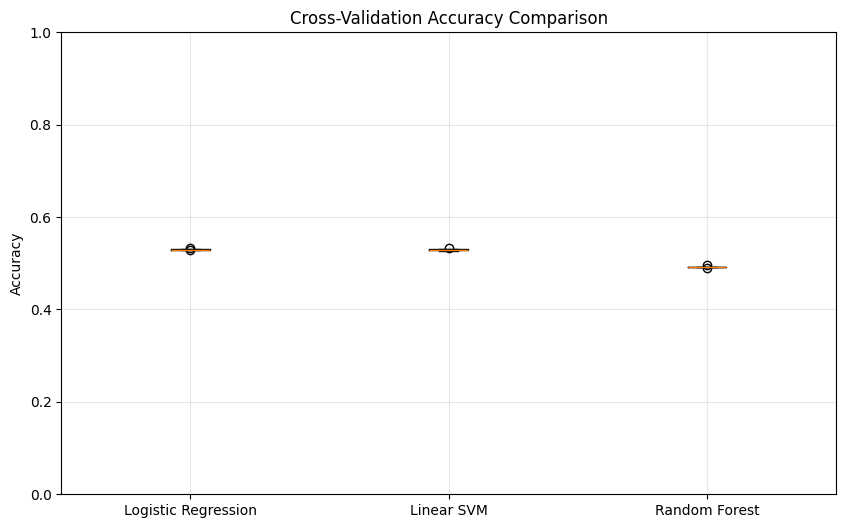

In [251]:
plt.figure(figsize=(10, 6))
for name, scores in results.items():
    plt.boxplot(scores, positions=[list(results.keys()).index(name)], labels=[name])
plt.title("Cross-Validation Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

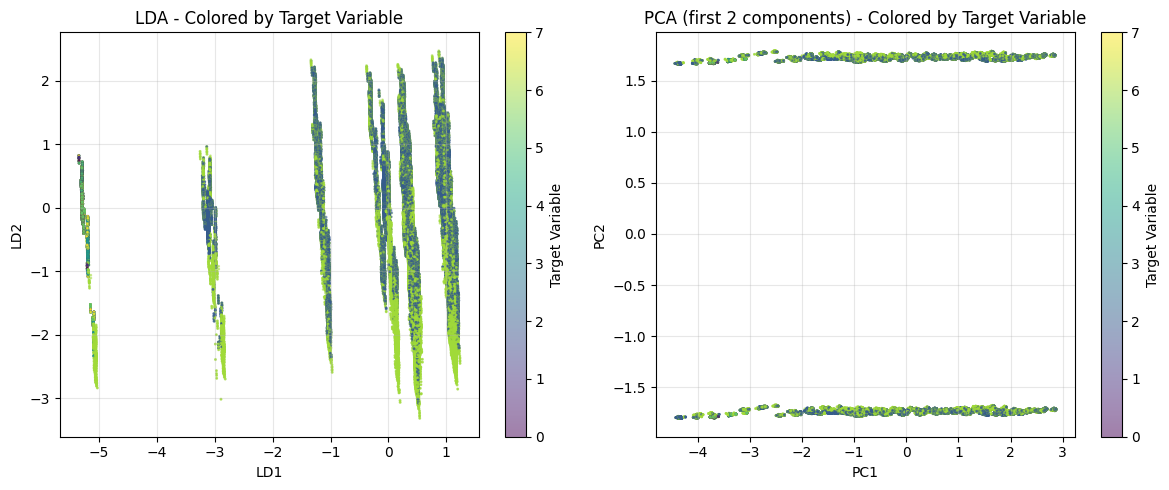

In [252]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y) 

# ---------- PCA: recompute with 2 components for fair comparison ----------
from sklearn.decomposition import PCA
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)   # unsupervised

# ---------- Plot side by side ----------
plt.figure(figsize=(12, 5))

# LDA plot (supervised)
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y, cmap="viridis", alpha=0.5, s=1)
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA - Colored by Target Variable")
plt.colorbar(scatter1, label="Target Variable")
plt.grid(True, alpha=0.3)

# PCA plot (unsupervised, first 2 components)
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap="viridis", alpha=0.5, s=1)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA (first 2 components) - Colored by Target Variable")
plt.colorbar(scatter2, label="Target Variable")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Machine learning

In [253]:
##LogisticRegression
X = X_scaled   
y = df_final["Target Variable"]   

# Train/test split 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=25, stratify=y
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Target distribution:\n{y.value_counts(normalize=True)}")

# ------------------------------------------------------------
# Train Logistic Regression 
# ------------------------------------------------------------
model = LogisticRegression(solver="saga", max_iter=1000, 
                           class_weight="balanced",  
                           random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))


Training set: (181342, 68)
Test set: (45336, 68)
Target distribution:
Target Variable
6   0.53343
2   0.43665
3   0.00510
4   0.00509
7   0.00503
5   0.00495
1   0.00489
0   0.00487
Name: proportion, dtype: float64
              precision    recall  f1-score   support

           0       0.33      0.02      0.03       221
           1       0.50      0.06      0.10       222
           2       0.51      0.63      0.56     19796
           3       0.17      0.14      0.15       231
           4       0.22      0.02      0.03       231
           5       0.17      0.54      0.26       224
           6       0.63      0.49      0.55     24183
           7       0.13      0.56      0.21       228

    accuracy                           0.54     45336
   macro avg       0.33      0.31      0.24     45336
weighted avg       0.57      0.54      0.54     45336



C:\Users\kramo\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



Confusion Matrix:
[[    4     6     0     2     0   112     0    97]
 [    2    13     0     2     0   108     0    97]
 [    0     0 12473    36     2    60  7064   161]
 [    0     0     0    32     2    57     0   140]
 [    0     0     0    26     4    63     0   138]
 [    3     5     0     3     0   121     0    92]
 [    3     2 11947    70    10   102 11922   127]
 [    0     0     0    20     0    80     0   128]]


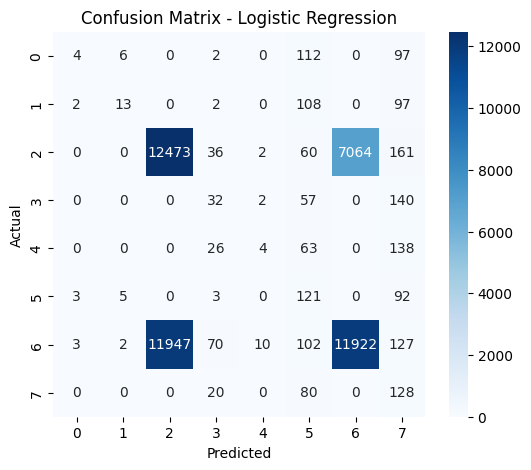

In [254]:
# Evaluation
print("\n" + "="*50)
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [255]:
# Accuracy and detailed report
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.5448

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.02      0.03       221
           1       0.50      0.06      0.10       222
           2       0.51      0.63      0.56     19796
           3       0.17      0.14      0.15       231
           4       0.22      0.02      0.03       231
           5       0.17      0.54      0.26       224
           6       0.63      0.49      0.55     24183
           7       0.13      0.56      0.21       228

    accuracy                           0.54     45336
   macro avg       0.33      0.31      0.24     45336
weighted avg       0.57      0.54      0.54     45336



In [256]:
y_pred = model.predict(X_test)

result_df = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
result_df.head(20)

,Actual,Predicted
0,2,2
1,6,2
2,6,6
3,2,2
4,2,6
5,2,2
6,6,2
7,6,6
8,2,2
9,2,2


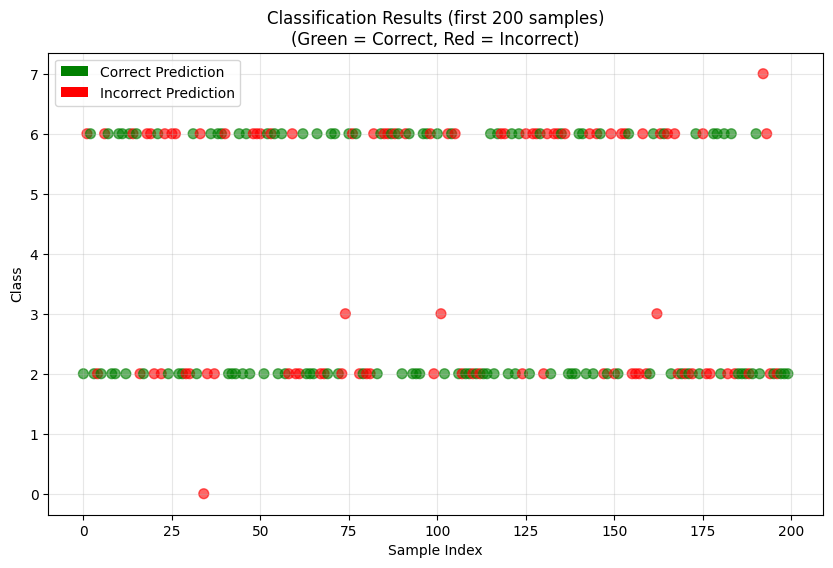

In [257]:
from matplotlib.patches import Patch

unique_classes = sorted(result_df["Actual"].unique())

plt.figure(figsize=(10, 6))

# Color: green if correct, red if incorrect
colors = ["green" if actual == predicted else "red" 
          for actual, predicted in zip(result_df["Actual"], result_df["Predicted"])]


sample_size = min(200, len(result_df))
sample_indices = range(sample_size)

plt.scatter(sample_indices, result_df["Actual"].iloc[:sample_size], 
           c=colors[:sample_size], alpha=0.6, s=50, label="Predictions")
plt.xlabel("Sample Index")
plt.ylabel("Class")
plt.title("Classification Results (first {} samples)\n(Green = Correct, Red = Incorrect)".format(sample_size))
plt.yticks(unique_classes)

# Legend
legend_elements = [Patch(facecolor="green", label="Correct Prediction"),
                   Patch(facecolor="red", label="Incorrect Prediction")]
plt.legend(handles=legend_elements)

plt.grid(True, alpha=0.3)
plt.show()

In [258]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, max_depth=20,
                               class_weight='balanced',  # optional but helps
                               n_jobs=-1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.01      0.02      0.01       221
           1       0.00      0.00      0.00       222
           2       0.47      0.52      0.49     19796
           3       0.03      0.03      0.03       231
           4       0.00      0.00      0.00       231
           5       0.00      0.01      0.01       224
           6       0.57      0.51      0.54     24183
           7       0.01      0.00      0.01       228

    accuracy                           0.50     45336
   macro avg       0.14      0.14      0.14     45336
weighted avg       0.51      0.50      0.50     45336



In [259]:
import xgboost as xgb

X = X_scaled   # your scaled feature matrix
y = df_final["Target Variable"]   # your target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = xgb.XGBClassifier(
    n_estimators=100,          # number of trees
    max_depth=6,               # depth of each tree
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=None,     # XGBoost automatically handles if set 'weight' in fit
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss"     # for multi-class
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)

XGBoost Results
Accuracy: 0.6205

Classification Report:
              precision    recall  f1-score   support

           0       0.06      0.11      0.08       221
           1       0.10      0.14      0.12       222
           2       0.63      0.47      0.54     19796
           3       0.14      0.05      0.07       231
           4       0.04      0.01      0.02       231
           5       0.06      0.10      0.08       224
           6       0.64      0.78      0.70     24183
           7       0.04      0.00      0.01       228

    accuracy                           0.62     45336
   macro avg       0.21      0.21      0.20     45336
weighted avg       0.62      0.62      0.61     45336



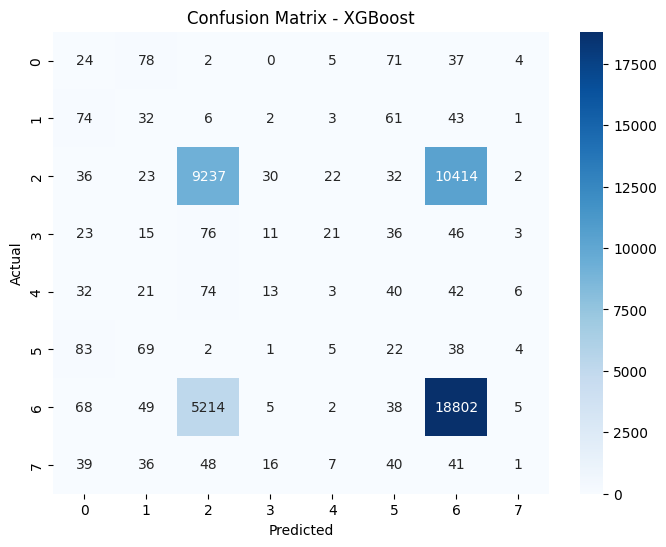

In [260]:
print("="*60)
print("XGBoost Results")
print("="*60)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}\n")

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost")
plt.show()


In [288]:
from sklearn.utils.class_weight import compute_sample_weight

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# Compute sample weights (balanced)
sample_weights = compute_sample_weight("balanced", y_train)

# Create XGBoost model
model = xgb.XGBClassifier(n_estimators=100, max_depth=6, random_state=42, n_jobs=-1)

# Pass sample_weights into fit
model.fit(X_train, y_train, sample_weight=sample_weights)

# Then predict and evaluate
y_pred = model.predict(X_test)

In [262]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

# Classification report (precision, recall, f1-score per class)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Optional: feature importances
importance = model.feature_importances_
print("\nTop 5 feature importances:")
for i in importance.argsort()[-5:][::-1]:
    print(f"  Feature {i}: {importance[i]:.4f}")

Accuracy: 0.6139

Classification Report:
              precision    recall  f1-score   support

           0       0.02      0.03      0.02       221
           1       0.01      0.02      0.02       222
           2       0.58      0.70      0.63     19796
           3       0.03      0.03      0.03       231
           4       0.02      0.03      0.03       231
           5       0.01      0.01      0.01       224
           6       0.71      0.58      0.64     24183
           7       0.00      0.00      0.00       228

    accuracy                           0.61     45336
   macro avg       0.17      0.18      0.17     45336
weighted avg       0.63      0.61      0.62     45336

Confusion Matrix:
[[    7    88     0    14    27    44     0    41]
 [   88     5     0    18    31    51     0    29]
 [   48    34 13865    48    49    16  5703    33]
 [   33    34     0     8   101     7     0    48]
 [   46    37     0    80     7    19     0    42]
 [   68    77     0    14    30    

### Resampling

In [263]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from collections import Counter

# Check current class distribution
print("Original class distribution:", Counter(y))

# Define SMOTE (oversample minority classes to a target ratio)
# For multi-class, set a dict: e.g., make all classes have same count as the majority?
# Or use SMOTE with sampling_strategy='auto' (balances to the majority class count)
smote = SMOTE(sampling_strategy='auto', random_state=42)   # 'auto' works for multi-class

# Under‑sample majority classes (optional, can use 'auto' to balance to minority)
under = RandomUnderSampler(sampling_strategy='auto', random_state=42)

# Pipeline: first oversample, then undersample
pipeline = ImbPipeline([('smote', smote), ('under', under)])

# Resample
X_resampled, y_resampled = pipeline.fit_resample(X_scaled, y)

print("Resampled class distribution:", Counter(y_resampled))

Original class distribution: Counter({6: 120916, 2: 98978, 3: 1156, 4: 1154, 7: 1140, 5: 1122, 1: 1108, 0: 1104})


C:\Users\kramo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\kramo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\kramo\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\kramo\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Resampled class distribution: Counter({0: 120916, 1: 120916, 2: 120916, 3: 120916, 4: 120916, 5: 120916, 6: 120916, 7: 120916})


In [264]:
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled
)

model = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


print(classification_report(y_test, y_pred))
y_pred = model.predict(X_test)

# 1. Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.21      0.54      0.31     24183
           1       0.24      0.27      0.26     24183
           2       0.58      0.56      0.57     24183
           3       0.40      0.40      0.40     24184
           4       0.42      0.14      0.21     24183
           5       0.25      0.22      0.23     24183
           6       0.57      0.58      0.58     24184
           7       0.53      0.12      0.20     24183

    accuracy                           0.35    193466
   macro avg       0.40      0.35      0.34    193466
weighted avg       0.40      0.35      0.34    193466

Accuracy: 0.3522

Classification Report:
              precision    recall  f1-score   support

           0       0.21      0.54      0.31     24183
           1       0.24      0.27      0.26     24183
           2       0.58      0.56      0.57     24183
           3       0.40      0.40      0.40     24184
           4       0.42      0.14    

In [265]:
from imblearn.ensemble import BalancedRandomForestClassifier

model = BalancedRandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)   # use original X_scaled, y (no resampling)
y_pred = model.predict(X_test)

In [266]:
from sklearn.metrics import balanced_accuracy_score
balanced_acc = balanced_accuracy_score(y_test, y_pred)
print(f"Balanced Accuracy: {balanced_acc:.4f}")

Balanced Accuracy: 0.3289


In [267]:
balanced_acc = balanced_accuracy_score(y_test, y_pred)
print(f"Balanced Accuracy: {balanced_acc:.4f}")

# Macro F1 (average F1 across classes)
from sklearn.metrics import f1_score
macro_f1 = f1_score(y_test, y_pred, average='macro')
print(f"Macro F1: {macro_f1:.4f}")

# Per‑class metrics (look at recall for minority classes)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Balanced Accuracy: 0.3289
Macro F1: 0.3289

Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.26      0.26     24183
           1       0.25      0.25      0.25     24183
           2       0.47      0.47      0.47     24183
           3       0.31      0.31      0.31     24184
           4       0.30      0.31      0.30     24183
           5       0.26      0.26      0.26     24183
           6       0.48      0.48      0.48     24184
           7       0.30      0.29      0.29     24183

    accuracy                           0.33    193466
   macro avg       0.33      0.33      0.33    193466
weighted avg       0.33      0.33      0.33    193466



In [268]:
from imblearn.ensemble import BalancedRandomForestClassifier

model = BalancedRandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)   # use original imbalanced train set (X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")

              precision    recall  f1-score   support

           0       0.26      0.26      0.26     24183
           1       0.25      0.25      0.25     24183
           2       0.47      0.47      0.47     24183
           3       0.31      0.31      0.31     24184
           4       0.30      0.31      0.30     24183
           5       0.26      0.26      0.26     24183
           6       0.48      0.48      0.48     24184
           7       0.30      0.29      0.29     24183

    accuracy                           0.33    193466
   macro avg       0.33      0.33      0.33    193466
weighted avg       0.33      0.33      0.33    193466

Balanced Accuracy: 0.3289


In [269]:
y_simplified = y.copy()
rare_classes = [0,1,3,4,5,7]
y_simplified = y_simplified.replace(rare_classes, 8)

In [270]:
#conda install -c conda-forge lightgbm

In [271]:
import lightgbm as lgb
model = lgb.LGBMClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.073814 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2401
[LightGBM] [Info] Number of data points in the train set: 773862, number of used features: 67
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442


LGBMClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [272]:
y_pred = model.predict(X_test)

# 1. Simple accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

# 2. Balanced accuracy (better for imbalanced data)
bal_acc = balanced_accuracy_score(y_test, y_pred)
print(f"Balanced Accuracy: {bal_acc:.4f}")

# 3. Full classification report (precision, recall, f1 per class)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.3802
Balanced Accuracy: 0.3802

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.45      0.32     24183
           1       0.21      0.39      0.27     24183
           2       0.71      0.60      0.65     24183
           3       0.39      0.29      0.34     24184
           4       0.38      0.22      0.28     24183
           5       0.26      0.16      0.20     24183
           6       0.66      0.74      0.70     24184
           7       0.44      0.18      0.25     24183

    accuracy                           0.38    193466
   macro avg       0.41      0.38      0.38    193466
weighted avg       0.41      0.38      0.38    193466



In [273]:
import pandas as pd
result_df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print(result_df.head(20))

        Actual  Predicted
676503       5          0
834109       6          6
3770         0          1
947573       7          3
476512       3          5
136614       1          5
784537       6          6
149633       1          0
512187       4          1
910404       7          0
784231       6          6
924437       7          0
536829       4          1
578810       4          4
908998       7          1
179034       1          3
751363       6          2
846587       7          0
263608       2          2
453920       3          1


In [274]:
# Create simplified target (3 classes)
y_simple = y.copy()
rare_classes = [0,1,3,4,5,7]
y_simple = y_simple.replace(rare_classes, 8)  # 8 represents "Other"

print(y_simple.value_counts())

Target Variable
6    120916
2     98978
8      6784
Name: count, dtype: int64


In [275]:
import lightgbm as lgb

model = lgb.LGBMClassifier(n_estimators=100, class_weight='balanced', 
                           random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.093463 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2401
[LightGBM] [Info] Number of data points in the train set: 773862, number of used features: 67
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442
[LightGBM] [Info] Start training from score -2.079442


LGBMClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [276]:
y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.3802
Balanced Accuracy: 0.3802

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.45      0.32     24183
           1       0.21      0.39      0.27     24183
           2       0.71      0.60      0.65     24183
           3       0.39      0.29      0.34     24184
           4       0.38      0.22      0.28     24183
           5       0.26      0.16      0.20     24183
           6       0.66      0.74      0.70     24184
           7       0.44      0.18      0.25     24183

    accuracy                           0.38    193466
   macro avg       0.41      0.38      0.38    193466
weighted avg       0.41      0.38      0.38    193466



In [277]:
print("Original class distribution:")
print(y.value_counts())

# Simplify
y_simple = y.copy()
rare_classes = [0,1,3,4,5,7]
y_simple = y_simple.replace(rare_classes, 8)

print("\nSimplified class distribution:")
print(y_simple.value_counts())

Original class distribution:
Target Variable
6    120916
2     98978
3      1156
4      1154
7      1140
5      1122
1      1108
0      1104
Name: count, dtype: int64

Simplified class distribution:
Target Variable
6    120916
2     98978
8      6784
Name: count, dtype: int64


In [278]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_simple, test_size=0.2, random_state=42, stratify=y_simple
)

# Check training distribution
print("\nTraining set distribution:")
print(pd.Series(y_train).value_counts())


Training set distribution:
Target Variable
6    96733
2    79182
8     5427
Name: count, dtype: int64


In [279]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))

model = lgb.LGBMClassifier(class_weight=class_weight_dict, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024545 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 202
[LightGBM] [Info] Number of data points in the train set: 181342, number of used features: 67
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612


LGBMClassifier(class_weight={np.int64(2): np.float64(0.7633974051341635),
                             np.int64(6): np.float64(0.6248884386231517),
                             np.int64(8): np.float64(11.138259320680548)},
               n_jobs=-1, random_state=42)

In [280]:
# Predict on test set
y_pred = model.predict(X_test)

# 1. Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

# 2. Balanced Accuracy (better for imbalanced data)
bal_acc = balanced_accuracy_score(y_test, y_pred)
print(f"Balanced Accuracy: {bal_acc:.4f}")

# 3. Detailed classification report (precision, recall, f1-score per class)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 4. Confusion matrix 
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

import pandas as pd
result_df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print("\nFirst 20 predictions:")
print(result_df.head(20))

Accuracy: 0.6447
Balanced Accuracy: 0.7617

Classification Report:
              precision    recall  f1-score   support

           2       0.58      0.73      0.65     19796
           6       0.73      0.55      0.63     24183
           8       0.74      1.00      0.85      1357

    accuracy                           0.64     45336
   macro avg       0.68      0.76      0.71     45336
weighted avg       0.66      0.64      0.64     45336


Confusion Matrix:
[[14474  5076   246]
 [10547 13399   237]
 [    0     0  1357]]

First 20 predictions:
        Actual  Predicted
131417       6          6
109598       6          6
193074       6          2
139047       2          6
87479        6          2
133004       6          2
8638         6          6
220817       2          2
24720        2          2
131422       2          2
8275         6          2
144163       2          2
180776       2          6
114982       2          6
218634       6          2
132161       6          6
1314

In [281]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           2       0.58      0.73      0.65     19796
           6       0.73      0.55      0.63     24183
           8       0.74      1.00      0.85      1357

    accuracy                           0.64     45336
   macro avg       0.68      0.76      0.71     45336
weighted avg       0.66      0.64      0.64     45336



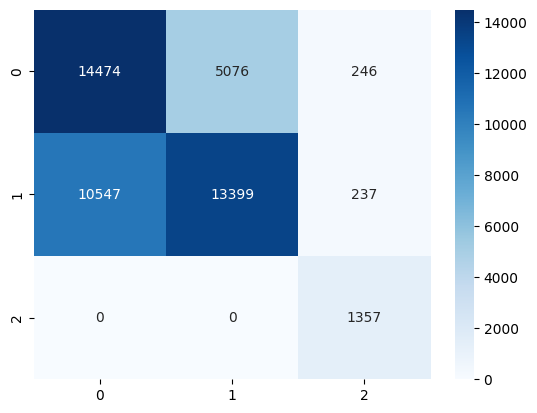

In [282]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.show()

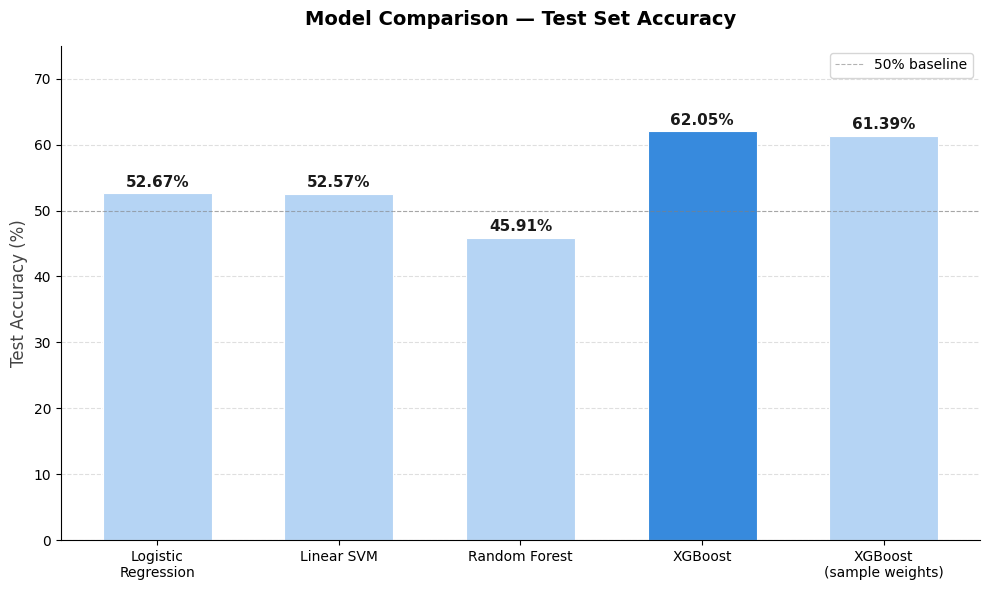

In [292]:
models = [
    "Logistic\nRegression",
    "Linear SVM",
    "Random Forest",
    "XGBoost",
    "XGBoost\n(sample weights)"
]

accuracies = [52.67, 52.57, 45.91, 62.05, 61.39]

colors = ["#378ADD" if acc == max(accuracies) else "#B5D4F4" for acc in accuracies]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(models, accuracies, color=colors, edgecolor="white", linewidth=0.8, width=0.6)

for bar, acc in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{acc:.2f}%",
        ha="center", va="bottom",
        fontsize=11, fontweight="bold", color="#1a1a1a"
    )

ax.set_ylim(0, 75)
ax.set_ylabel("Test Accuracy (%)", fontsize=12, color="#444")
ax.set_title("Model Comparison — Test Set Accuracy", fontsize=14, fontweight="bold", pad=15)
ax.axhline(y=50, color="gray", linestyle="--", linewidth=0.8, alpha=0.6, label="50% baseline")
ax.legend(fontsize=10)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()